Nested Random Intercepts in `multibart` — Mechanism Test

Tristan Muno [ORCID profile for Tristan Muno](https://orcid.org/0009-0002-3078-8436) (University of Mannheim)  
Vera Okisheva (University of Mannheim)  
Raphael Klöckner (University of Mannheim)  
October 19, 2026

# Purpose

This notebook is a **scaffold**, not a finished analysis. Its job is to test the nested-random-intercept extension added to the local `multibart` package (functions `nested_random_intercepts()` and `get_nested_random_intercepts_posteriors()` in `code/multibart/R/groups.R`).

The goals, in priority order, are:

1.  **Verify the modified `multibart` works in principle.** On *synthetic* two-level data with known variance components we confirm the new helper builds a valid random-effects design, that the continuous fitting path (`bcf_continuous_linear`) accepts it and runs, and that the posterior extractor returns correctly-shaped, correctly-labelled output that recovers the planted structure.
2.  **See what the output looks like and how to process it downstream.** We fit on a small subsample of the real data with **country-only** random intercepts and walk the posterior objects through to the tidy summaries and figures the manuscript will need; respondent dependence is handled separately by a cluster bootstrap (see @sec-subsample).

> **Why nesting fits the existing sampler**
>
> The C++ MCMC sampler is already general over an arbitrary number of variance components `K` and an arbitrary random-effects design matrix `W` — it reads the dimensions off its inputs at runtime. A nested respondent-within-country intercept model is just `W = [D_country | D_resp]` with a block-structured `q × 2` component-assignment matrix `Q` giving each grouping factor its own variance component. Because respondent ids are globally unique, this dummy coding *is* nesting (each respondent dummy belongs to exactly one country). This is the same `q × 2` mechanism `random_intercepts_slopes()` already uses for intercept + slope; we only swap the two blocks for two grouping factors.

> **Cost resolved the design: country-only REs on the real data**
>
> `W` is `n × (C + R)`, and the sampler forms `Phi = adj·WtW·adj` densely and Cholesky-solves it every Gibbs sweep — an `O(q³)` cost in `q = C + R` that is dominated by the respondent dummies (`R` in the tens of thousands). A 10k-row real-data subsample took over 20 minutes to reach iteration 1; at full scale the cubic term explodes, so the **nested respondent-within-country fit is infeasible** in this project window (resolving CLAUDE.md Open Question #1). The correctness story is unchanged — the synthetic section below still exercises the full two-level mechanism, where the dimensions are tiny and the dense solve is trivial. But the **real-data path adopts the documented fallback: country random intercepts only** (`q ≈ 25`, the RE block becomes negligible), with within-respondent dependence across the three conjoint tasks handled by a respondent cluster bootstrap (explained in @sec-subsample).

# Setup

The setup chunk loads the usual project packages the normal way, including `multibart`’s own dependencies (`Rcpp`, `RcppArmadillo`, `Rcereal`, `fastDummies`), so they are installed and attached before the local package is touched.

In [ ]:
# execution time
start_time <- Sys.time()
# console width
options(width = 80)
# packages
p_required <- c(
  "tidyverse", # dplyr, ggplot2, tidyr
  "here", # relative paths
  "ggpubr", # theme_pubr
  "patchwork", # multi-panel figure
  "sessioninfo", # session docs
  "future", # future/furrr: run MCMC chains in parallel across cores
  "furrr", # future/furrr: run MCMC chains in parallel across cores
  "posterior", # posterior: R-hat / ESS diagnostics

  # multibart dependencies -----------------------------------------------------
  "Rcpp", # multibart Depends + LinkingTo
  "RcppArmadillo", # multibart Depends + LinkingTo
  "Rcereal", # multibart Depends + LinkingTo
  "fastDummies" # multibart helper dependency
)
packages <- rownames(installed.packages())
p_to_install <- p_required[!(p_required %in% packages)]
if (length(p_to_install) > 0) {
  install.packages(p_to_install)
}
sapply(p_required, require, character.only = TRUE)


Loading required package: tidyverse

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: here

here() starts at C:/R/research/MBEU25

Loading required package: ggpubr

Loading required package: patchwork

Loading required package: sessioninfo

Loading required package: future

Loading required package: furrr

Loading required package: posterior

This is posterior version 1.6.1


Attaching package: 'posterior'


The following objects are masked from 'package:stats':

    mad, sd, var


The following objects are masked from 'package:ba

    tidyverse          here        ggpubr     patchwork   sessioninfo 
         TRUE          TRUE          TRUE          TRUE          TRUE 
       future         furrr     posterior          Rcpp RcppArmadillo 
         TRUE          TRUE          TRUE          TRUE          TRUE 
      Rcereal   fastDummies 
         TRUE          TRUE 

## Local multibart package

`multibart` lives only as source under `code/multibart`; it is not on CRAN. Loading it with `pkgload::load_all()` puts it in memory but not on `.libPaths()` — fine interactively, but it breaks under `quarto render`, where instantiating its Rcpp module (`tree_samples`) calls `library("multibart")` and fails because no *installed* copy exists. So we install the local source once (compiling its C++), then attach it with `library()` like any other package — robust for both interactive use and rendering.

In [ ]:
# install local source on first use
if (!requireNamespace("multibart", quietly = TRUE)) {
  install.packages(
    here::here("code", "multibart"),
    repos = NULL,
    type = "source"
  )
}
# attach installed package
library(multibart)


> **Note**
>
> The chunk above only auto-installs when the package is *missing*, not when its source changes. After editing `multibart`’s C++ or R code, reinstall to pick it up: `install.packages(here::here("code", "multibart"), repos = NULL, type = "source")`.

# Synthetic mechanism check

This is the primary test. We generate data from a known additive two-level model so that we control the truth and can check the machinery end-to-end.

## Simulate two-level data

The design mirrors the real structure: respondents nested in countries, several conjoint tasks each, with treatment randomized at a known propensity of 0.5 (the conjoint design) so no propensity model is needed. The two random-intercept variances are deliberately distinct (`sigma_country` well above `sigma_resp`) — recovering that separation is the key check — and the dimensions are small so the dense `WtW` solve is trivial. Per-quantity detail is in the chunk comments below.

A correct fit should recover a heterogeneous `tau(x)`: a clean `0.75` contrast between the two levels of the binary `x3`, a mean-zero nonlinear (sine) wiggle in the continuous `x4`, flatness in the two null moderators `x1`/`x2`, the linear `mu(x)` shape in `x1`/`x2`, and two clearly separated variance components with `sigma_country` (1.5) above `sigma_resp` (0.5).

In [ ]:
set.seed(20260602)

# dimensions: 8 countries x 25 respondents x 3 tasks = 600 rows
n_country <- 8
n_resp_per_country <- 25
n_task <- 3

# nested ids; respondent ids are globally unique, so each sits in one country
# (dummy coding that is nesting, not crossing)
country_id <- factor(rep(
  seq_len(n_country),
  each = n_resp_per_country * n_task
))
resp_id <- factor(rep(seq_len(n_country * n_resp_per_country), each = n_task))
n <- length(resp_id)

# planted variance components, country spread deliberately >> respondent spread
sigma_country <- 1.5
sigma_resp <- 0.5
# group offsets: per-country and per-respondent baseline shifts (nuisance)
b_country <- rnorm(n_country, 0, sigma_country)
b_resp <- rnorm(nlevels(resp_id), 0, sigma_resp)

# covariates: candidate moderators a real analysis would split on
p <- 4
X <- matrix(rnorm(n * p), nrow = n)
colnames(X) <- paste0("x", seq_len(p))
# x3: binary dummy, a randomized binary conjoint-attribute stand-in
X[, 3] <- rbinom(n, 1, 0.5)
# prognostic (control) surface: linear in x1/x2, flat in x3/x4
mu_x <- 1.0 * X[, 1] - 0.5 * X[, 2]
# x4: mean-zero nonlinear (sine) moderator
g_x4 <- 0.4 * sin(1.5 * X[, 4])
# heterogeneous effect: x3 binary contrast (0.75) + x4 sine (average ~0.875)
tau_x <- 0.5 + 0.75 * X[, 3] + g_x4

# randomized treatment, known propensity 0.5
z <- rbinom(n, 1, 0.5)

# linear predictor: prognostic + effect-on-treated + nested intercepts (mu only)
lin_pred <- mu_x +
  tau_x * z +
  b_country[as.integer(country_id)] +
  b_resp[as.integer(resp_id)]

# continuous outcome: linear predictor + residual noise (SD 1)
y_cont <- lin_pred + rnorm(n, 0, 1)


A `stopifnot()` guards the nesting invariant — every respondent must sit in exactly one country — and the basic dimensions.

In [ ]:
# each respondent maps to exactly one country
resp_country_map <- tapply(as.integer(country_id), resp_id, function(v) {
  length(unique(v))
})
stopifnot(
  all(resp_country_map == 1),
  length(y_cont) == n,
  nrow(X) == n,
  all(sort(unique(z)) == c(0, 1)),
  all(X[, 3] %in% c(0, 1)), # x3 is a binary dummy
  is.numeric(X[, 4]), # x4 stays continuous
  !anyNA(tau_x),
  abs(mean(g_x4)) < 0.05 # x4 sine is mean-zero: ATE preserved
)


## Planted truth by moderator

Before any model sees the data, this figure shows the planted truth directly: the true per-observation treatment effect against each candidate moderator. The two null moderators `x1` and `x2` should read flat; the binary `x3` should show a clean two-level jump of about `0.75`; the continuous `x4` should trace a mean-zero sine. Continuous panels show alpha-blended individual truths with a ten-bin mean curve and a covariate rug; the binary `x3` panel shows its two level means. The common y-axis lets the flat nulls be read against the active moderators at a glance.

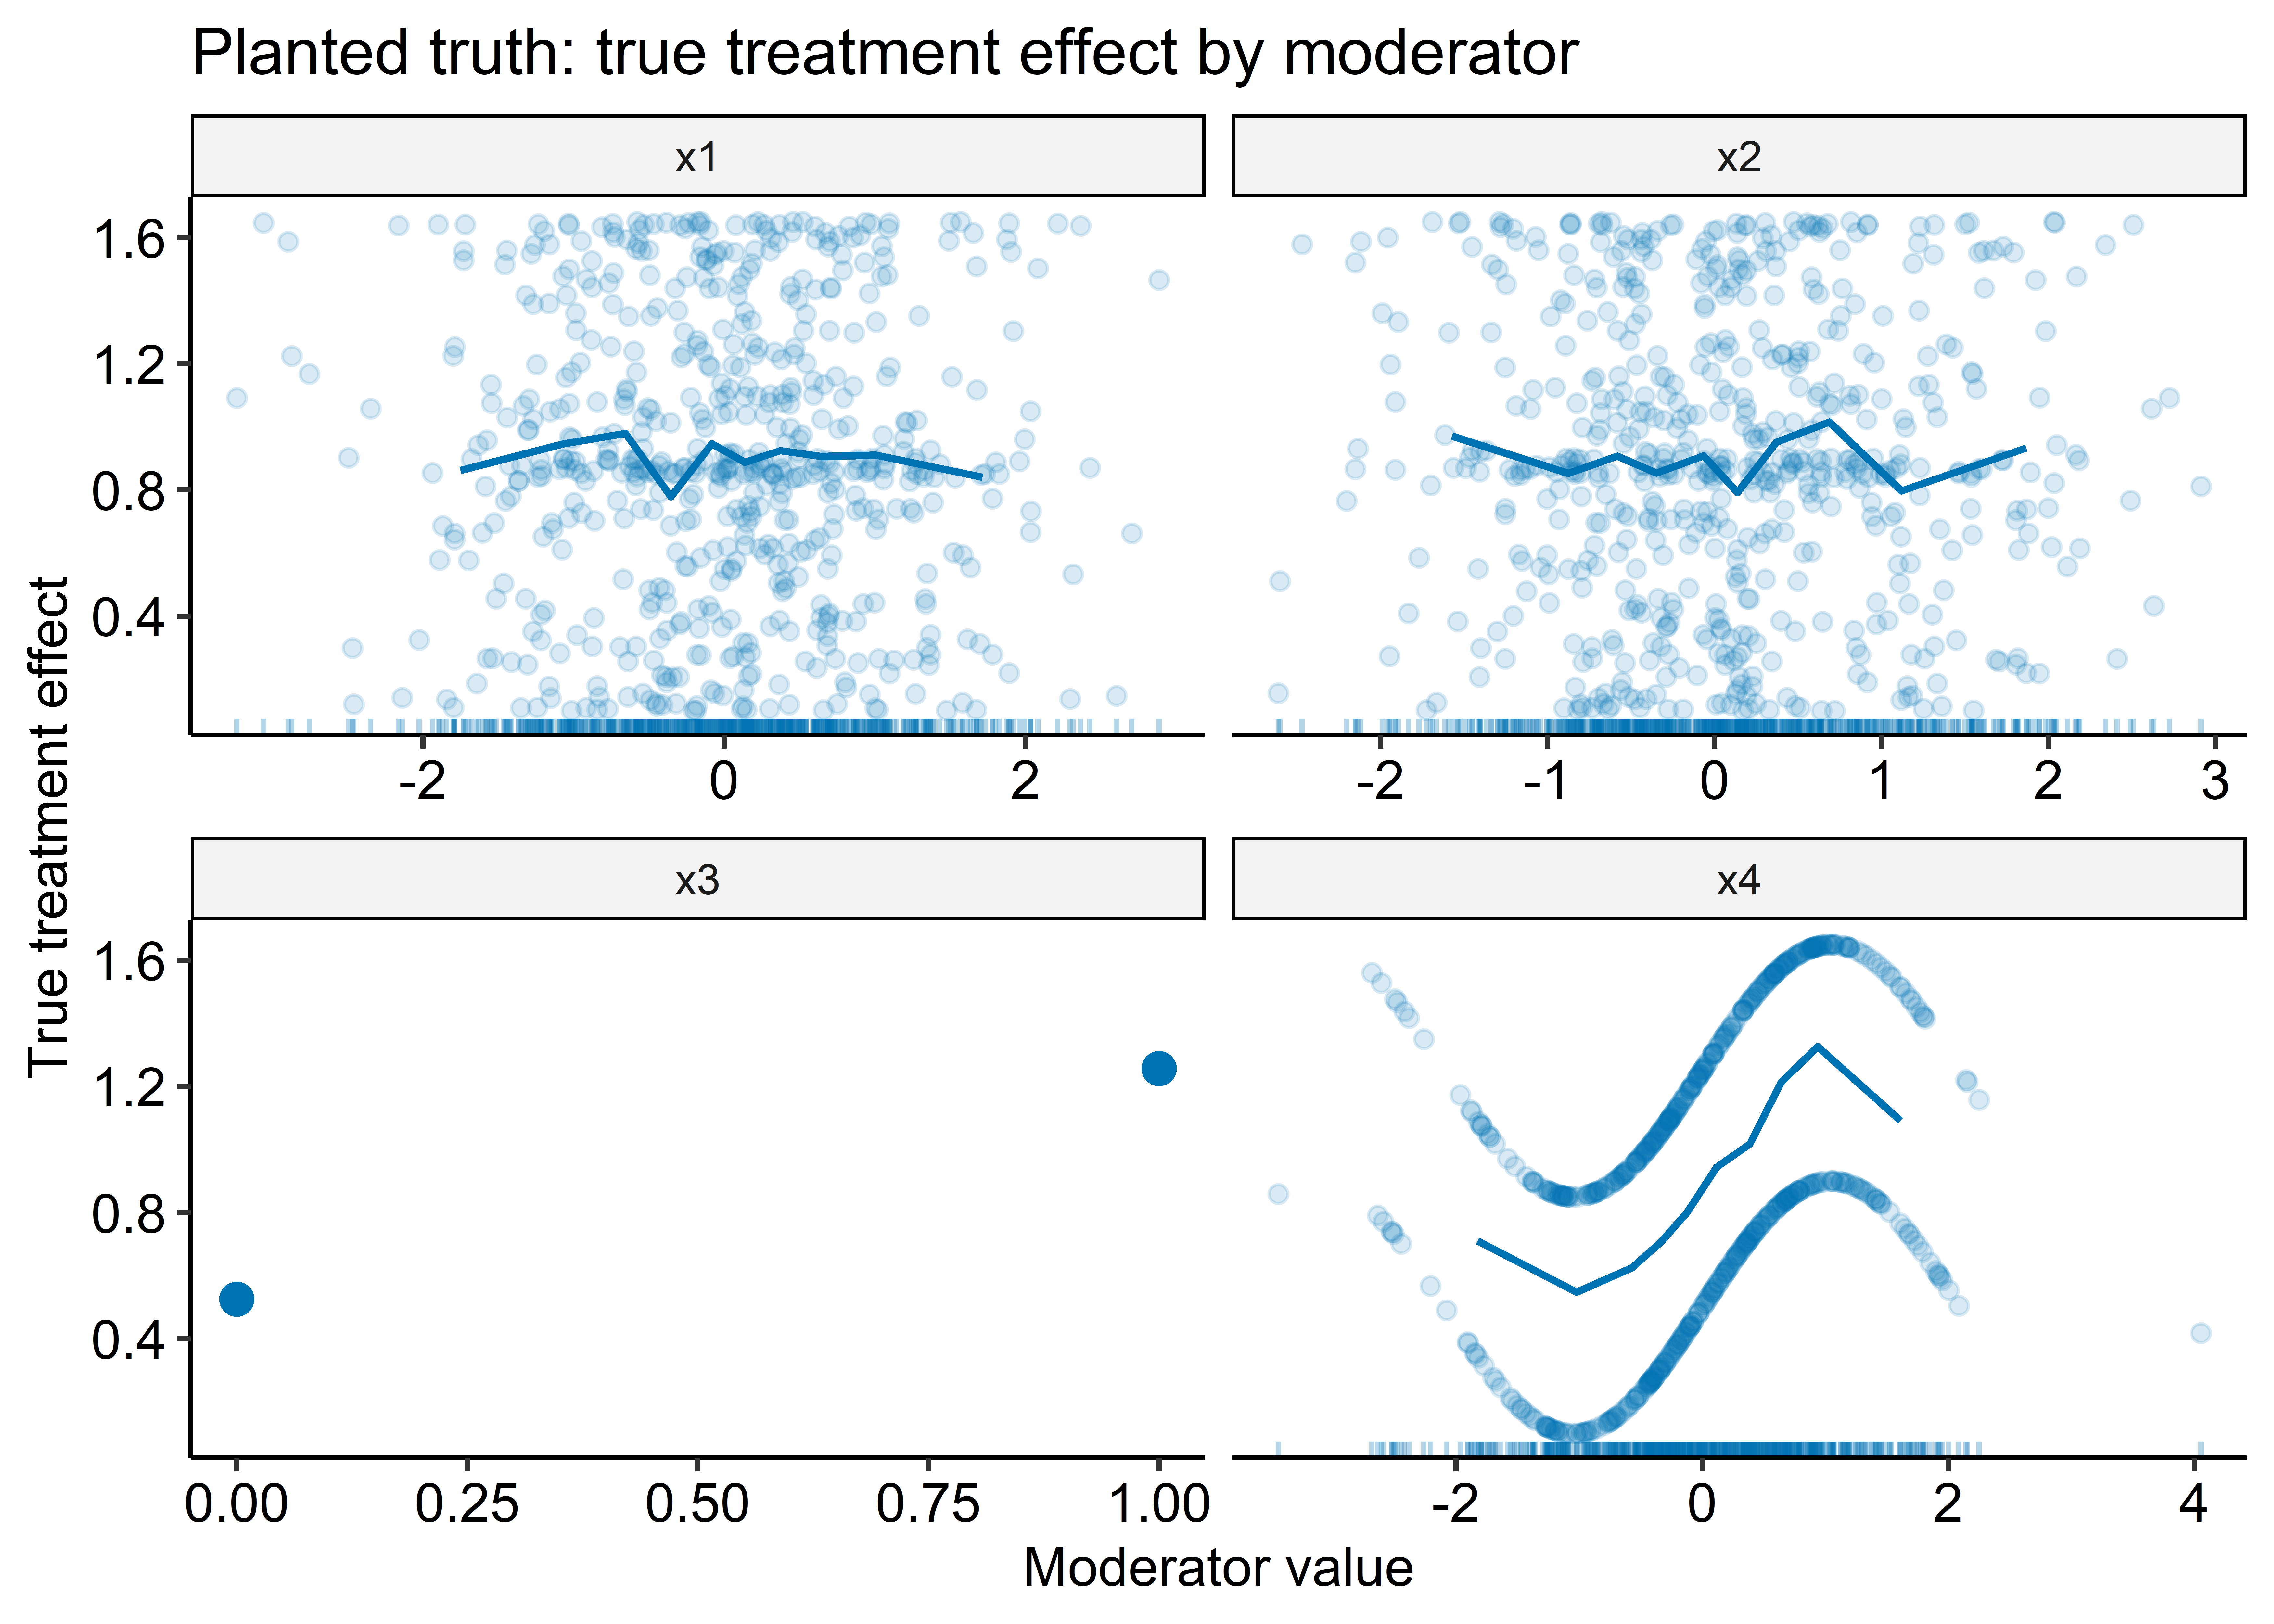

In [ ]:
# long form: each moderator's value against the true tau_i
truth_long <- tibble(
  x1 = X[, 1],
  x2 = X[, 2],
  x3 = X[, 3],
  x4 = X[, 4],
  tau = tau_x
) |>
  pivot_longer(c(x1, x2, x3, x4), names_to = "covariate", values_to = "value")

# continuous covariates: raw points + 10-quantile binned-mean curve
truth_cont <- truth_long |> filter(covariate != "x3")
truth_cont_bin <- truth_cont |>
  mutate(bin = ntile(value, 10), .by = covariate) |>
  summarise(value = mean(value), tau = mean(tau), .by = c(covariate, bin))

# binary x3: the two level means at 0 and 1
truth_x3 <- truth_long |>
  filter(covariate == "x3") |>
  summarise(tau = mean(tau), .by = c(covariate, value))

ggplot(mapping = aes(x = value, y = tau)) +
  geom_point(data = truth_cont, alpha = 0.15, colour = "#0072B2") +
  geom_rug(data = truth_cont, sides = "b", alpha = 0.3, colour = "#0072B2") +
  geom_line(data = truth_cont_bin, colour = "#0072B2", linewidth = 0.8) +
  geom_point(data = truth_x3, size = 3, colour = "#0072B2") +
  facet_wrap(~covariate, scales = "free_x") +
  labs(
    title = "Planted truth: true treatment effect by moderator",
    x = "Moderator value",
    y = "True treatment effect"
  ) +
  ggpubr::theme_pubr()


## Build the nested random-effects design

`nested_random_intercepts()` takes the two grouping factors (outer first, inner second) and returns the design `W`, the component-assignment matrix `Q`, the per-level dummies, and the block sizes used later by the extractor. We assert the shape we expect: `W` is `n × (C + R)`, and `Q`’s columns sum to the two block sizes (so component 1 owns the country dummies and component 2 the respondent dummies).

In [ ]:
re <- nested_random_intercepts(country_id, resp_id)

C <- re$n_level1
R <- re$n_level2

stopifnot(
  nrow(re$randeff_design) == n,
  ncol(re$randeff_design) == C + R,
  ncol(re$randeff_variance_component_design) == 2,
  all(colSums(re$randeff_variance_component_design) == c(C, R)),
  all(rowSums(re$randeff_variance_component_design) == 1)
)


## Fit — continuous path

`bcf_continuous_linear()` is the continuous-outcome path; the nested design passes straight through the unchanged wrapper to the sampler.

Arguments, in call order:

- **`y`** — outcome vector (length `n`); the wrapper standardizes internally and back-transforms, so the raw scale is fine.
- **`z`** — binary treatment (0/1) whose effect `tau(x)` we want.
- **`x_control`** — numeric design for the prognostic function `mu(x)` (covariates explaining the outcome absent treatment).
- **`x_moderate`** — design for `tau(x)`: the candidate *moderators* the forest may split on. We pass the same `X` for both, searching the full set for heterogeneity.
- **`zhat`** — propensity `E(Z | X)`. Randomized at known 0.5, so we pass the truth and skip first-stage estimation.
- **`randeff_design`** — `W`, the `n x (C + R)` group-dummy matrix (country block then respondent block) from `nested_random_intercepts()`.
- **`randeff_variance_component_design`** — `Q`, the `(C + R) x K` map from each `W` column to its variance component; with `K = 2`, country and respondent levels shrink independently.
- **`randeff_scales`** — prior scale per variance component (must be length `K`; see below).
- **`randeff_df`** — half-t degrees of freedom for each random-intercept SD (`3`, the package default; smaller = heavier-tailed).
- **`nburn`, `nsim`** — burn-in (discarded) and saved draws; `nsim` is the row dimension of every posterior matrix.
- **`update_interval`** — iterations between progress lines (see console note).

Two call-site details matter:

- **`randeff_scales` must be length `K = 2`** — the sampler indexes one scale per component, so a scalar would be out of bounds. (A pre-existing quirk cancels the value in the prior, so only the length matters today; we pass sensible values anyway.)
- **Short MCMC** — this is a smoke test; real fits use far longer chains.

> **What healthy console output looks like**
>
> The wrapper first warns `All values of zhat are equal. zhat will not be included among covariates` — expected: a constant known propensity carries no information to split on, so the sampler drops it.
>
> With `text_trace = TRUE`, the sampler then narrates setup. The diagnostic line to look for is `Using random effects.`; without it, the nested design never reached the sampler. The two BART designs (`design 0` = `mu(x)`, `design 1` = `tau(x)`) should each report four covariate columns.
>
> Every `update_interval` iterations it prints a progress line, e.g. `iteration: 500 sigma/SD(Y): 0.542733`. `sigma/SD(Y)` is the residual SD on the standardized-`y` scale; here it drops to ~`0.5` within 50 iterations and then holds in a stable `0.47–0.57` band — the model captures most of the variance and the chain has converged. A value still drifting downward at the end would mean `nburn` was too short.

`multibart` runs one chain per call, so we obtain multiple chains by looping over RNG seeds. The C++ sampler draws exclusively from R’s RNG (`R::rnorm` / `R::runif` / `R::rgamma`), so a distinct `set.seed()` per call gives a genuinely distinct chain; `furrr_options(seed = TRUE)` supplies parallel-safe independent RNG streams across workers. A live forest pointer (`tree_samples`) does not survive return from a worker process, so each worker extracts plain numerics only and never returns a fit object. The two traced country contrasts use a *fixed* country index across all chains (the planted extreme-high and extreme-low countries), so R-hat compares the same quantity in every chain. The canonical `fit_cont` consumed by every downstream chunk is fitted separately in the **main** process, where its forest pointer stays live.

In [ ]:
n_chains <- 4L # chains for convergence; reduce to 2 if the runtime is too slow
chain_seeds <- 20260601 + seq_len(n_chains)
hi_idx <- which.max(b_country) # fixed extreme-+ country, same across chains
lo_idx <- which.min(b_country)

# fit one chain, return ONLY numerics (live forest pointers die on worker return)
chain_summary <- function(seed) {
  set.seed(seed)
  f <- bcf_continuous_linear(
    y = y_cont,
    z = z,
    x_control = X,
    x_moderate = X,
    zhat = rep(0.5, n), # known propensity
    randeff_design = re$randeff_design,
    randeff_variance_component_design = re$randeff_variance_component_design,
    randeff_scales = c(1, 1), # length K = 2
    randeff_df = 3,
    nburn = 2000,
    nsim = 2000,
    update_interval = 50
  )
  tau <- get_forest_fit(f$moderate_fit, X) # pointer live INSIDE the worker
  ccol <- f$random_effects[, 1:C, drop = FALSE]
  cc <- ccol - rowMeans(ccol) # centred, location-invariant
  tibble::tibble(
    .iteration = seq_along(f$sigma),
    sigma = f$sigma,
    sd_country = f$random_effects_sd[, 1],
    sd_resp = f$random_effects_sd[, 2],
    ate = rowMeans(tau),
    country_hi = cc[, hi_idx],
    country_lo = cc[, lo_idx]
  )
}

# multisession: required on Windows; one worker per chain
plan(multisession, workers = min(n_chains, future::availableCores()))
chain_draws <- chain_seeds |>
  set_names(seq_len(n_chains)) |> # names carry the chain id through list_rbind
  future_map(
    chain_summary,
    .options = furrr_options(seed = TRUE, packages = "multibart")
  ) |>
  list_rbind(names_to = ".chain") |>
  mutate(.chain = as.integer(.chain))


Using random effects.
Reading in y

Setting up designs

design 0
group setting: 0
Instantiated covariate matrix 1 with 4 columns
design 1
group setting: 0
Instantiated covariate matrix 2 with 4 columns
Setting up forests

Done.

Beginning MCMC:
iteration: 0 sigma/SD(Y): 1
iteration: 50 sigma/SD(Y): 0.516514
iteration: 100 sigma/SD(Y): 0.502257
iteration: 150 sigma/SD(Y): 0.55263
iteration: 200 sigma/SD(Y): 0.534178
iteration: 250 sigma/SD(Y): 0.559712
iteration: 300 sigma/SD(Y): 0.545473
iteration: 350 sigma/SD(Y): 0.546429
iteration: 400 sigma/SD(Y): 0.521883
iteration: 450 sigma/SD(Y): 0.567008
iteration: 500 sigma/SD(Y): 0.541633
iteration: 550 sigma/SD(Y): 0.53325
iteration: 600 sigma/SD(Y): 0.536084
iteration: 650 sigma/SD(Y): 0.50134
iteration: 700 sigma/SD(Y): 0.539664
iteration: 750 sigma/SD(Y): 0.53644
iteration: 800 sigma/SD(Y): 0.558376
iteration: 850 sigma/SD(Y): 0.539632
iteration: 900 sigma/SD(Y): 0.544459
iteration: 950 sigma/SD(Y): 0.522464
iteration: 1000 sigma/SD(Y): 

Warning in bcf_continuous_linear(y = y_cont, z = z, x_control = X, x_moderate =
X, : All values of zhat are equal. zhat will not be included among covariates

Using random effects.
Reading in y

Setting up designs

design 0
group setting: 0
Instantiated covariate matrix 1 with 4 columns
design 1
group setting: 0
Instantiated covariate matrix 2 with 4 columns
Setting up forests

Done.

Beginning MCMC:
iteration: 0 sigma/SD(Y): 1
iteration: 50 sigma/SD(Y): 0.497779
iteration: 100 sigma/SD(Y): 0.569832
iteration: 150 sigma/SD(Y): 0.53317
iteration: 200 sigma/SD(Y): 0.544608
iteration: 250 sigma/SD(Y): 0.578615
iteration: 300 sigma/SD(Y): 0.550307
iteration: 350 sigma/SD(Y): 0.551105
iteration: 400 sigma/SD(Y): 0.516829
iteration: 450 sigma/SD(Y): 0.584839
iteration: 500 sigma/SD(Y): 0.515039
iteration: 550 sigma/SD(Y): 0.561392
iteration: 600 sigma/SD(Y): 0.539475
iteration: 650 sigma/SD(Y): 0.577577
iteration: 700 sigma/SD(Y): 0.550418
iteration: 750 sigma/SD(Y): 0.566002
iteration: 800 sigma/SD(Y): 0.504744
iteration: 850 sigma/SD(Y): 0.568592
iteration: 900 sigma/SD(Y): 0.520519
iteration: 950 sigma/SD(Y): 0.553157
iteration: 1000 sigma/SD(Y

Warning in bcf_continuous_linear(y = y_cont, z = z, x_control = X, x_moderate =
X, : All values of zhat are equal. zhat will not be included among covariates

Using random effects.
Reading in y

Setting up designs

design 0
group setting: 0
Instantiated covariate matrix 1 with 4 columns
design 1
group setting: 0
Instantiated covariate matrix 2 with 4 columns
Setting up forests

Done.

Beginning MCMC:
iteration: 0 sigma/SD(Y): 1
iteration: 50 sigma/SD(Y): 0.558684
iteration: 100 sigma/SD(Y): 0.518783
iteration: 150 sigma/SD(Y): 0.515867
iteration: 200 sigma/SD(Y): 0.492538
iteration: 250 sigma/SD(Y): 0.529346
iteration: 300 sigma/SD(Y): 0.51802
iteration: 350 sigma/SD(Y): 0.540515
iteration: 400 sigma/SD(Y): 0.524856
iteration: 450 sigma/SD(Y): 0.503675
iteration: 500 sigma/SD(Y): 0.527362
iteration: 550 sigma/SD(Y): 0.496648
iteration: 600 sigma/SD(Y): 0.503762
iteration: 650 sigma/SD(Y): 0.526876
iteration: 700 sigma/SD(Y): 0.489017
iteration: 750 sigma/SD(Y): 0.49372
iteration: 800 sigma/SD(Y): 0.524638
iteration: 850 sigma/SD(Y): 0.503511
iteration: 900 sigma/SD(Y): 0.537717
iteration: 950 sigma/SD(Y): 0.545824
iteration: 1000 sigma/SD(Y)

Warning in bcf_continuous_linear(y = y_cont, z = z, x_control = X, x_moderate =
X, : All values of zhat are equal. zhat will not be included among covariates

Using random effects.
Reading in y

Setting up designs

design 0
group setting: 0
Instantiated covariate matrix 1 with 4 columns
design 1
group setting: 0
Instantiated covariate matrix 2 with 4 columns
Setting up forests

Done.

Beginning MCMC:
iteration: 0 sigma/SD(Y): 1
iteration: 50 sigma/SD(Y): 0.549989
iteration: 100 sigma/SD(Y): 0.541632
iteration: 150 sigma/SD(Y): 0.522643
iteration: 200 sigma/SD(Y): 0.557198
iteration: 250 sigma/SD(Y): 0.520174
iteration: 300 sigma/SD(Y): 0.50879
iteration: 350 sigma/SD(Y): 0.512693
iteration: 400 sigma/SD(Y): 0.554115
iteration: 450 sigma/SD(Y): 0.547308
iteration: 500 sigma/SD(Y): 0.537176
iteration: 550 sigma/SD(Y): 0.527757
iteration: 600 sigma/SD(Y): 0.577942
iteration: 650 sigma/SD(Y): 0.519872
iteration: 700 sigma/SD(Y): 0.511685
iteration: 750 sigma/SD(Y): 0.552885
iteration: 800 sigma/SD(Y): 0.56568
iteration: 850 sigma/SD(Y): 0.520205
iteration: 900 sigma/SD(Y): 0.506347
iteration: 950 sigma/SD(Y): 0.5316
iteration: 1000 sigma/SD(Y): 

Warning in bcf_continuous_linear(y = y_cont, z = z, x_control = X, x_moderate =
X, : All values of zhat are equal. zhat will not be included among covariates

Warning in bcf_continuous_linear(y = y_cont, z = z, x_control = X, x_moderate =
X, : All values of zhat are equal. zhat will not be included among covariates

Using random effects.
Reading in y

Setting up designs

design 0
group setting: 0
Instantiated covariate matrix 1 with 4 columns
design 1
group setting: 0
Instantiated covariate matrix 2 with 4 columns
Setting up forests

Done.

Beginning MCMC:
iteration: 0 sigma/SD(Y): 1
iteration: 50 sigma/SD(Y): 0.516563
iteration: 100 sigma/SD(Y): 0.532981
iteration: 150 sigma/SD(Y): 0.532815
iteration: 200 sigma/SD(Y): 0.512888
iteration: 250 sigma/SD(Y): 0.524007
iteration: 300 sigma/SD(Y): 0.522716
iteration: 350 sigma/SD(Y): 0.536589
iteration: 400 sigma/SD(Y): 0.536902
iteration: 450 sigma/SD(Y): 0.5347
iteration: 500 sigma/SD(Y): 0.535605
iteration: 550 sigma/SD(Y): 0.512325
iteration: 600 sigma/SD(Y): 0.556016
iteration: 650 sigma/SD(Y): 0.550705
iteration: 700 sigma/SD(Y): 0.529561
iteration: 750 sigma/SD(Y): 0.524806
iteration: 800 sigma/SD(Y): 0.554841
iteration: 850 sigma/SD(Y): 0.541751
iteration: 900 sigma/SD(Y): 0.546537
iteration: 950 sigma/SD(Y): 0.54341
iteration: 1000 sigma/SD(Y):

## Convergence and mixing

`multibart` is a Gibbs/Metropolis sampler, not Stan’s HMC, so we trace scalar *functionals* of the draws (the residual SD, the two variance-component SDs, the ATE, and two country contrasts) rather than the trees themselves. R-hat and bulk-ESS carry over unchanged from the HMC world, but R-hat is only defined across chains, which is why the `n_chains` separate chains fitted above are needed. The HMC-specific diagnostics — divergences, E-BFMI / energy, treedepth — do not exist for this sampler, and their absence is expected rather than a problem. Variance components mix more slowly under Gibbs, and `sd_country` especially has only `C = 8` groups to inform it, so a lower ESS there than for `sigma` or the ATE is normal. The live `iteration: N sigma/SD(Y):` line printed by the canonical fit is a crude running trace; its flattening by roughly iteration 50 is the evidence that `nburn` is long enough. Raw intercept *levels* can drift harmlessly in overall location (the identifiability point from @sec-downstream), so the two country contrasts are traced in centred form to keep R-hat meaningful. `n_chains` is set in the fit chunk above and can be dropped to 2 if needed; the chains run in parallel through `future`/`furrr` (`multisession`, one worker per chain), so the parallel block costs about one chain of wall time, with the worker count following `n_chains`. These are deliberately short smoke-test chains (`nburn` = `nsim` = 2000): each fit runs in a few seconds, so the parallel block plus the separate canonical main-process fit finish in well under a minute. Posterior memory scales with `nsim` (the `nsim × n` fitted-value and `nsim × (C + R)` random-effect matrices), so four parallel workers at `nsim` = 20000 exhaust RAM on a typical machine — which is why the smoke test keeps the chains short and why a production-scale fit would run chains sequentially or on more memory.

In [ ]:
# one functional, coloured by chain
trace_plot <- function(var, ttl) {
  chain_draws |>
    ggplot(aes(x = .iteration, y = .data[[var]], colour = factor(.chain))) +
    geom_line(alpha = 0.7) +
    labs(title = ttl, x = "Draw index", y = ttl, colour = "Chain") +
    ggpubr::theme_pubr()
}


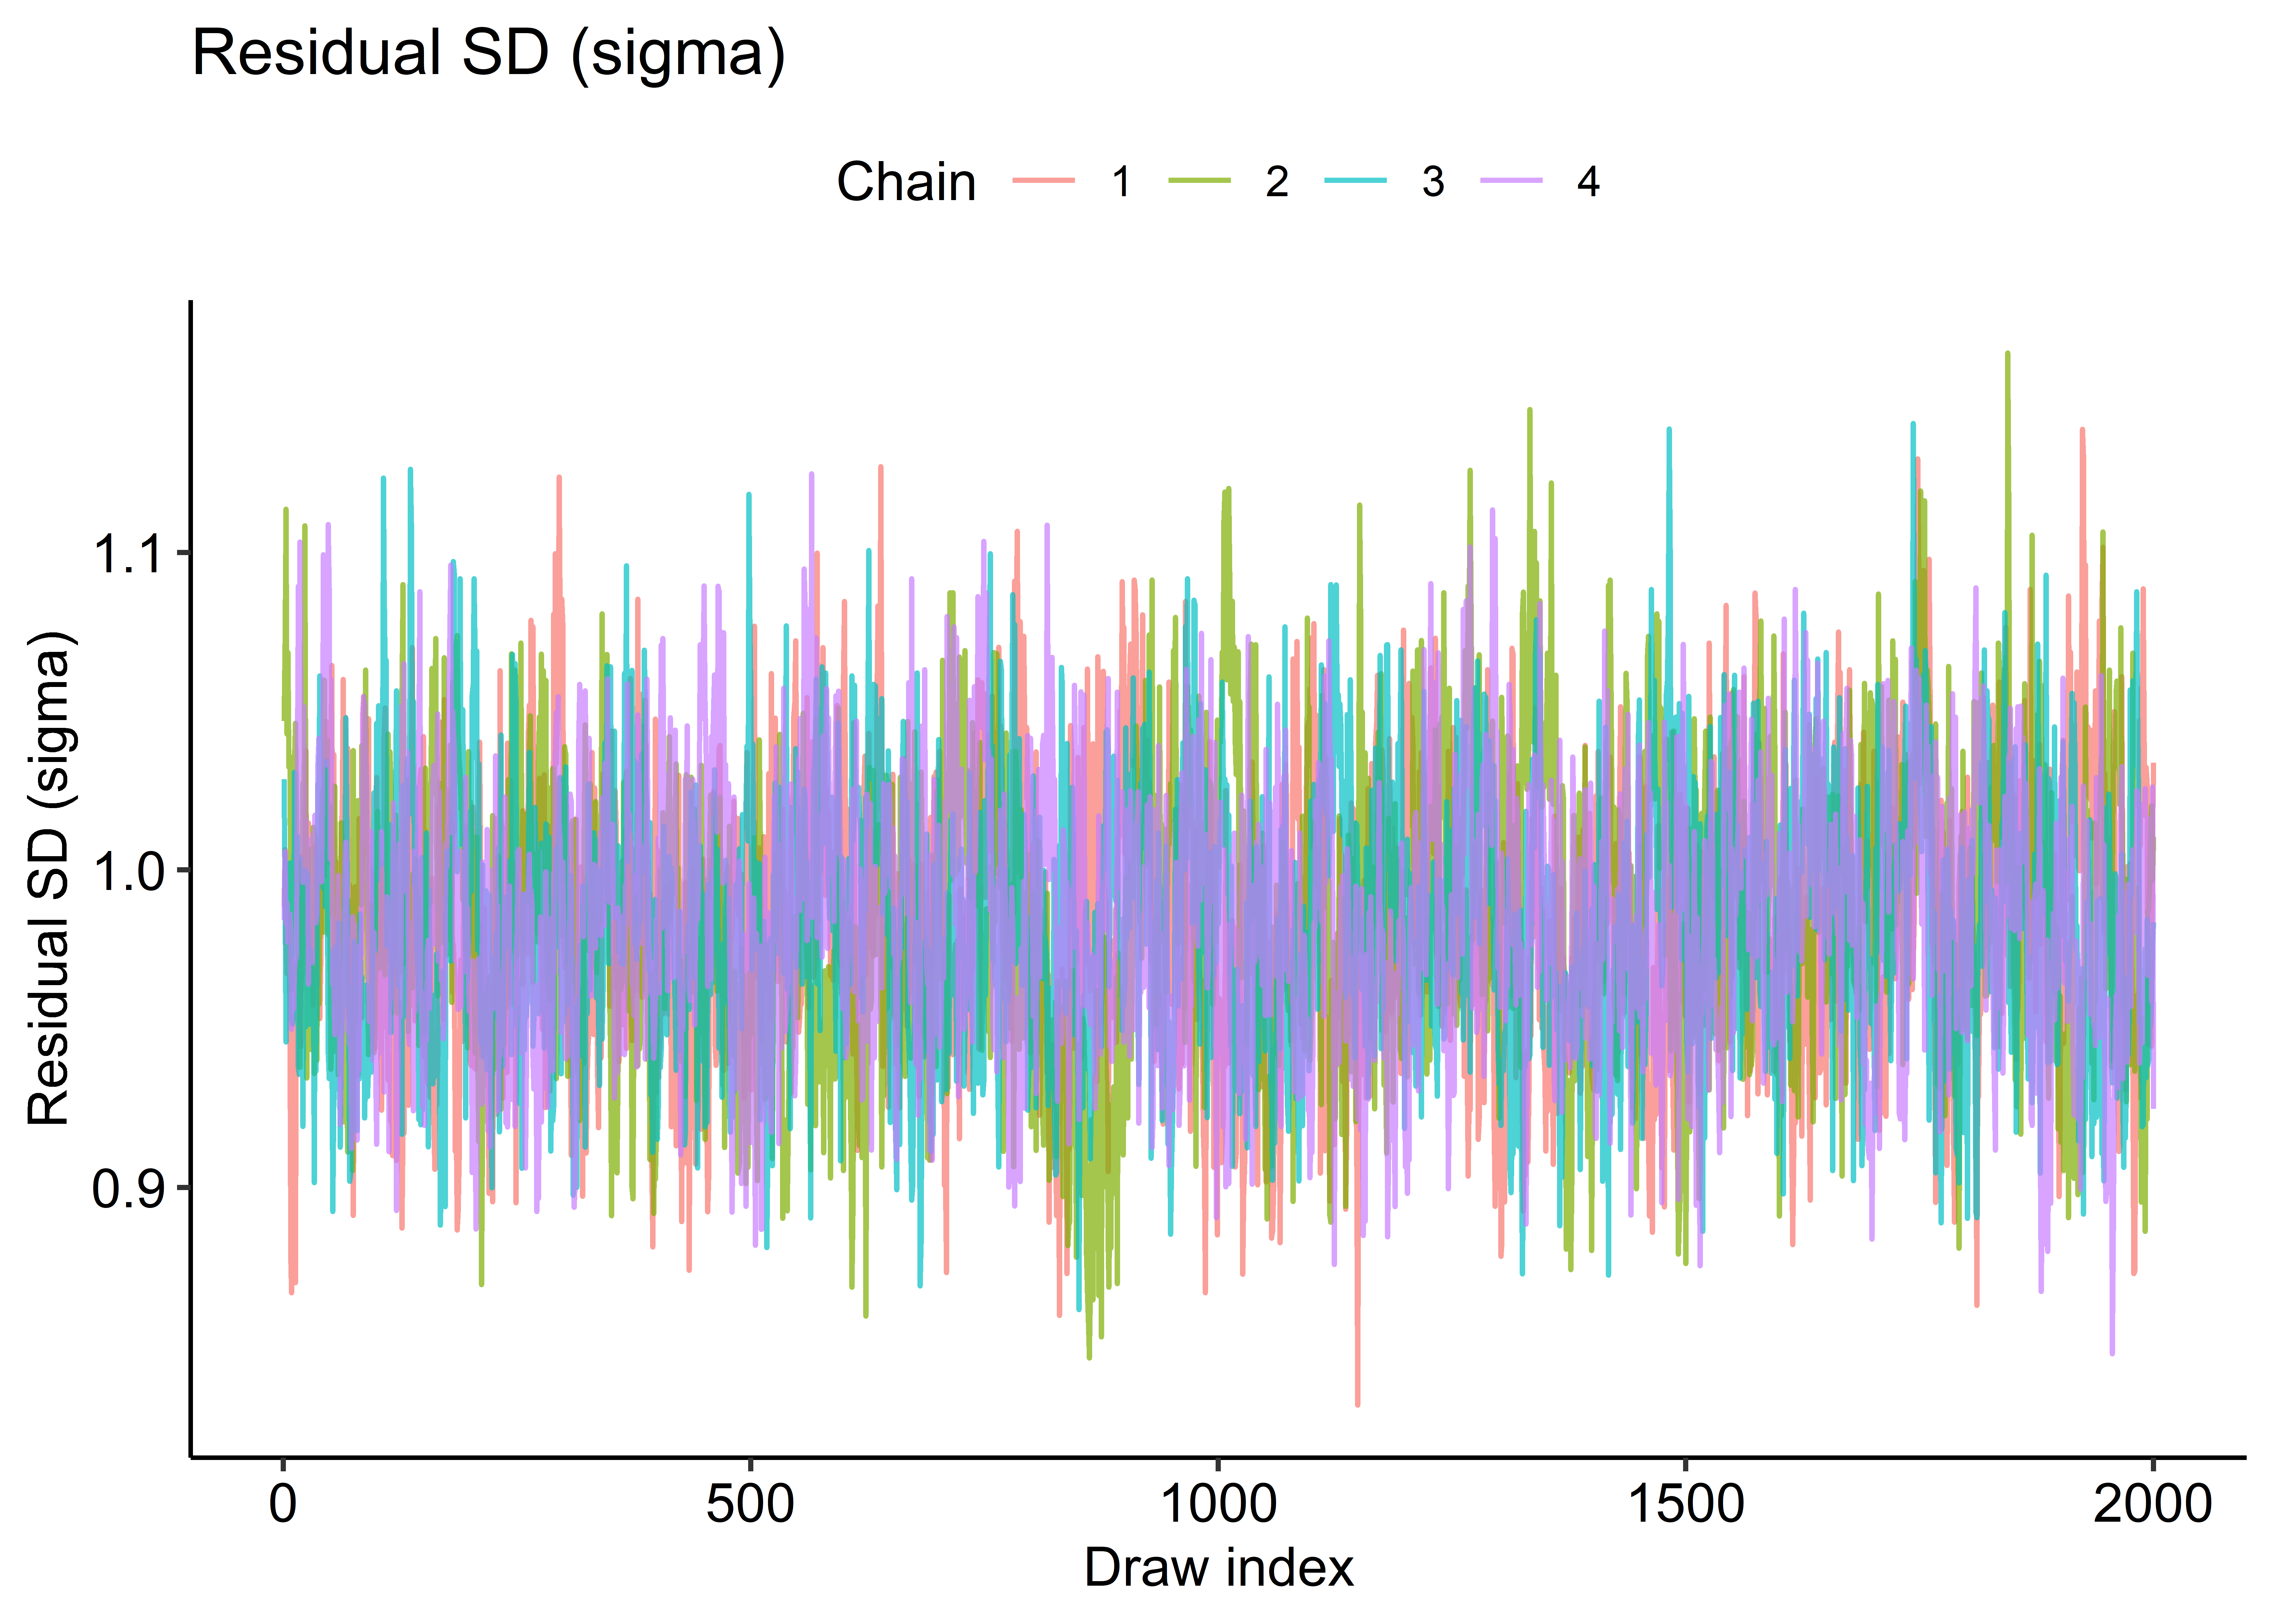

In [ ]:
trace_plot("sigma", "Residual SD (sigma)")


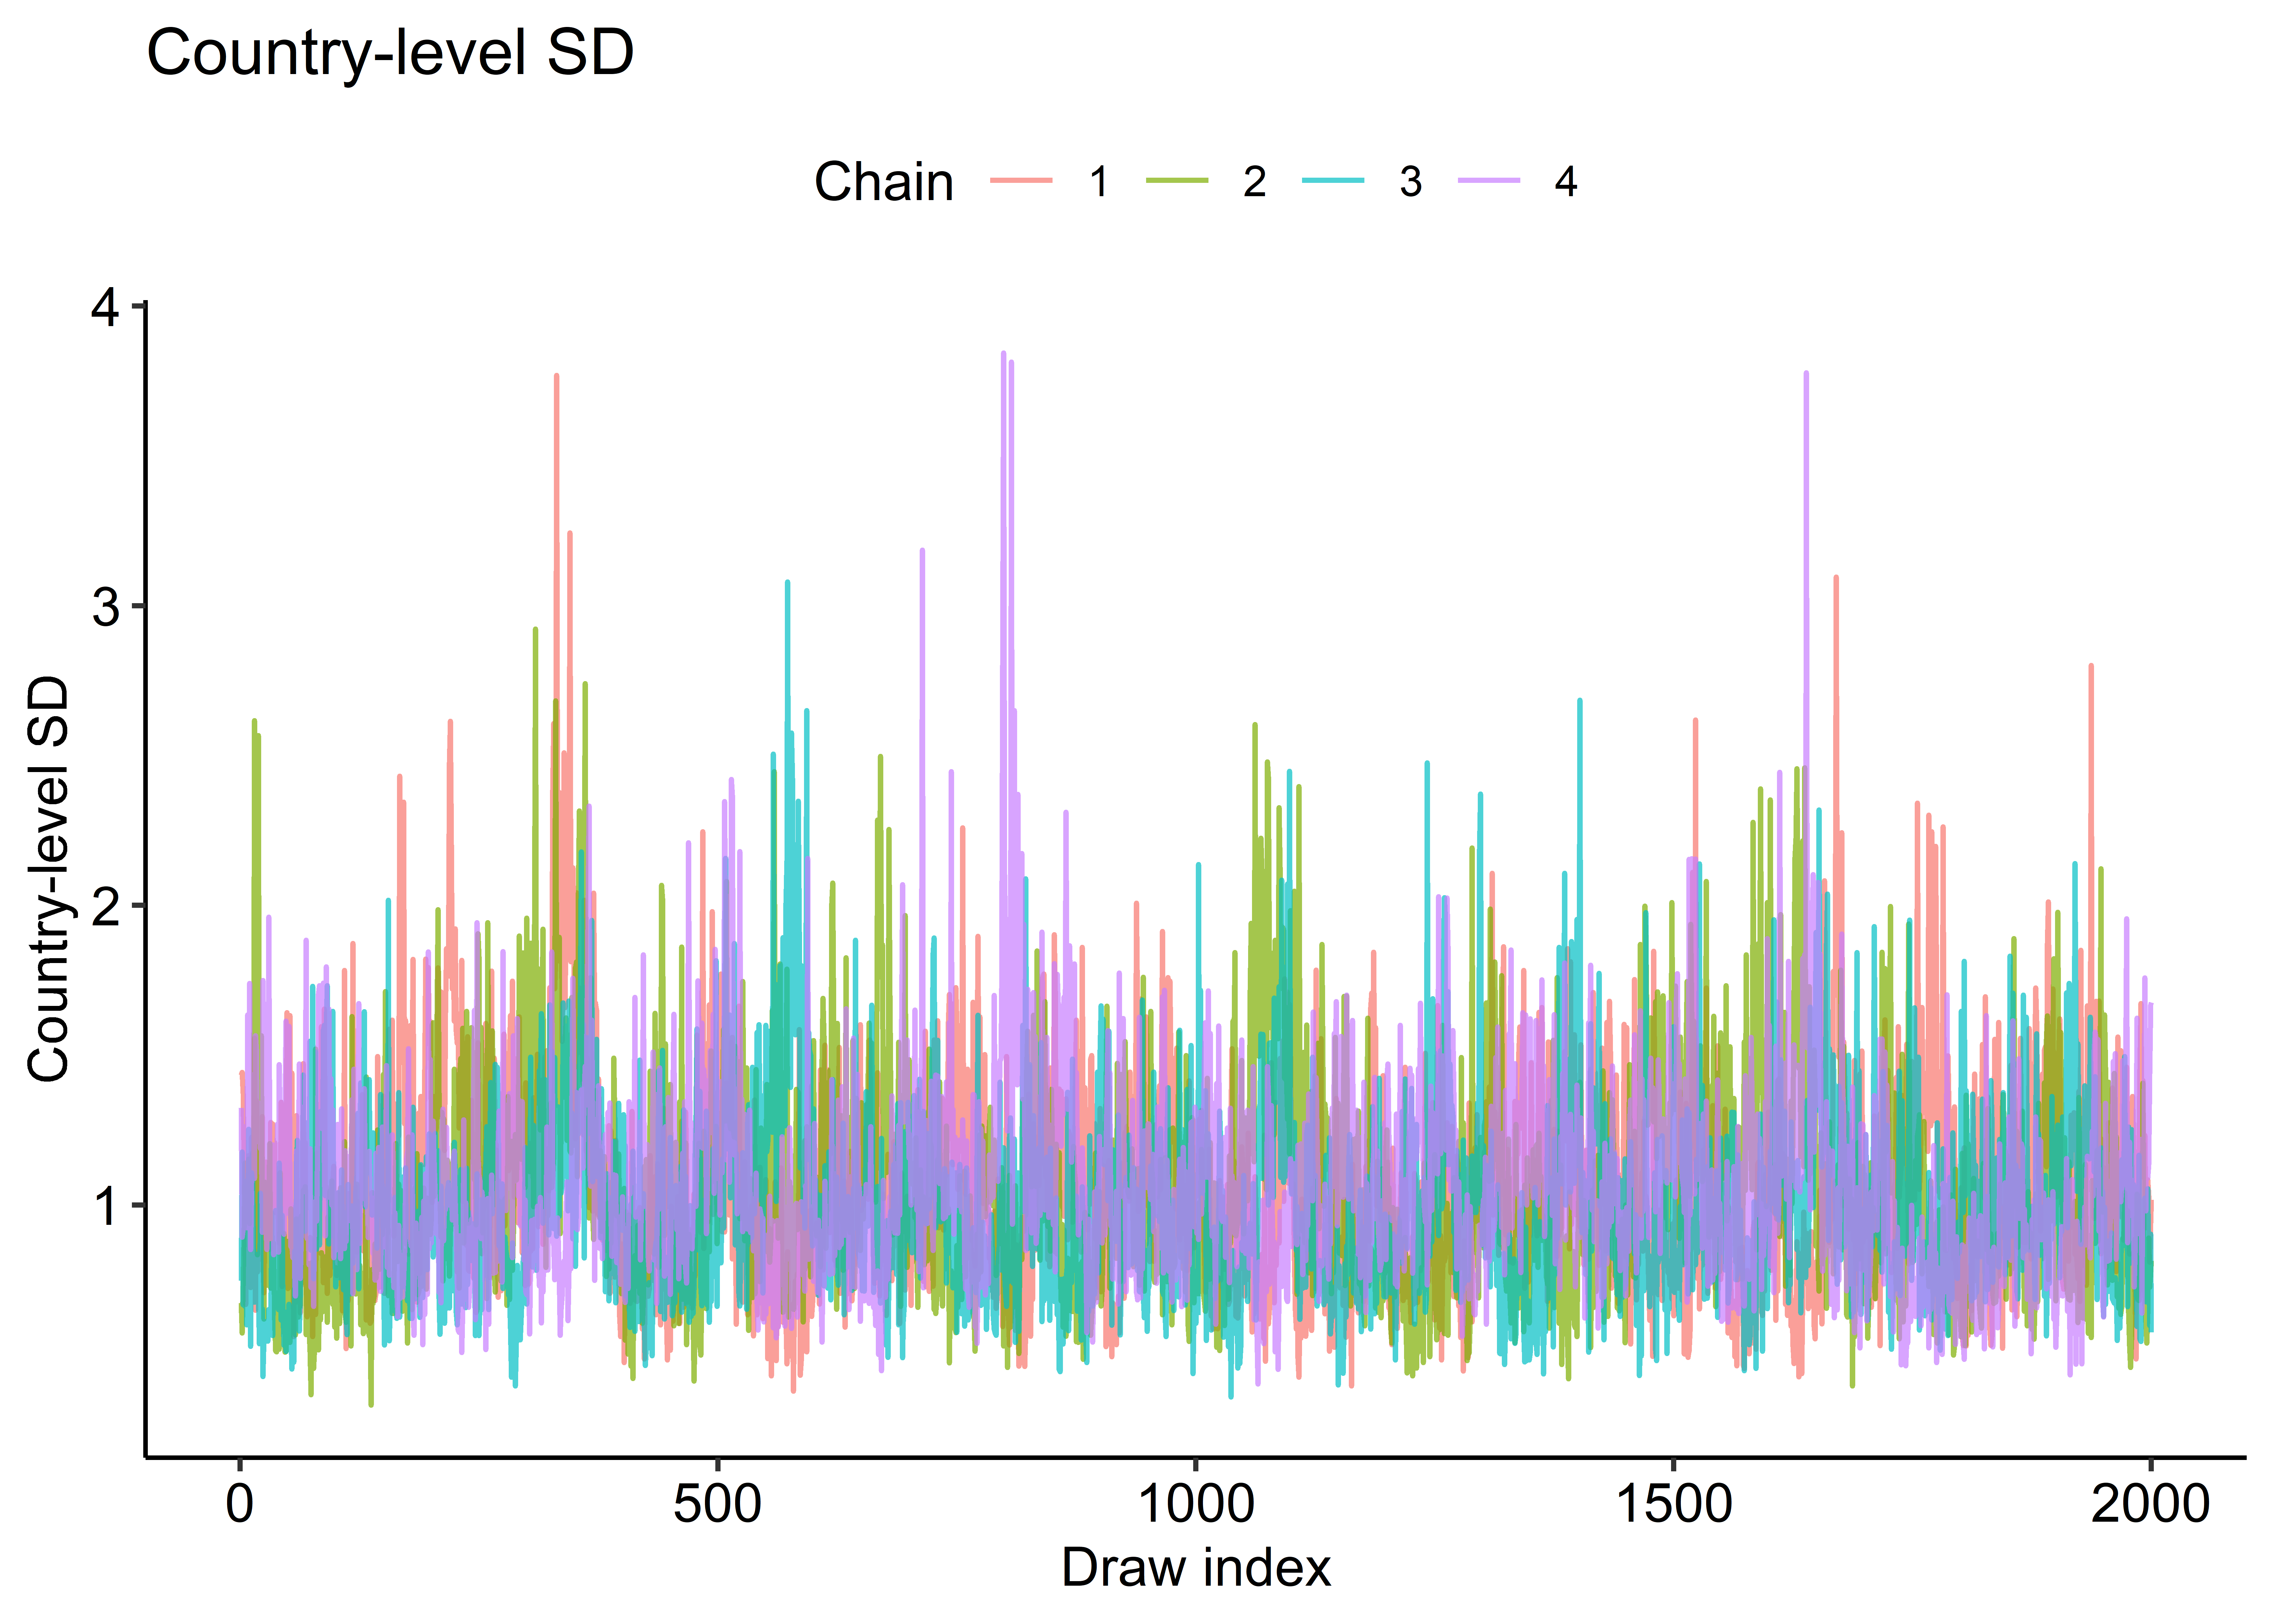

In [ ]:
trace_plot("sd_country", "Country-level SD")


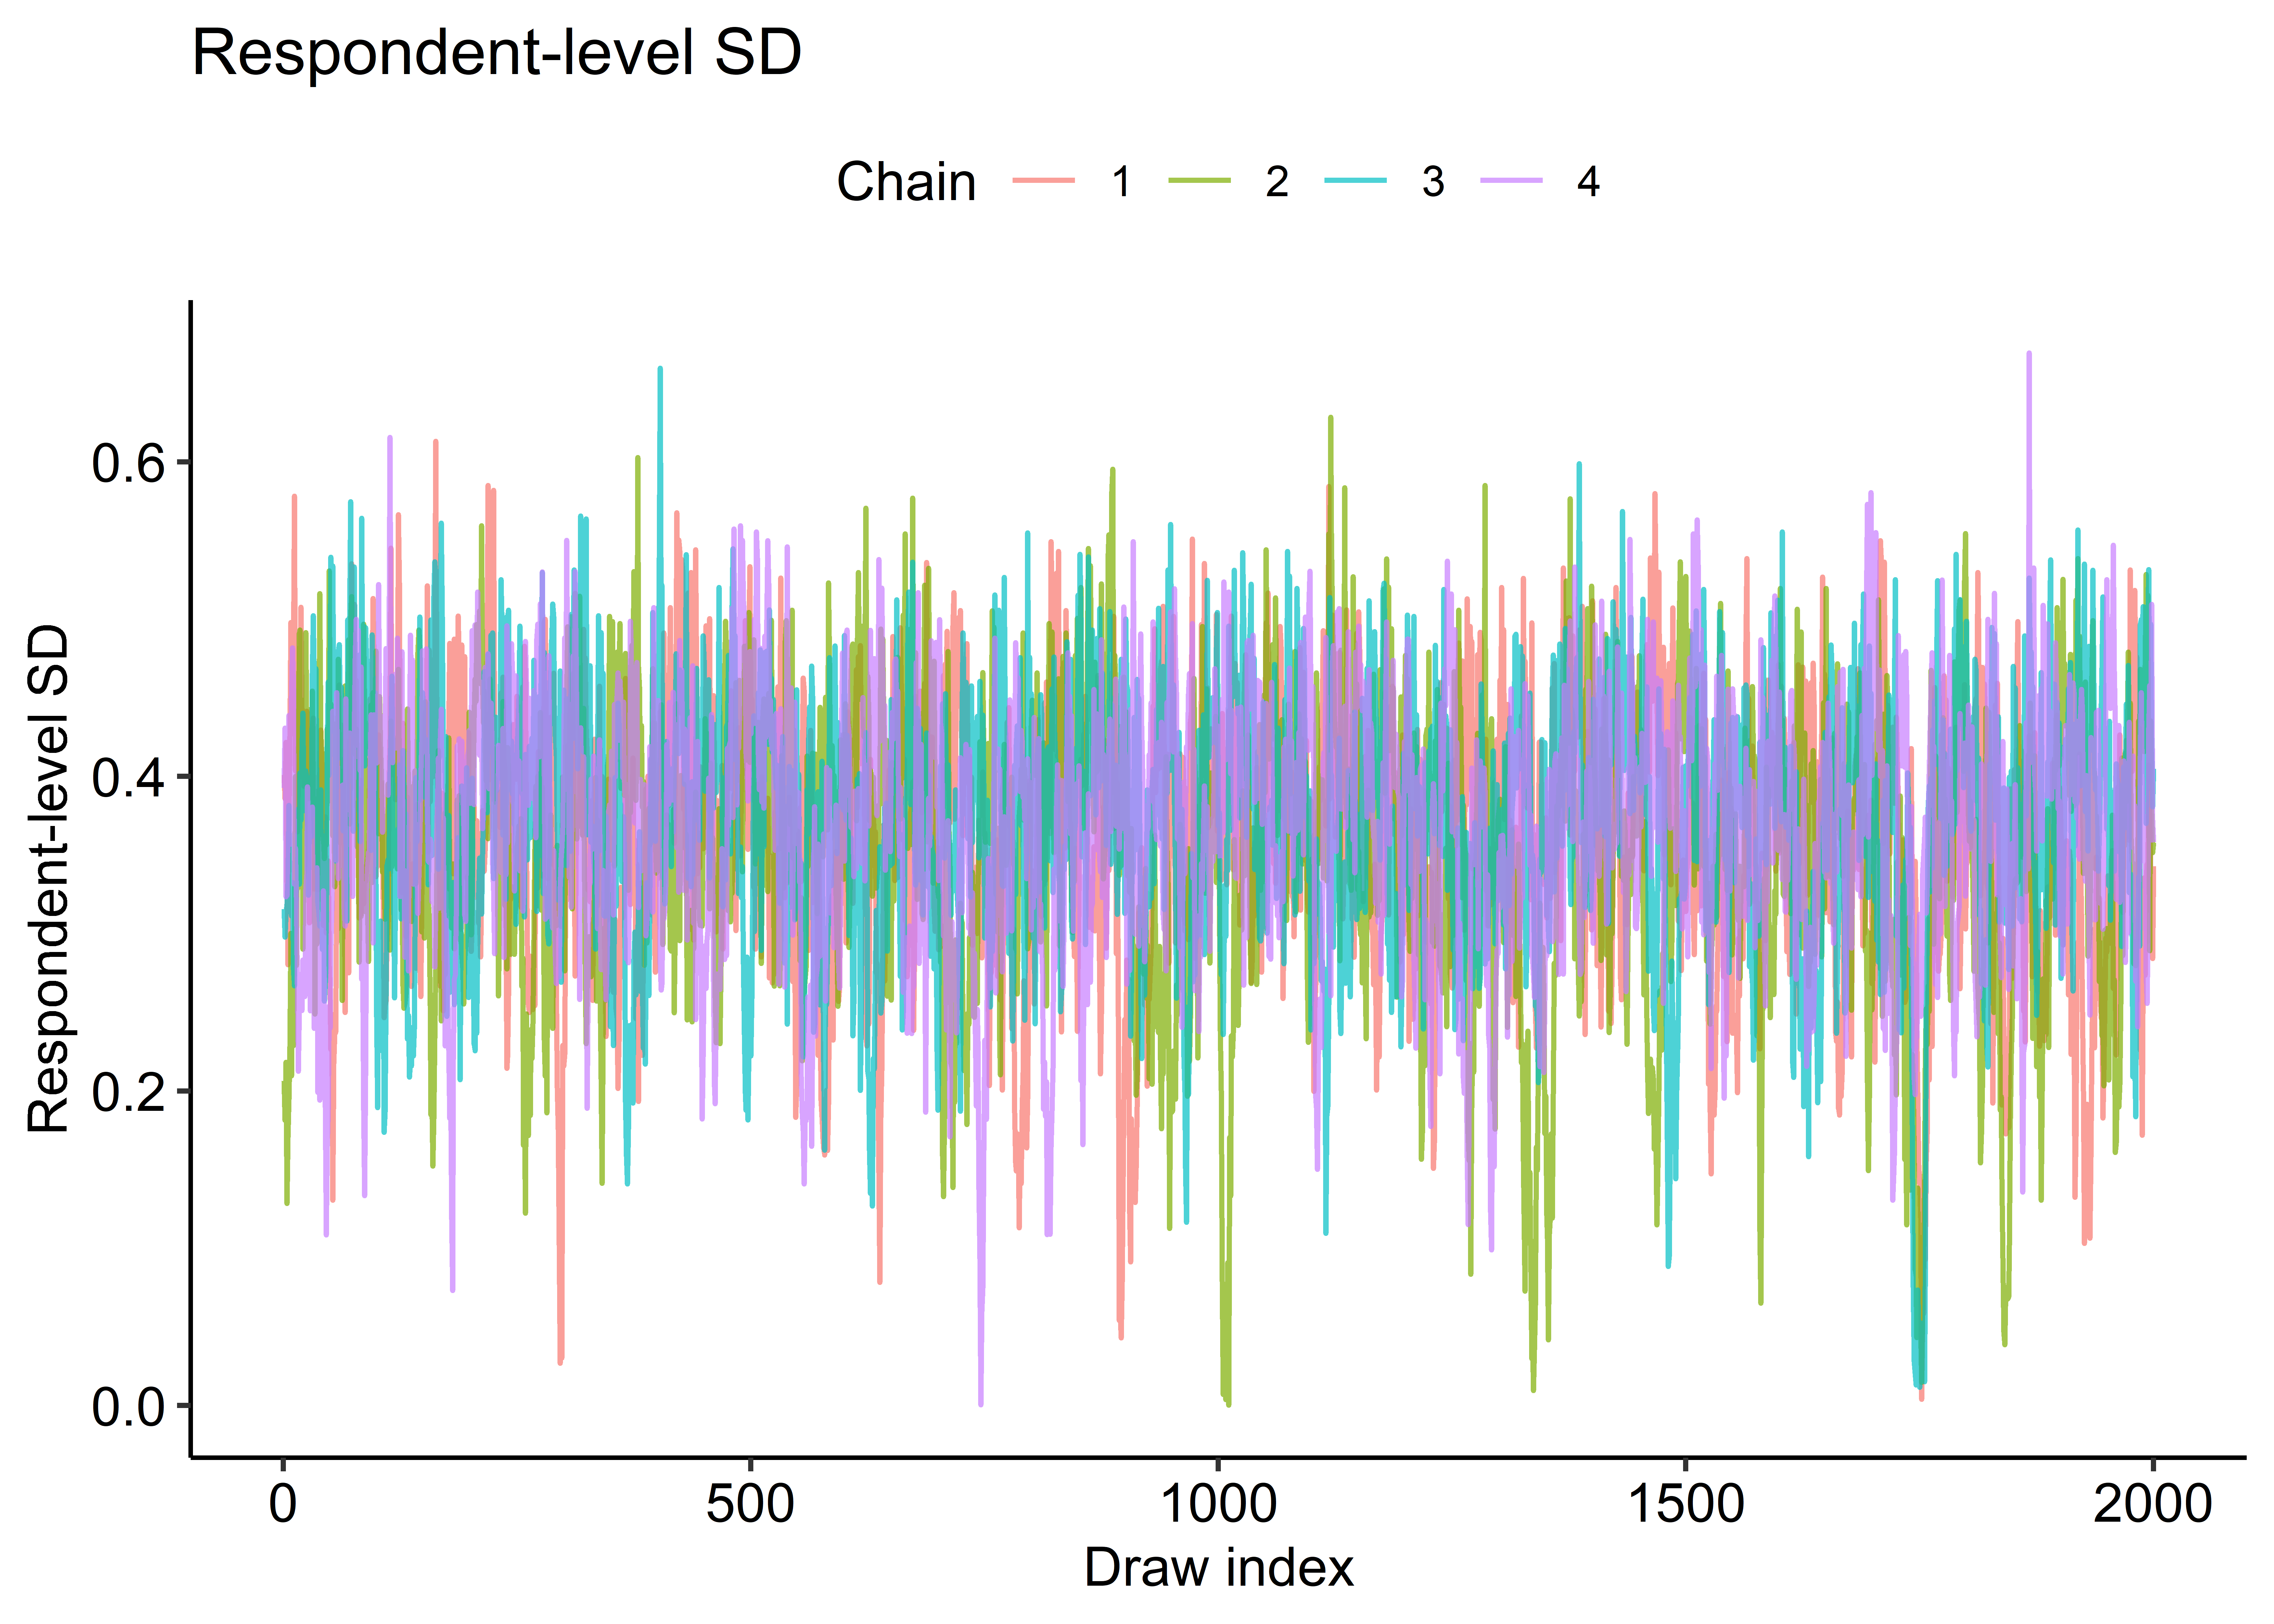

In [ ]:
trace_plot("sd_resp", "Respondent-level SD")


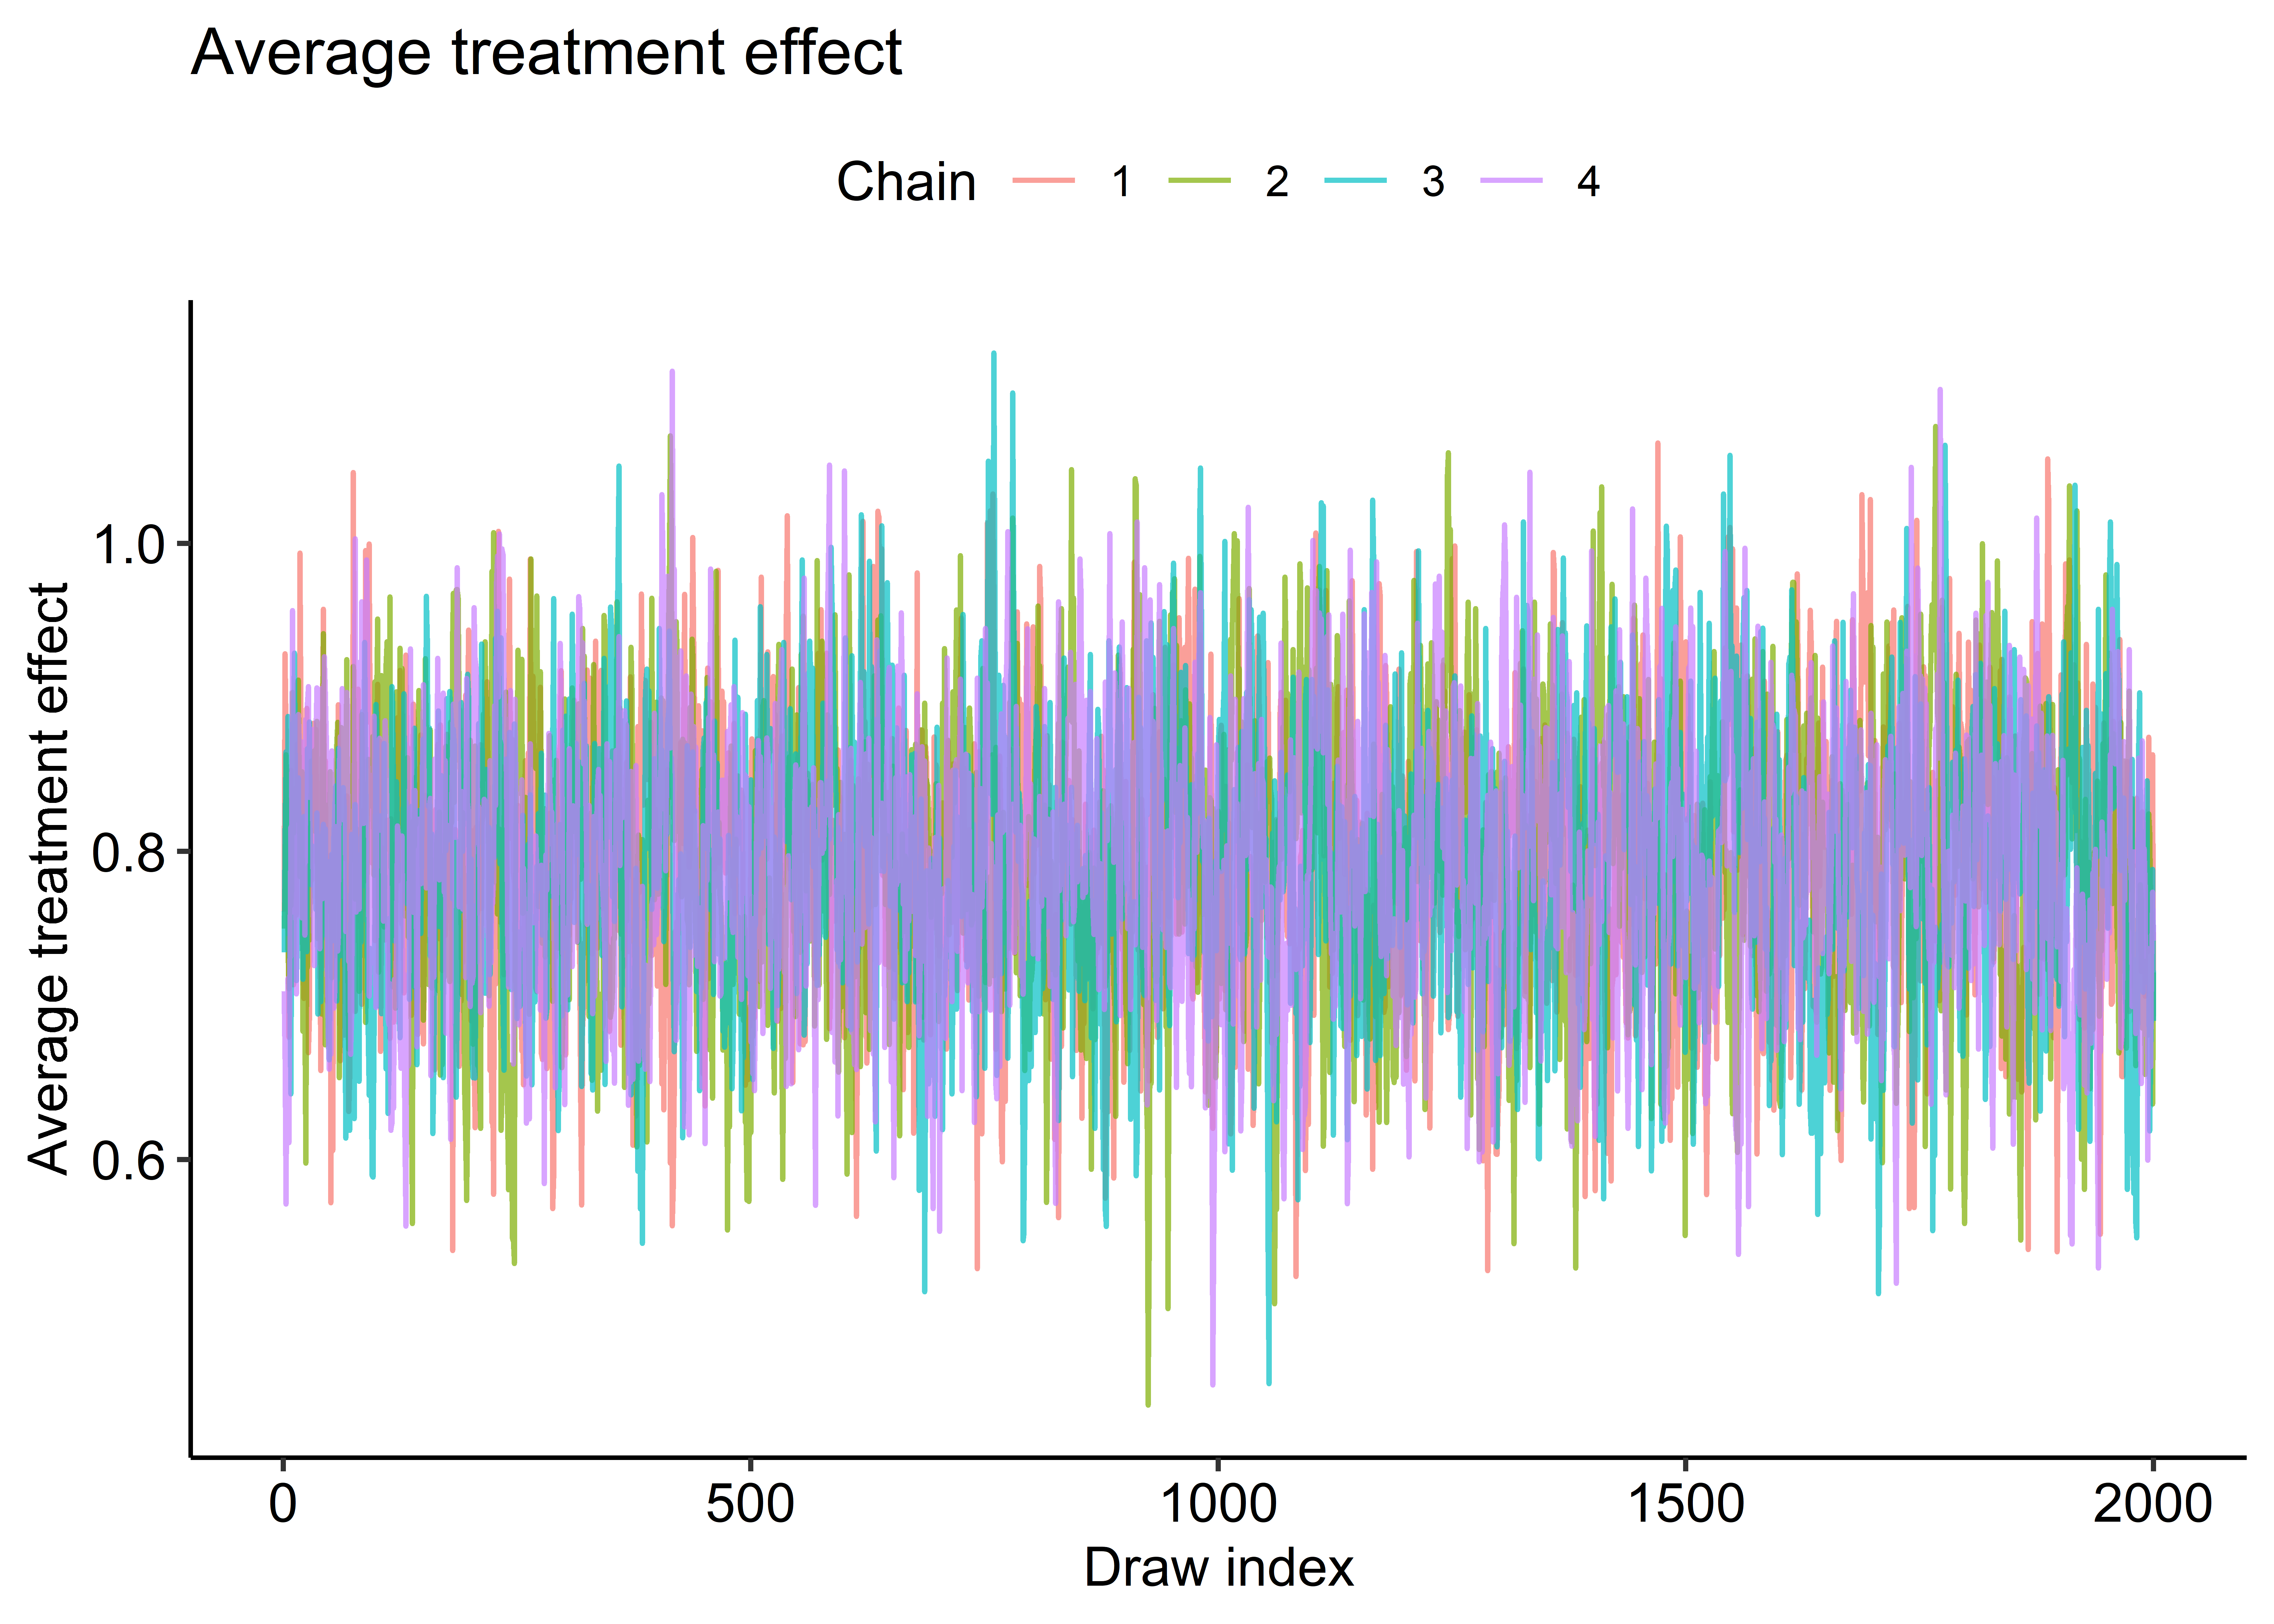

In [ ]:
trace_plot("ate", "Average treatment effect")


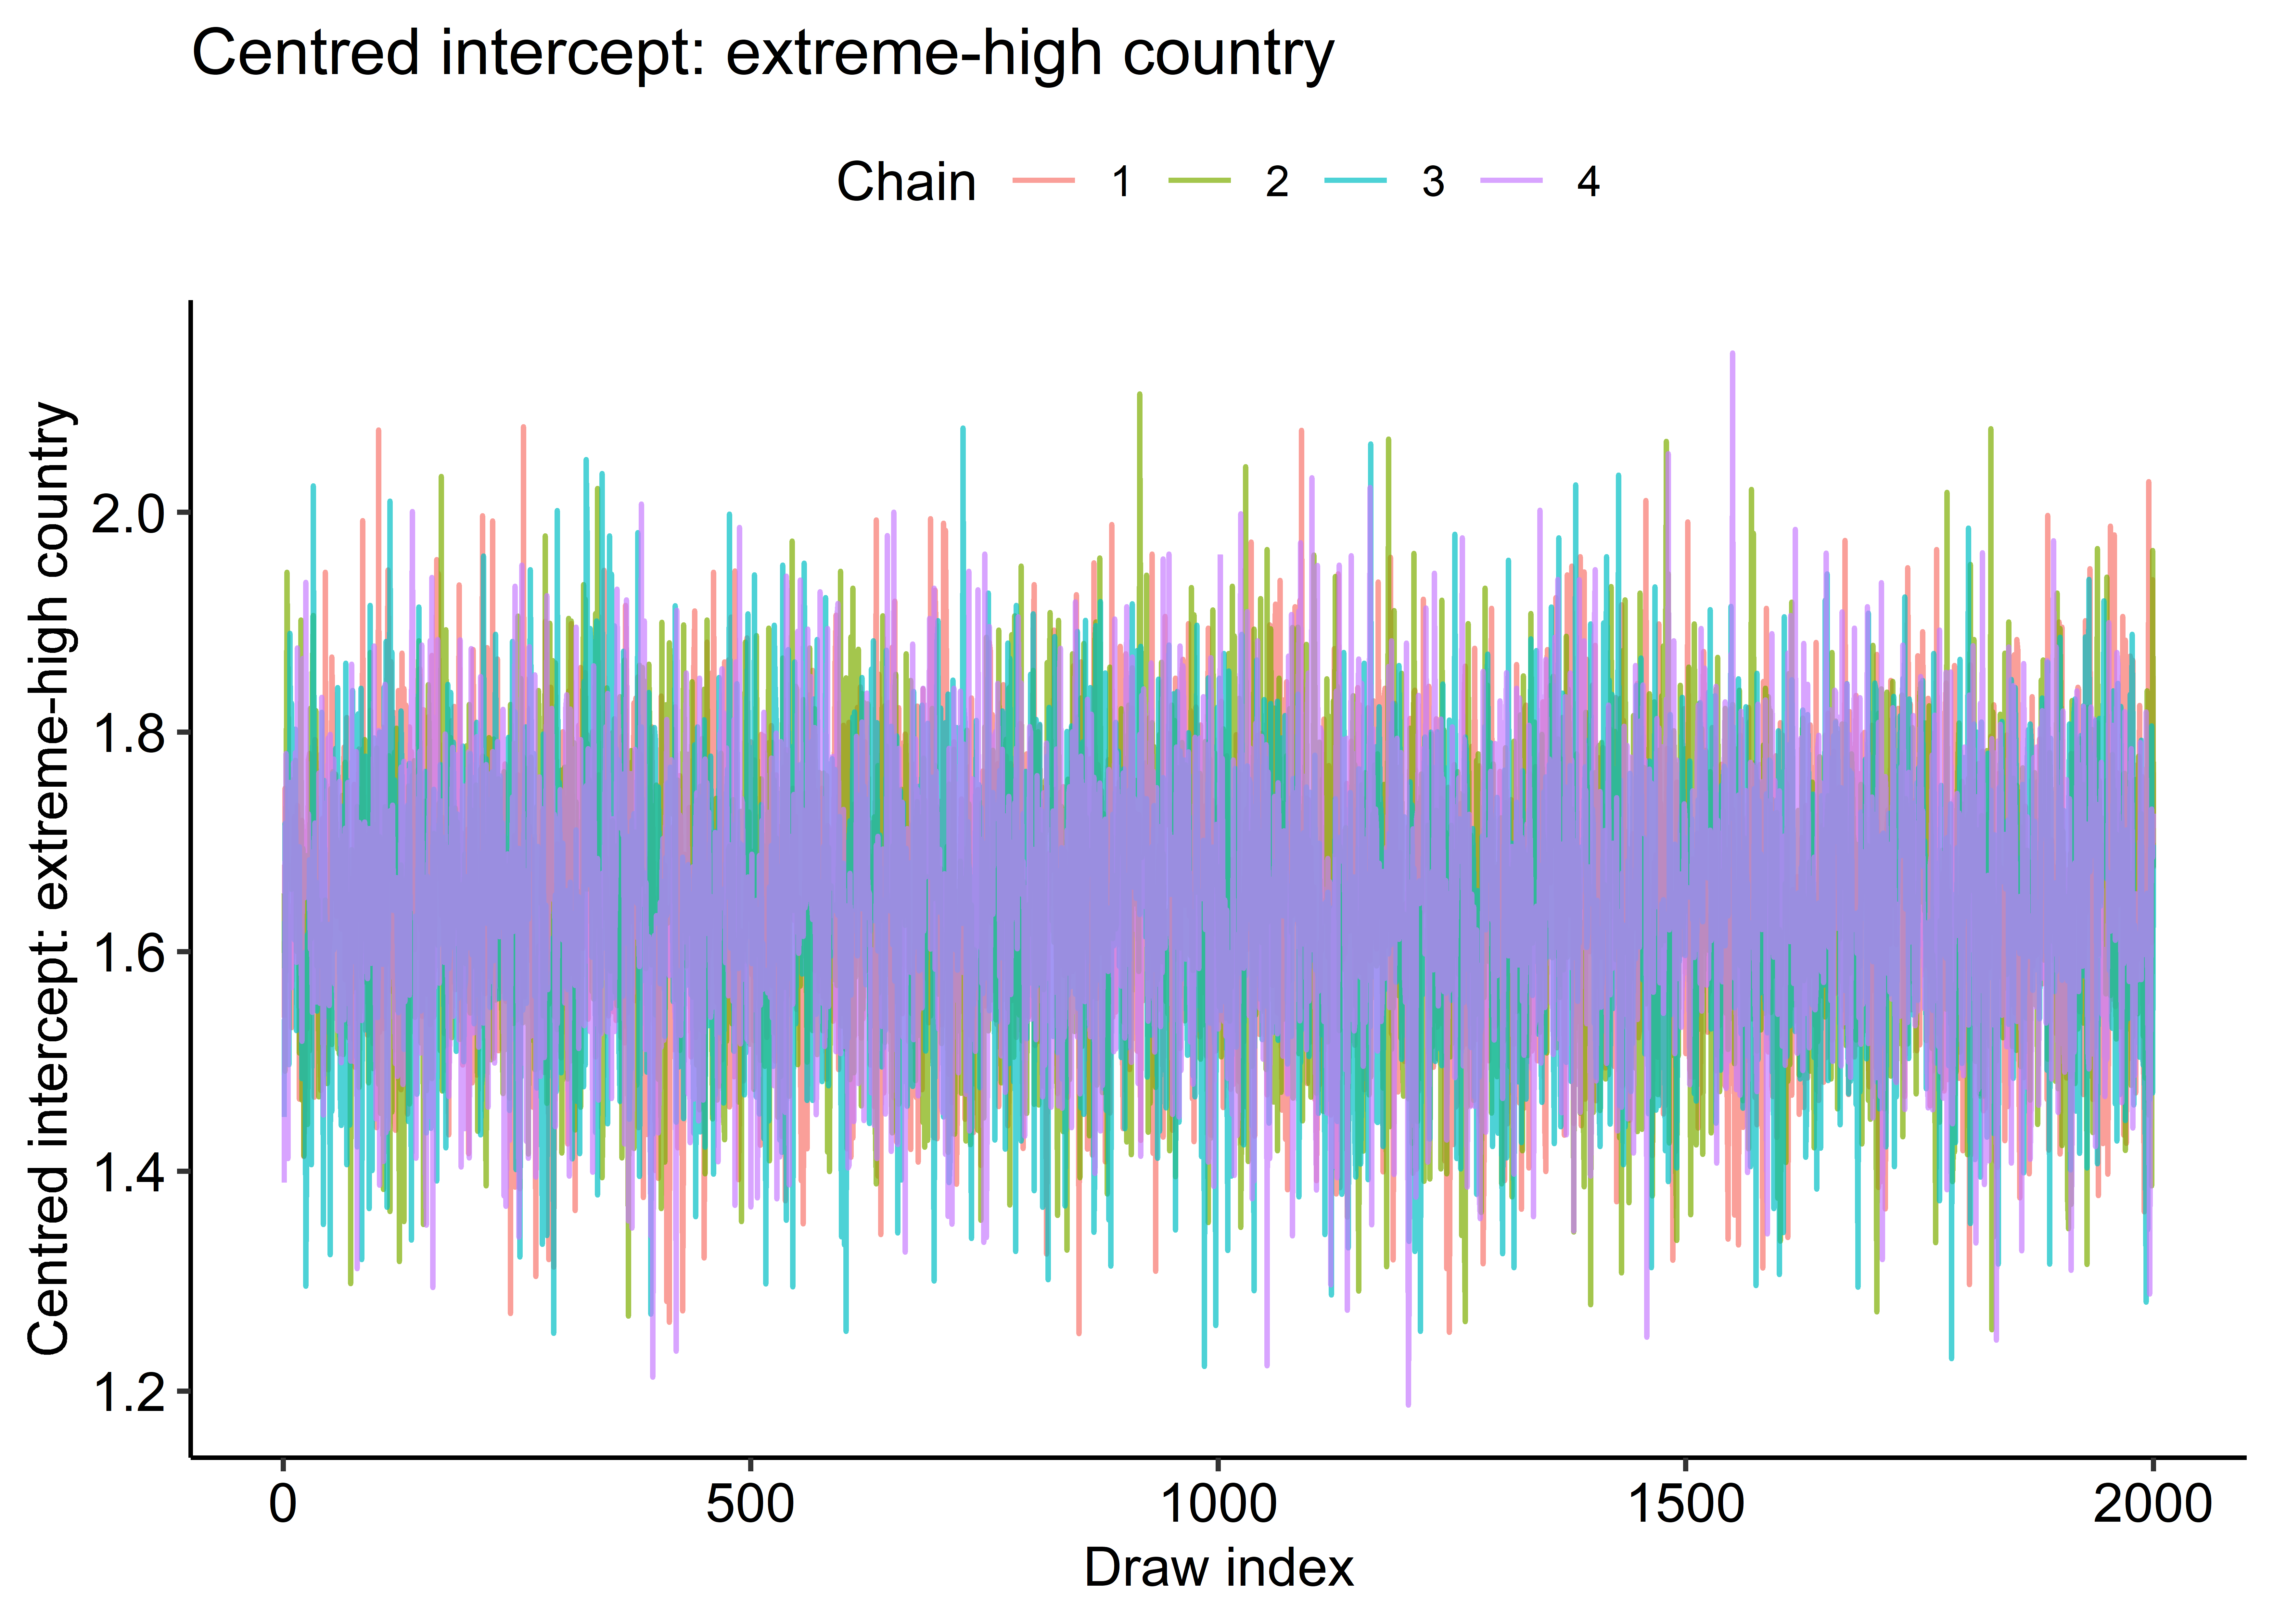

In [ ]:
trace_plot("country_hi", "Centred intercept: extreme-high country")


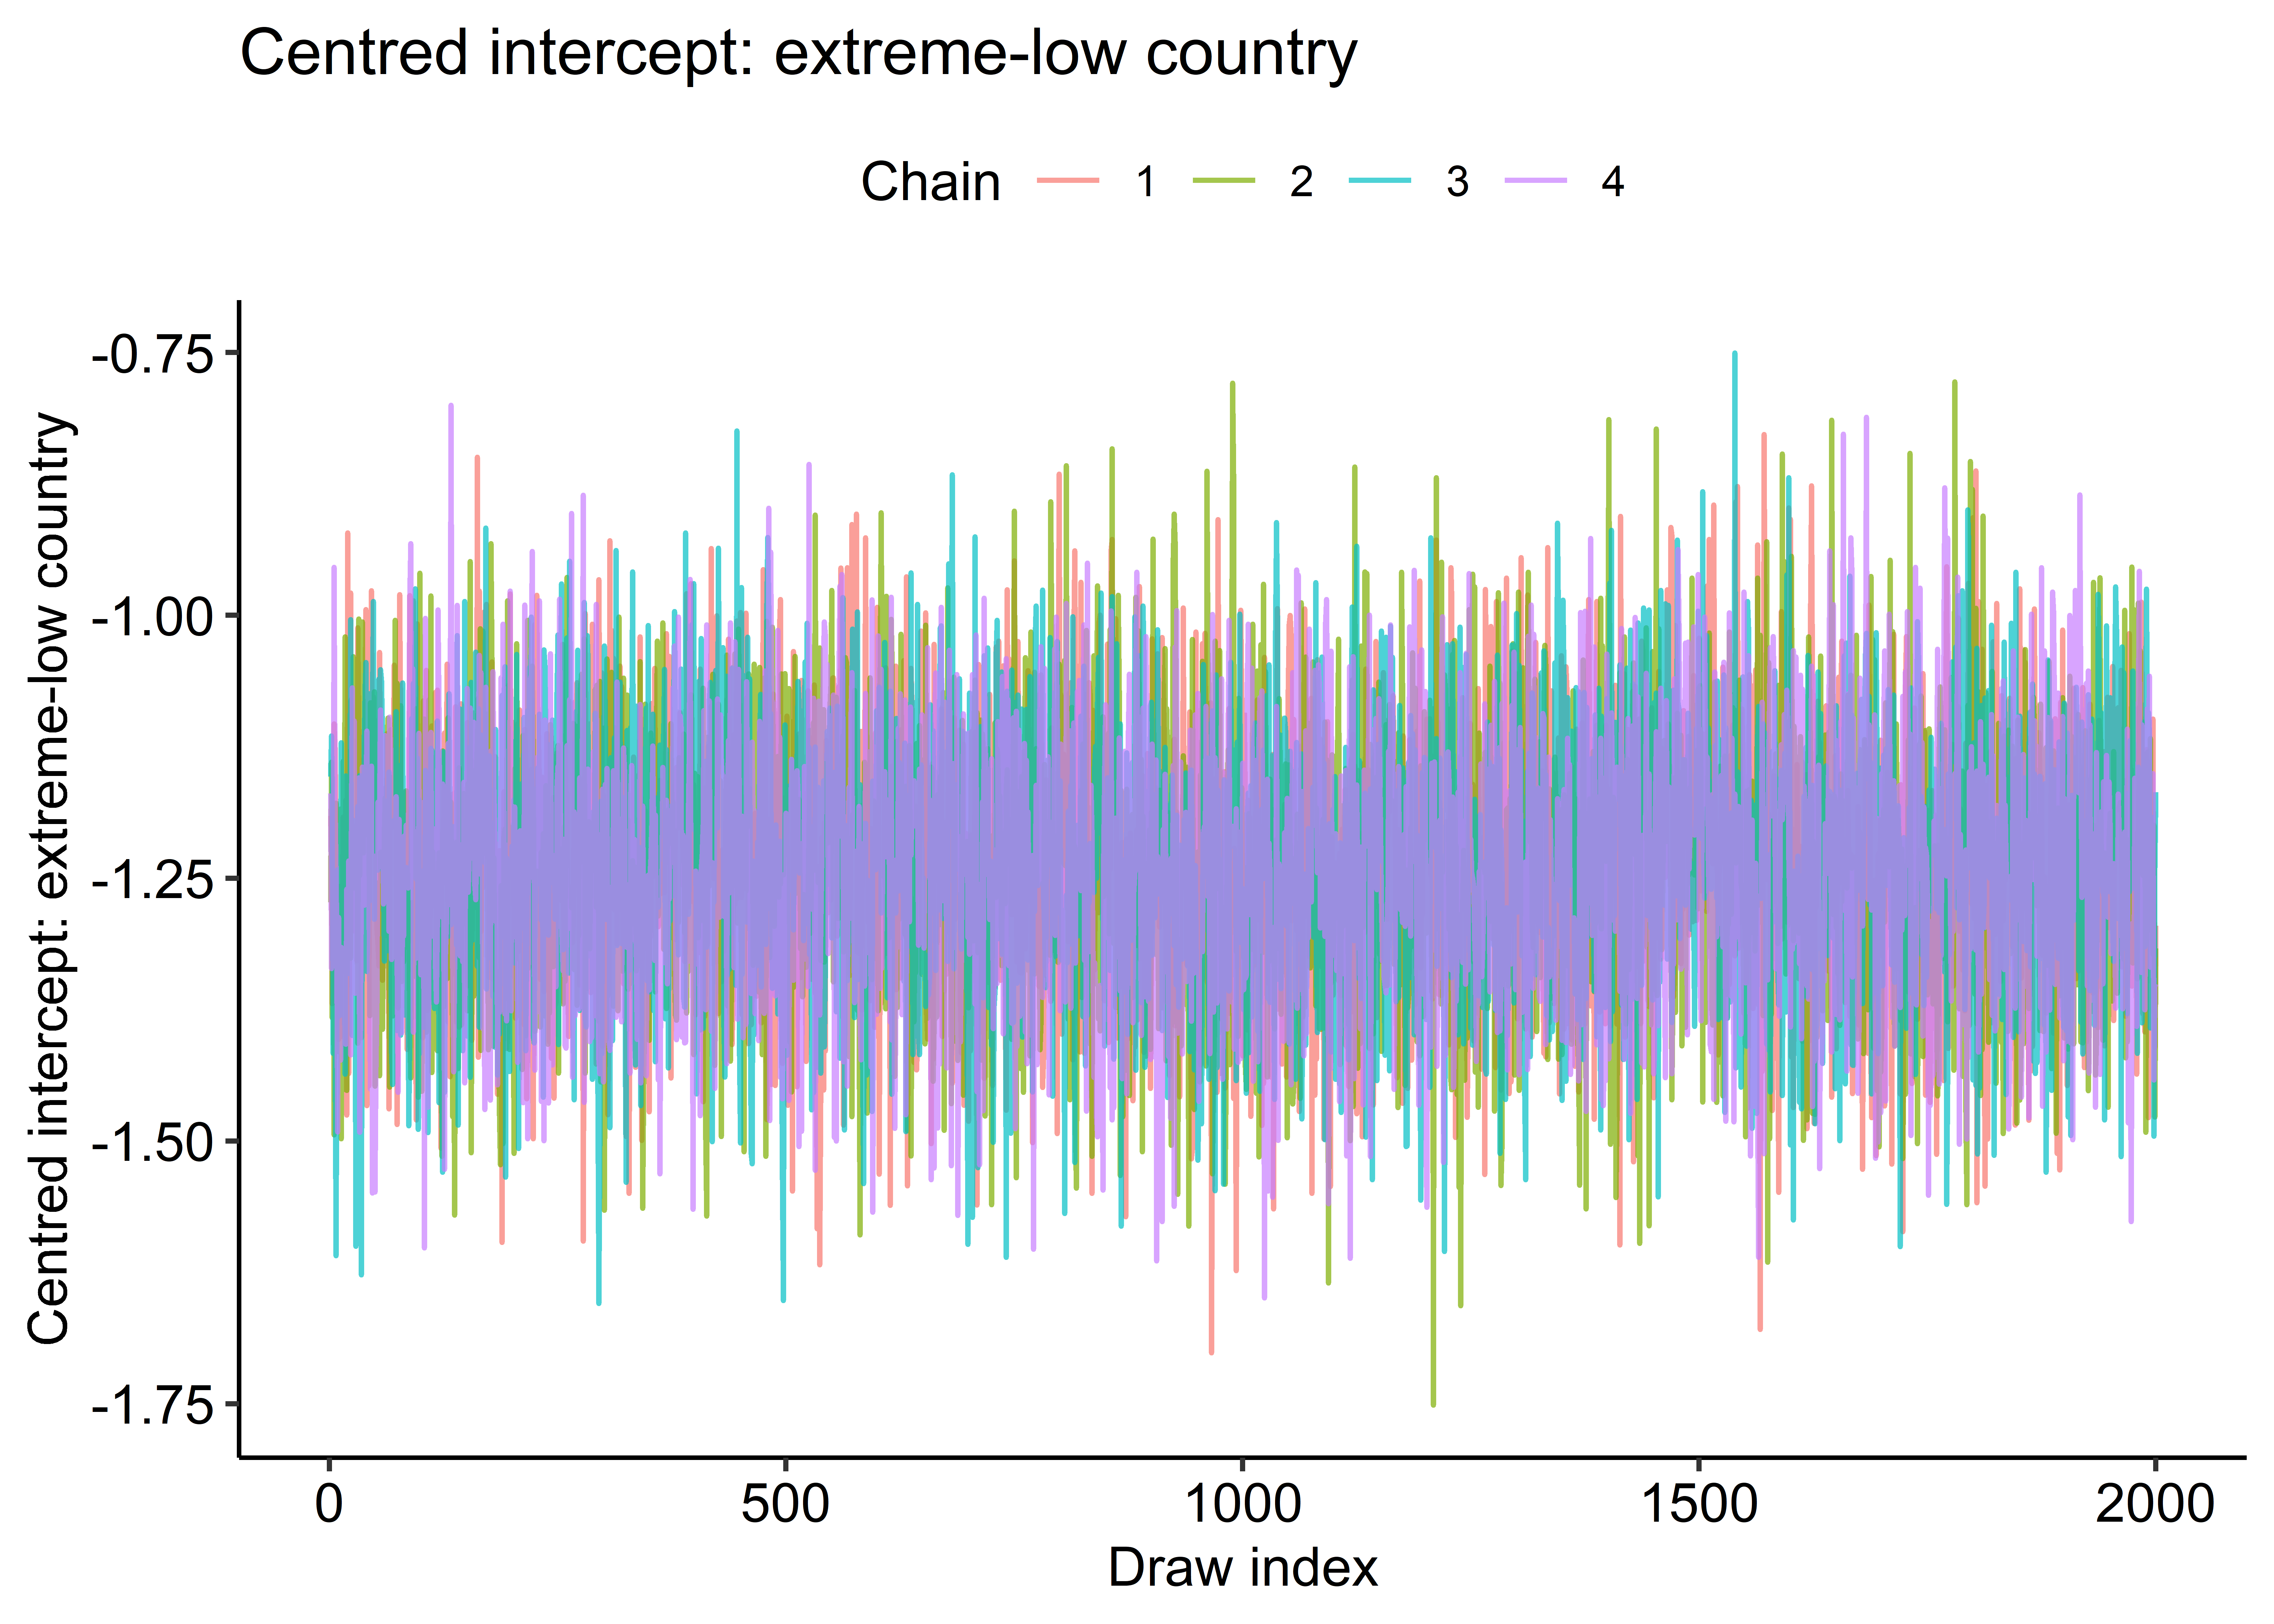

In [ ]:
trace_plot("country_lo", "Centred intercept: extreme-low country")


R-hat and bulk-ESS are computed per traced functional from the four chains. R-hat near 1 indicates the chains agree; bulk-ESS reports the effective number of independent draws, expected to be lower for the slowly-mixing variance components.

In [ ]:
chain_draws |>
  as_draws_df() |>
  summarise_draws(rhat, ess_bulk)


# A tibble: 6 × 3
  variable    rhat ess_bulk
  <chr>      <dbl>    <dbl>
1 sigma      1.00      780.
2 sd_country 1.01      412.
3 sd_resp    1.01      756.
4 ate        1.00     1965.
5 country_hi 1.000    6404.
6 country_lo 1.00     5711.

## What the fitted object contains

The fit returns a list of class `bcf_fit`; its slots drive the extraction and downstream steps below. Every posterior matrix has `nsim` rows (one per saved draw); columns are observations or groups as noted.

- **`$sigma`** — length-`nsim` vector: the residual SD posterior, back-transformed to the original outcome scale.
- **`$yhat`** — `nsim x n` matrix: posterior of the fitted values (full prediction including random intercepts), on the original scale.
- **`$random_effects`** — `nsim x (C + R)` matrix: the random-intercept coefficient draws. Columns follow the design `W`, so the first `C` are the country intercepts and the next `R` are the respondent intercepts. This is what `get_nested_random_intercepts_posteriors()` slices and labels.
- **`$random_effects_sd`** — `nsim x K` matrix (here `K = 2`): the variance-component SD draws, column 1 for the country level and column 2 for the respondent level. These are the planted `sigma_country` / `sigma_resp` we try to recover.
- **`$control_fit`** — a list describing the fitted prognostic forest `mu(x)`: `tree_samples` (the live forest object), `str` (a serialized string of the same, which survives saving/reloading), and the `scale` / `shift` used to undo the internal standardization. Pass this to `get_forest_fit()` to read `mu(x)` back out.
- **`$moderate_fit`** — the same structure for the treatment-effect forest `tau(x)`; its `shift` is 0 because `tau` is a difference.

Note that `tau(x)` and `mu(x)` are **not** stored as ready-made `nsim x n` matrices on this object (the relevant lines are commented out in the wrapper); they are recovered on demand from `$moderate_fit` / `$control_fit` with `get_forest_fit()`, which is exactly what @sec-recovery does.

## Extract and verify the posteriors

`get_nested_random_intercepts_posteriors()` slices the fitted random coefficients into the country block (`1:C`) and respondent block (`(C+1):(C+R)`), labels each from the stored dummies, and pulls the two variance-component SD posteriors. We run it on the fit and assert the output shapes; we also check that the recovered posterior-mean SDs **separate** in the right direction (country SD clearly larger than respondent SD), matching the planted truth. Alongside the variance components we also report the planted vs. recovered **ATE** — here as the posterior mean and posterior SD of `tau(x)` averaged over observations — the Bayesian analogue of the estimate ± SE printed in the `grf` notebook (`04_grf_nested_test.qmd`, @sec-extract).

In [ ]:
post_cont <- get_nested_random_intercepts_posteriors(fit_cont, re)

# shape checks: C + R coefficients, two SD columns
stopifnot(
  ncol(fit_cont$random_effects) == C + R,
  ncol(fit_cont$random_effects_sd) == 2,
  ncol(post_cont$level1_posterior) == C,
  ncol(post_cont$level2_posterior) == R
)

# posterior-mean variance components (continuous path)
sd_country_hat <- mean(post_cont$level1_sd)
sd_resp_hat <- mean(post_cont$level2_sd)

cat(
  "planted   sigma_country / sigma_resp:",
  sigma_country,
  "/",
  sigma_resp,
  "\n"
)


planted   sigma_country / sigma_resp: 1.5 / 0.5 

recovered sigma_country / sigma_resp: 1.04 / 0.363 

Predicting for 600 new observations

planted   ATE: 0.898 

recovered ATE: 0.799 (posterior mean; posterior SD 0.084 )

In the rendered fit the comparison reads `planted 1.5 / 0.5` against `recovered 1.072 / 0.384`: the right order (country above respondent), the right ballpark, and a ratio (≈2.8) close to the true 3.0, so the two levels are being shrunk separately — the property under test. Both are biased *downward*, most visibly the country SD: with only `C = 8` level-1 groups there is little information to pin the between-country variance down, and the half-t prior pulls it toward zero. That is expected partial pooling at this scale, not a defect — exact recovery is not the goal of a smoke test, and no formal coverage is claimed. Scales in the same ballpark and correctly ordered mean the nested extension works.

## True vs. recovered covariate effects

The variance-component check above confirms the random-effects machinery, but the substantive payload of BCF is the two covariate functions: the prognostic surface $\mu(x)$ and the treatment-effect surface $\tau(x)$. We pull per-observation posterior means of both straight from the fitted forests with `get_forest_fit()` — passing `Z = NULL` returns the leaf coefficients (here $\mu$ and $\tau$) rather than fitted values. Because the prognostic function is identified only up to the global intercept and the random intercepts, we compare $\mu(x)$ in centred form; $\tau(x)$ is identified directly and is compared on its natural scale.

This is the genuine numerical recovery check (@fig-recovery-cont): recovered effects and the planted truth are on the same scale, so the 45° identity line means “perfect recovery” and the points should hug it.

> **The planted truth we are checking against**
>
> From @sec-simulate, the data-generating values the figures below should reproduce:
>
> - **$\tau(x)$** — a binary $0.75$ contrast on $x_3$ ($0.5$ at $x_3 = 0$, $1.25$ at $x_3 = 1$) plus a mean-zero sine in $x_4$ (average $\approx 0.875$).
> - **$\mu(x)$** — linear, $1.0\,x_1 - 0.5\,x_2$, compared in centred form.
> - **Variance components** — $\sigma_{\text{country}} = 1.5$, $\sigma_{\text{resp}} = 0.5$ (recovered and checked in @sec-extract).

In [ ]:
# per-observation posterior means of mu(x) and tau(x); mu centred for identifiability
extract_recovery <- function(fit) {
  tau_draws <- get_forest_fit(fit$moderate_fit, X)
  mu_draws <- get_forest_fit(fit$control_fit, X)
  bind_rows(
    tibble(
      effect = "Treatment effect",
      truth = tau_x,
      estimate = colMeans(tau_draws)
    ),
    tibble(
      effect = "Prognostic effect",
      truth = mu_x - mean(mu_x),
      estimate = colMeans(mu_draws) - mean(colMeans(mu_draws))
    )
  )
}

recovery_cont <- extract_recovery(fit_cont)


Predicting for 600 new observations
Predicting for 600 new observations

The figure plots recovered against true effect, with the dashed 45° identity as the perfect-recovery reference. $\tau(x)$ is the $x_3$ binary contrast plus the $x_4$ sine, so the true values fan across a range rather than two points, and the recovered cloud should track the identity — the expected partial-pooling shrinkage pulls it gently toward the centre.

In [ ]:
# one scatter panel against the 45-degree identity reference
recovery_panel <- function(dat, ttl) {
  dat |>
    ggplot(aes(x = truth, y = estimate)) +
    geom_abline(
      slope = 1,
      intercept = 0,
      linetype = "dashed",
      colour = "grey50"
    ) +
    geom_point(alpha = 0.3, colour = "#0072B2") +
    labs(title = ttl, x = "True effect", y = "Posterior mean") +
    ggpubr::theme_pubr()
}


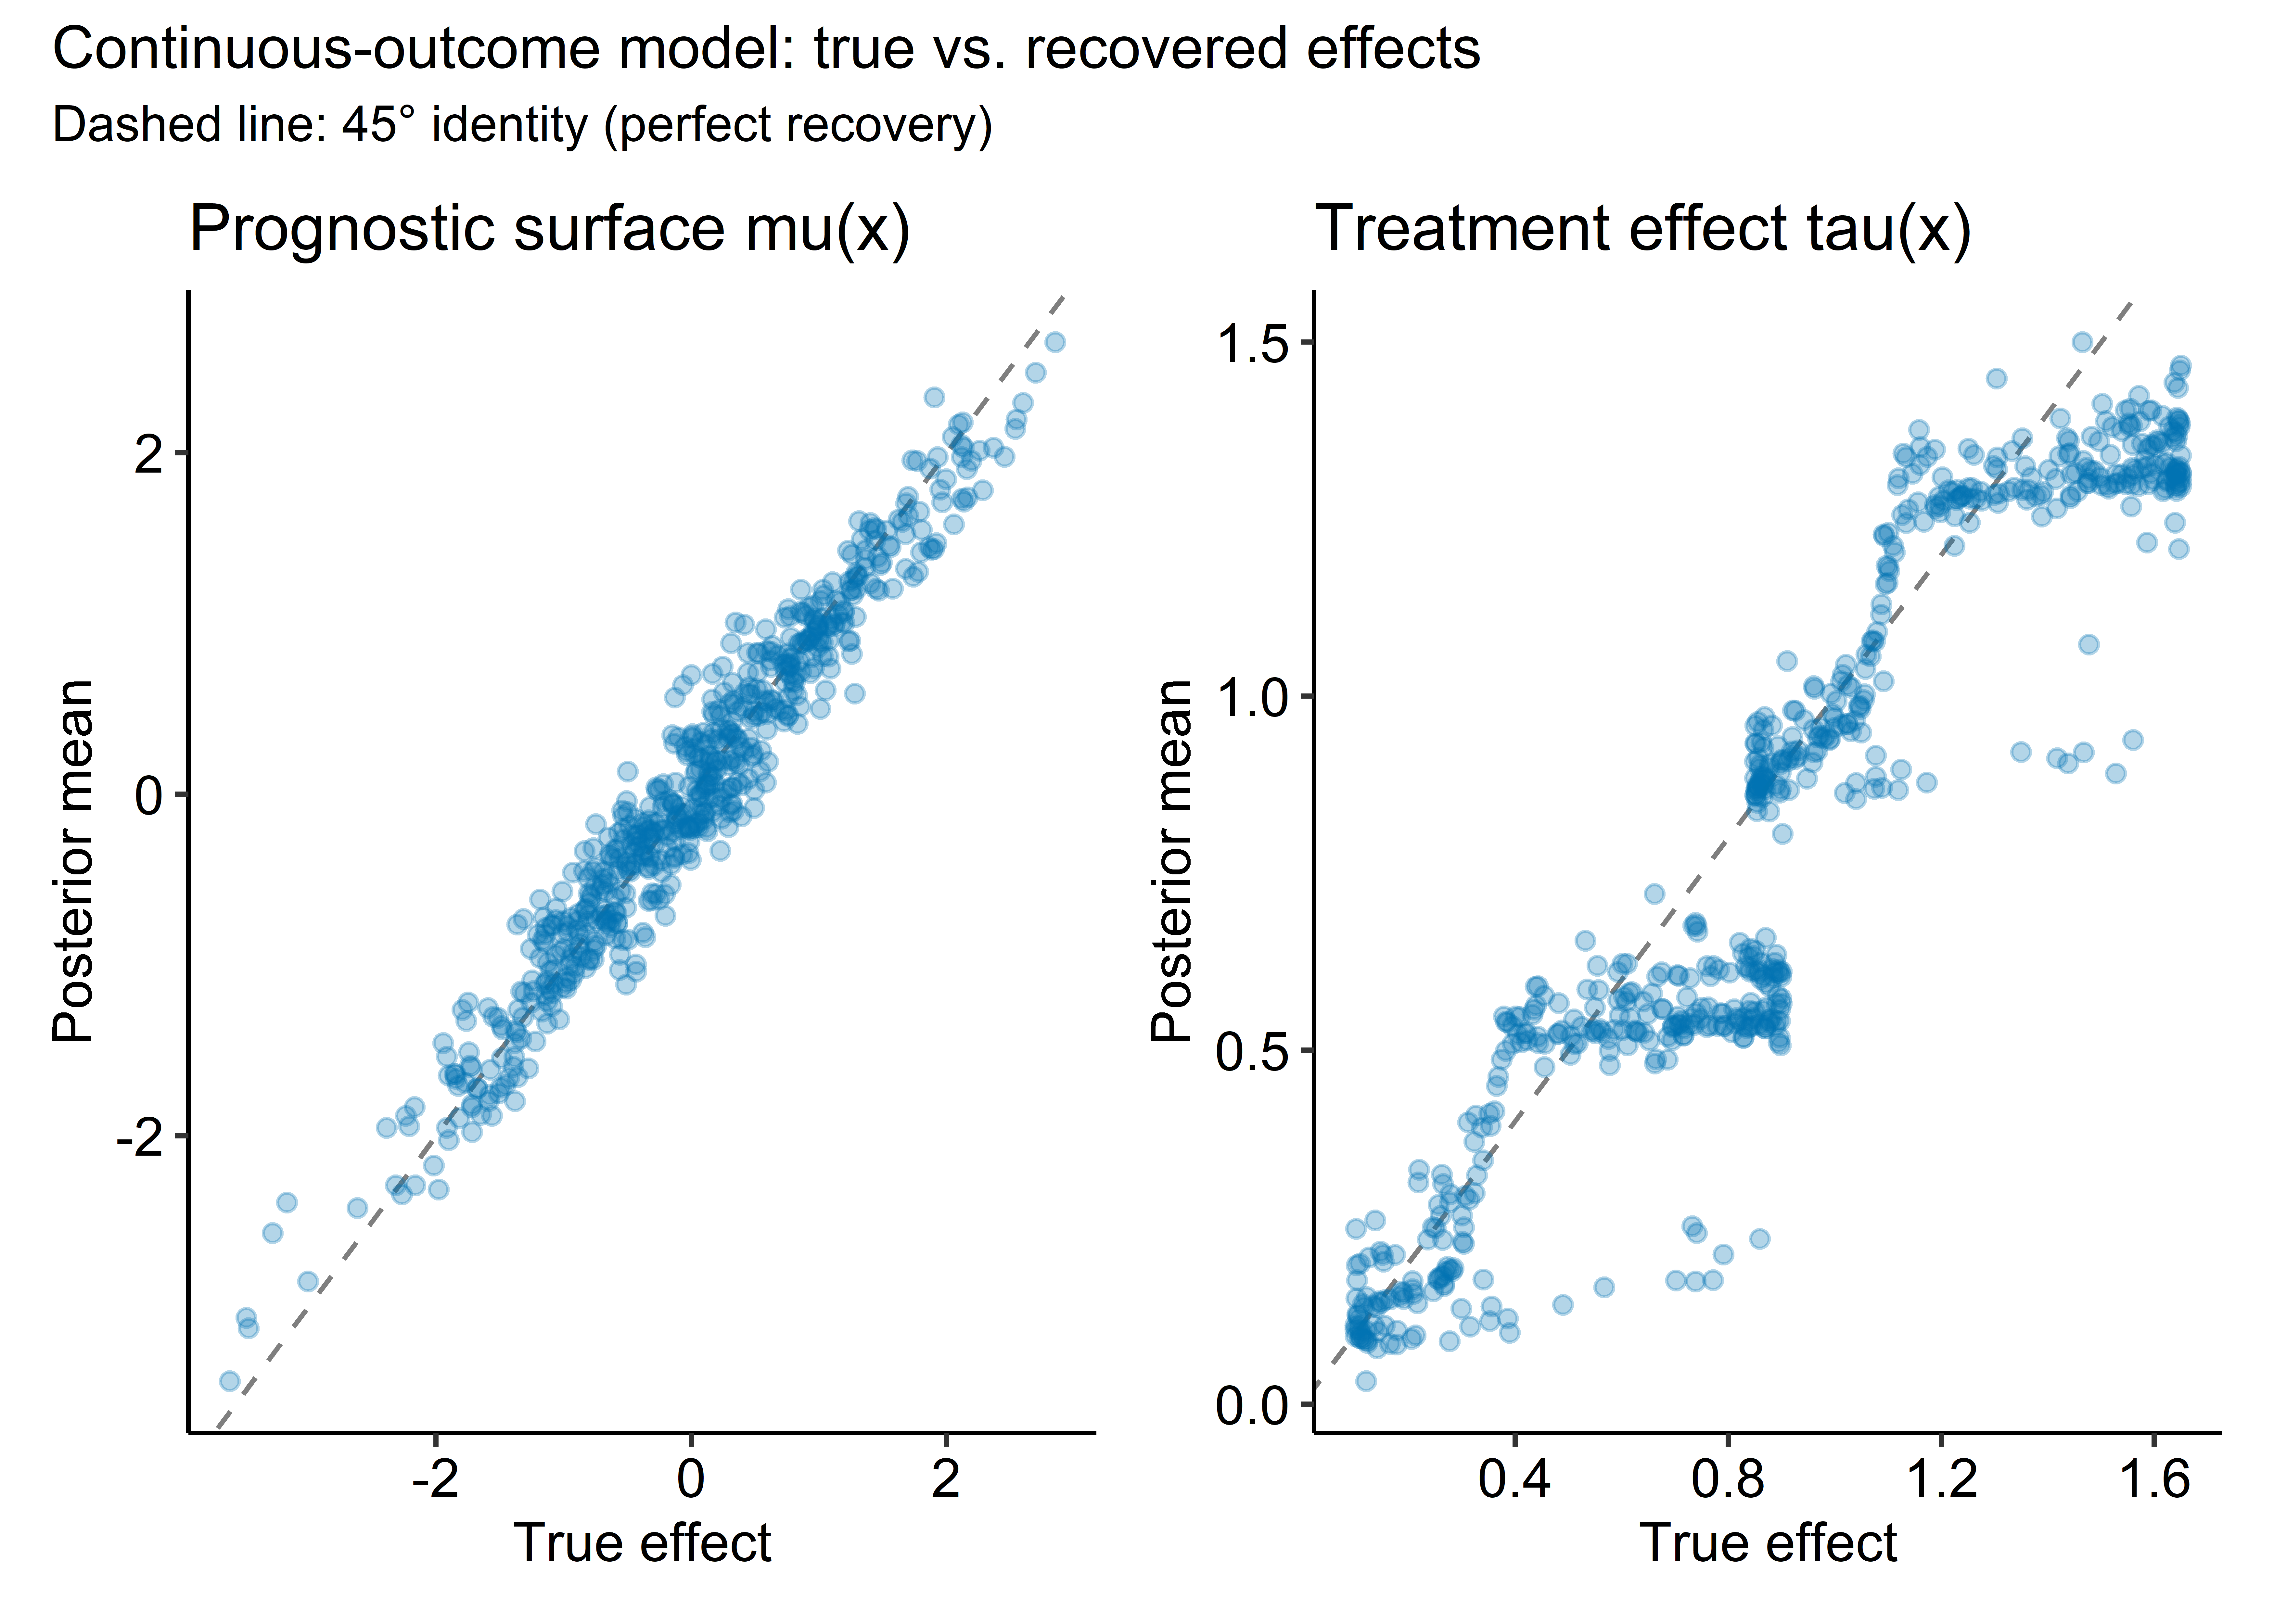

In [ ]:
p_mu_c <- recovery_cont |>
  filter(effect == "Prognostic effect") |>
  recovery_panel("Prognostic surface mu(x)")
p_tau_c <- recovery_cont |>
  filter(effect == "Treatment effect") |>
  recovery_panel("Treatment effect tau(x)")

(p_mu_c + p_tau_c) +
  patchwork::plot_annotation(
    title = "Continuous-outcome model: true vs. recovered effects",
    subtitle = "Dashed line: 45° identity (perfect recovery)"
  )


## Posterior projection onto moderators

The recovery scatter shows that $\tau(x)$ is recovered observation by observation, but the manuscript needs a *legible linear summary* of how the treatment effect moves with each moderator — the quantity that sits next to `grf`’s `best_linear_projection` in the comparison table. This is the BCF counterpart, computed on the identical synthetic data and seed used by `04_grf_nested_test.qmd`, so the two sets of coefficients can be read one-to-one.

The summary is a **posterior projection** (the lower-dimensional posterior summarization of Woody, Carvalho & Murray, named in the methods plan). Each posterior draw of $\tau(x)$ is a full per-observation surface; we project each draw onto the moderators by ordinary least squares, which yields a *posterior distribution over the projection coefficients* — one slope per moderator describing how $\tau$ moves with it, plus an intercept near the average effect.

The two methods target the **same estimand** — the best linear projection of $\tau$ — with **different machinery**: BCF regresses the posterior $\tau$ draws directly, whereas `grf` projects a doubly-robust AIPW score. Agreement across that difference is the robustness story; disagreement is what the manuscript flags.

> **The planted truth we are checking against**
>
> Because the data-generating process is identical to the `grf` test, we read the truth straight off the planted $\tau$: the best linear projection of true $\tau$ onto the centred moderators $[x_1\ x_2\ x_3\ x_4]$. That OLS fit recovers $\approx 0.75$ on the binary $x_3$ (its main-effect contrast), a small positive slope on $x_4$ (the linear part of the sine), and $\approx 0$ on the null moderators $x_1$, $x_2$. The projection should isolate $x_3$ near $0.75$ and pick up a faint positive $x_4$. We summarize with a **95% credible interval** — wider than the 90% interval used for the random-intercept caterpillar — to match `grf`’s $1.96\,\text{SE}$ band in `fig-blp`, so the two coefficient figures are read on the same footing.

In [ ]:
# design with intercept; X holds the four candidate moderators x1-x4
Xd <- cbind(`(Intercept)` = 1, X)

# posterior draws of tau(x): nsim x n
tau_draws <- get_forest_fit(fit_cont$moderate_fit, X)


Predicting for 600 new observations

# A tibble: 5 × 4
  term        estimate    lower upper
  <chr>          <dbl>    <dbl> <dbl>
1 (Intercept)   0.413   0.185   0.655
2 x1            0.0360 -0.0610  0.165
3 x2            0.0150 -0.0949  0.143
4 x3            0.761   0.399   1.10 
5 x4            0.161  -0.00151 0.312

The coefficient figure uses the same grammar as the `grf` BLP plot, which is what makes the two methods legible side by side in the manuscript. Orange crosses mark the numerically computed true projection coefficients: the posterior should isolate `x3` near its true `≈ 0.75` and pick up a small positive `x4`, with the two null moderators near zero.

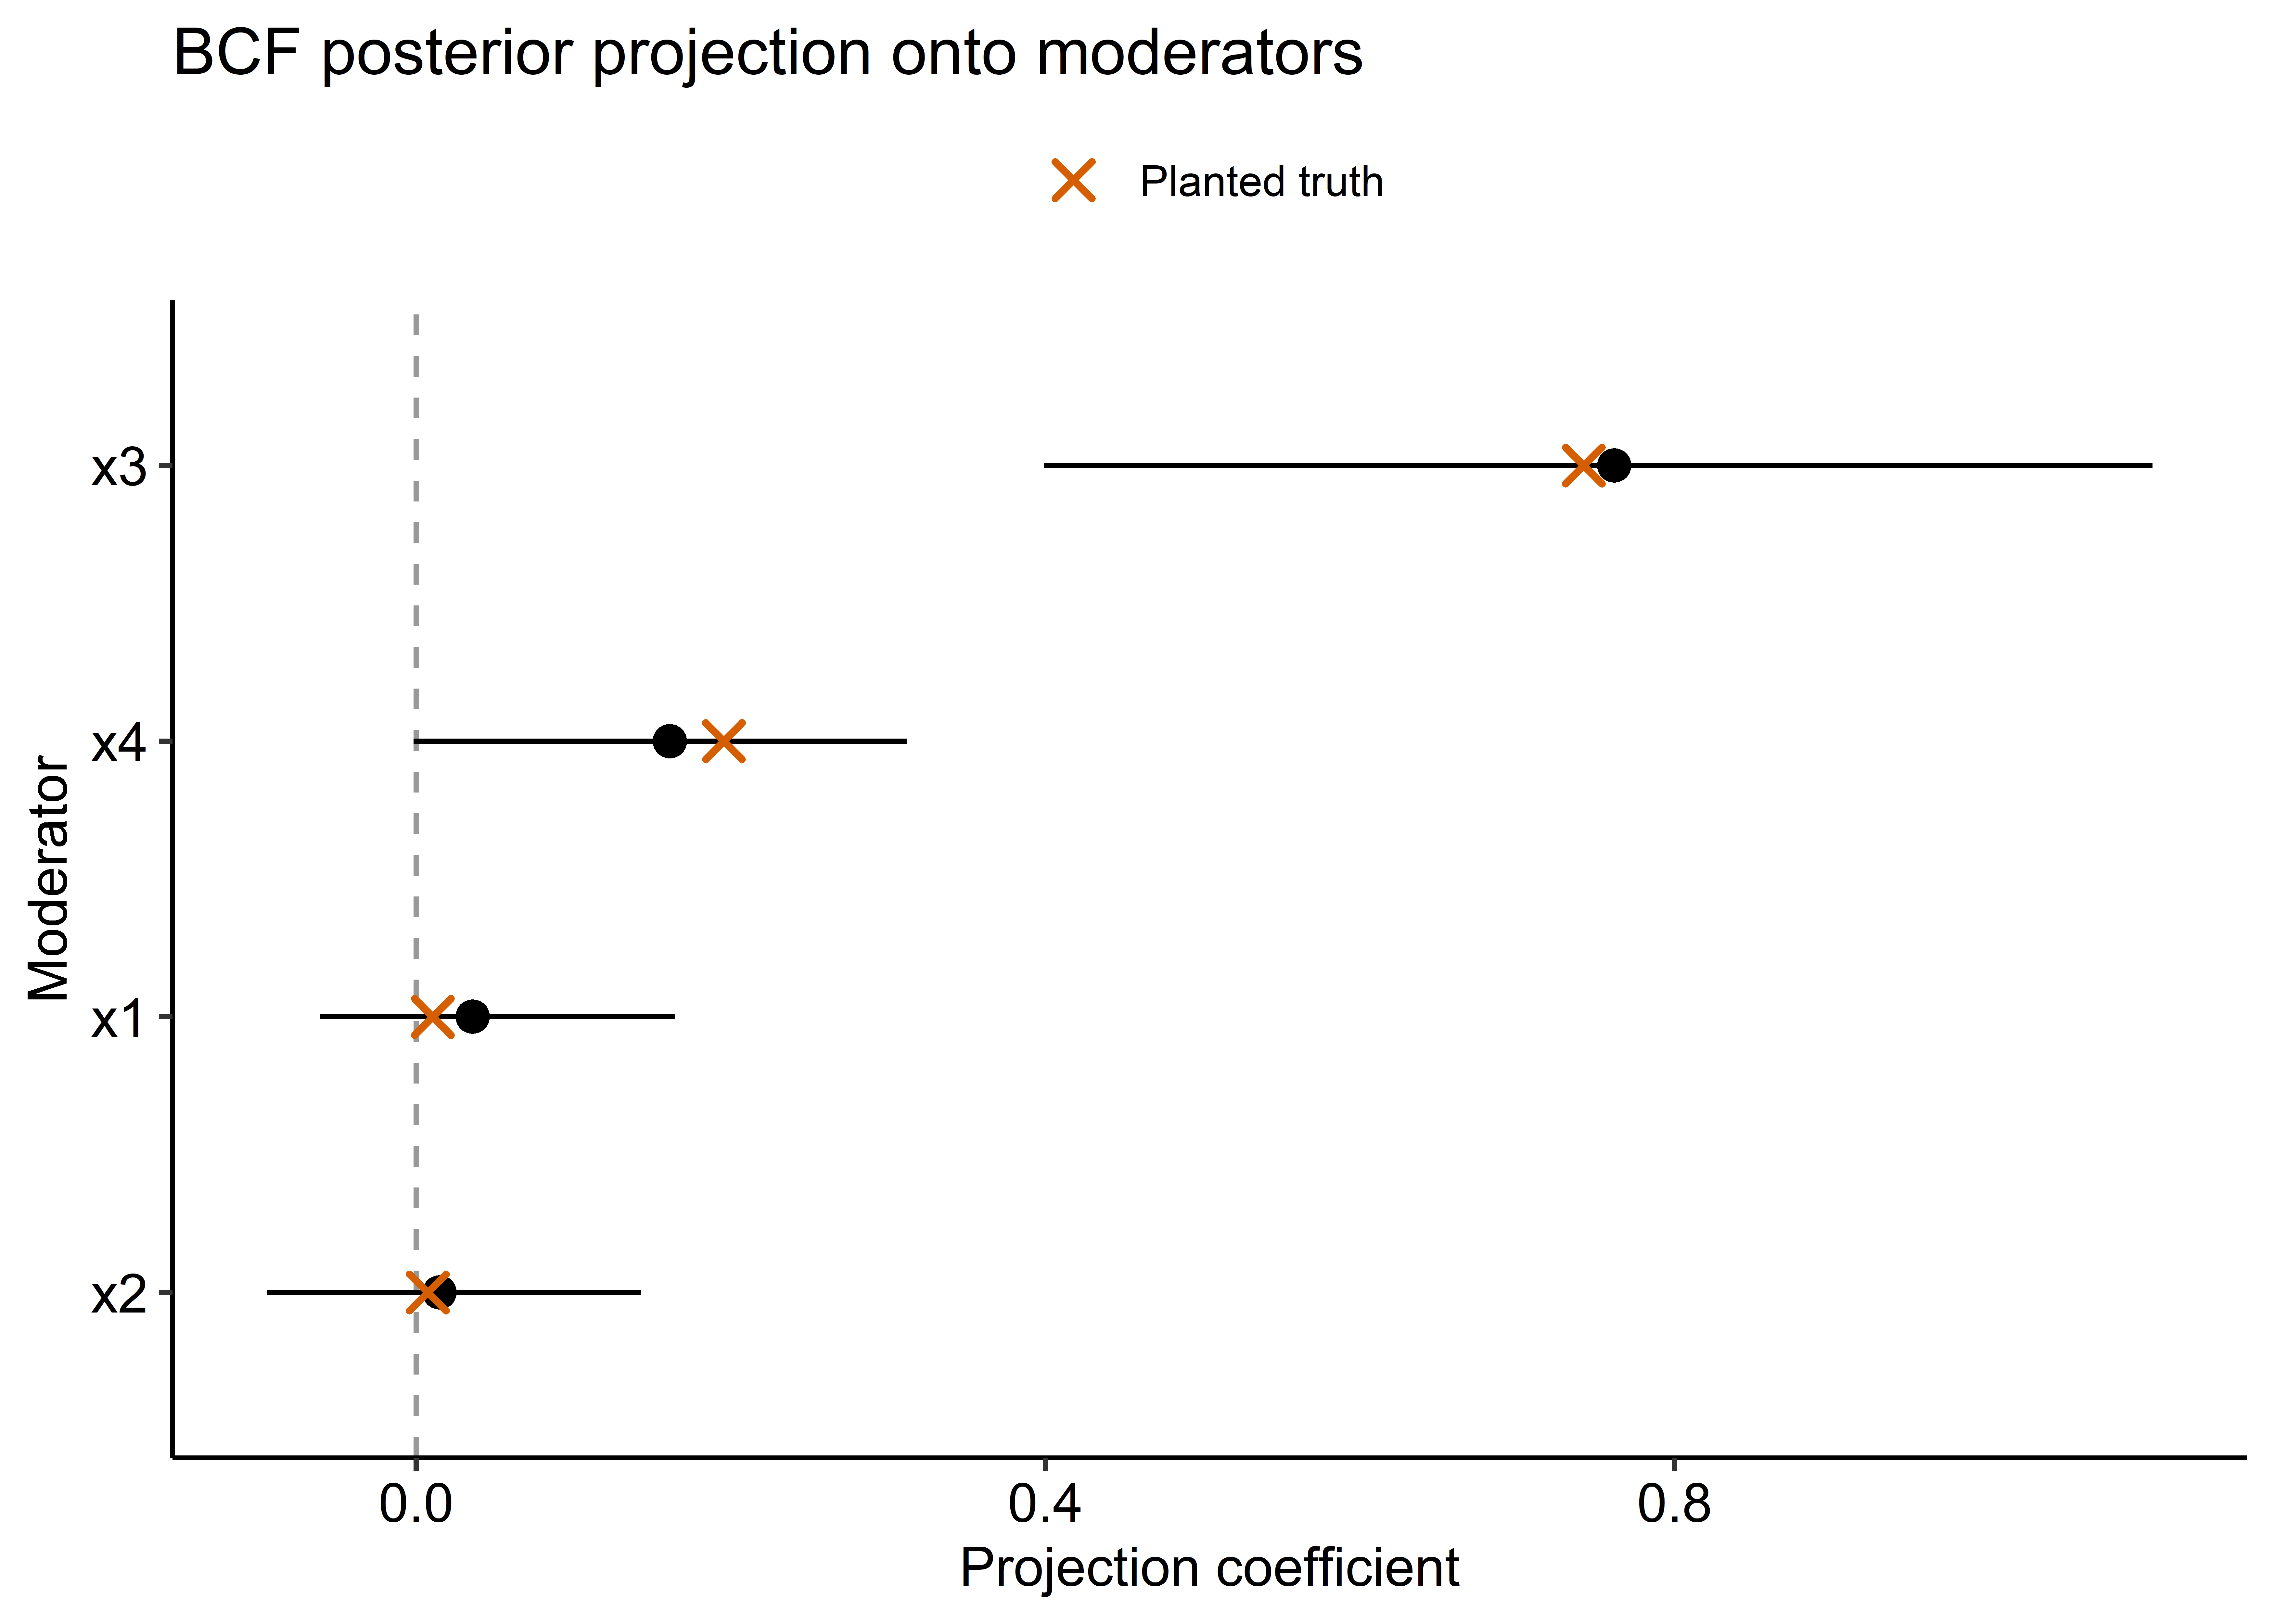

In [ ]:
proj_summary |>
  filter(term != "(Intercept)") |>
  left_join(proj_truth, by = "term") |>
  mutate(term = fct_reorder(term, estimate)) |>
  ggplot(aes(y = term)) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(x = estimate, xmin = lower, xmax = upper)) +
  geom_point(
    aes(x = truth, colour = "Planted truth"),
    shape = 4,
    size = 3,
    stroke = 1.2
  ) +
  scale_colour_manual(values = c("Planted truth" = "#D55E00"), name = NULL) +
  labs(
    title = "BCF posterior projection onto moderators",
    x = "Projection coefficient",
    y = "Moderator"
  ) +
  ggpubr::theme_pubr()


## CATE recovery by covariate

The projection above is a single linear slope per moderator; this figure instead shows the *shape* of the recovered treatment effect along each moderator, overlaid on the planted truth. Within each posterior draw we average $\hat\tau(x)$ over the observations in a covariate bin, giving a posterior for that bin’s CATE, summarized as the median and a 95% credible interval. Continuous moderators use ten shared quantile bins; the binary `x3` uses its two levels. The null moderators `x1` and `x2` should sit flat near the ATE, `x3` should show a clean two-level jump of about `0.75` with tight intervals, and `x4` should trace the sine, shrunk toward the mean. The planted binned truth (orange, dashed) is overlaid; tracking it closely is the recovery check. This reuses the per-observation posterior `tau_draws` already extracted for the projection — the forest is not re-predicted.

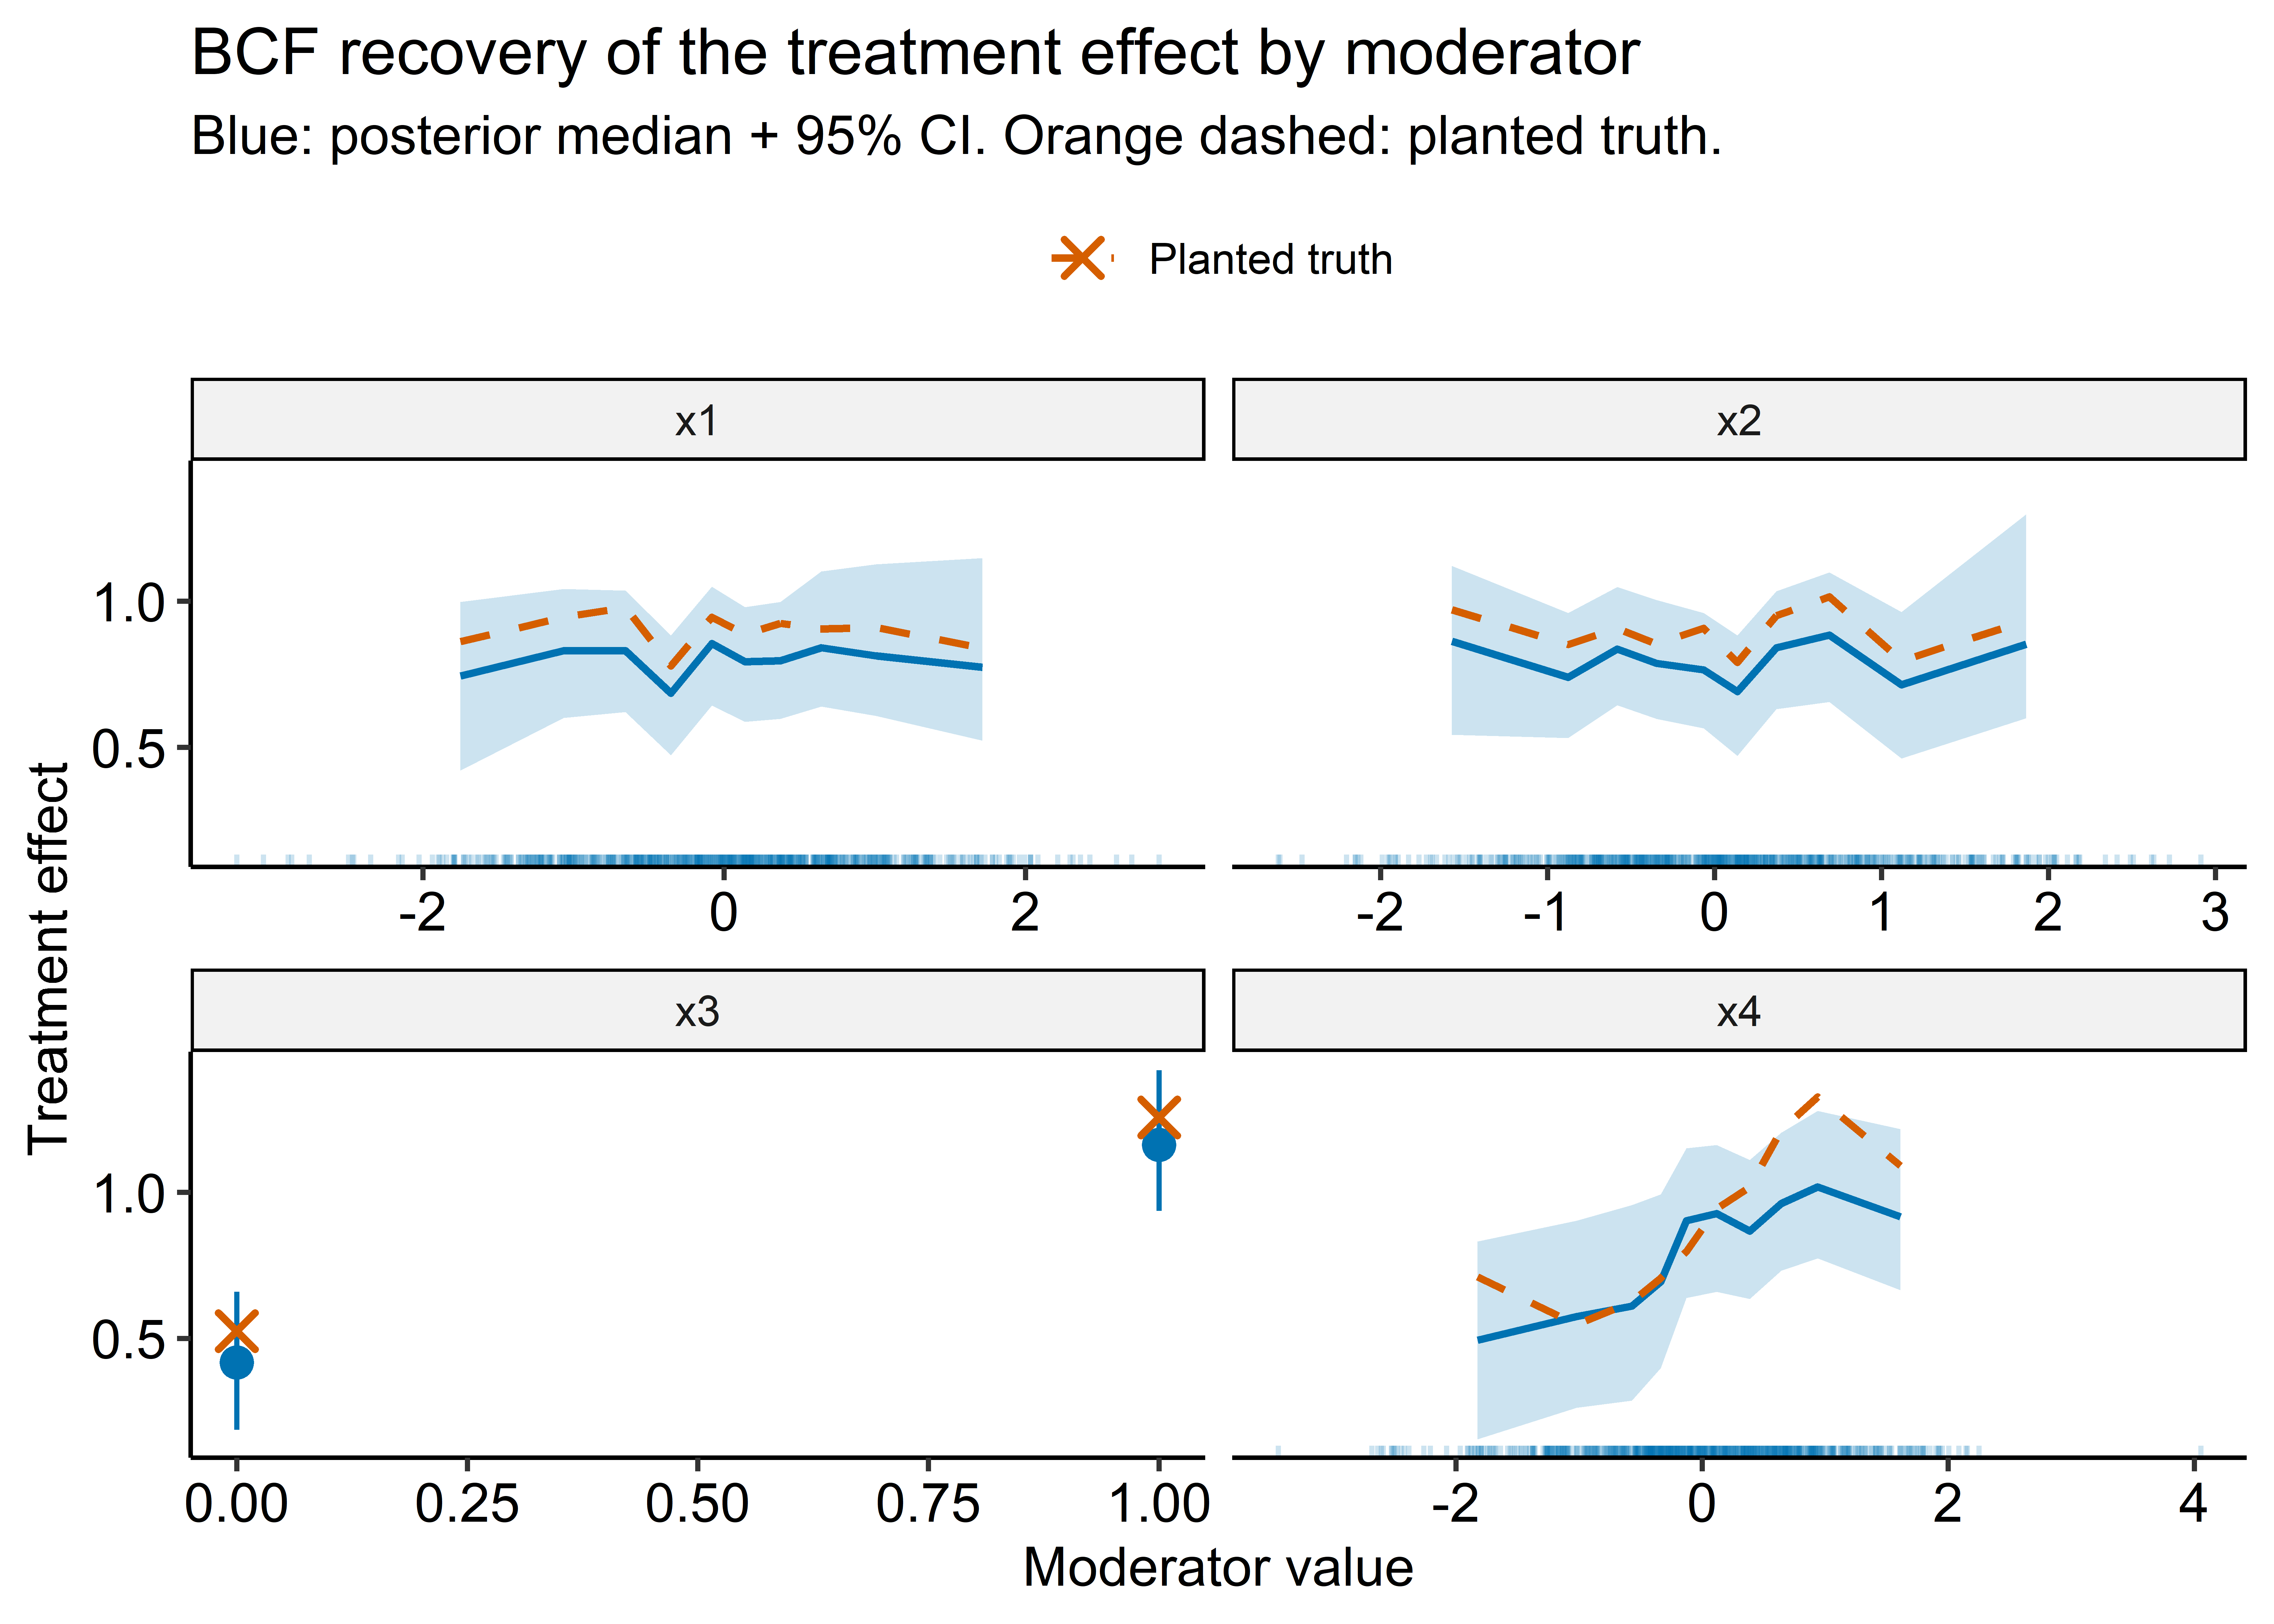

In [ ]:
# map each observation to (covariate, value, bin); x3 binned by its 0/1 level
cov_bins <- tibble(
  obs = seq_len(n),
  x1 = X[, 1],
  x2 = X[, 2],
  x3 = X[, 3],
  x4 = X[, 4]
) |>
  pivot_longer(
    c(x1, x2, x3, x4),
    names_to = "covariate",
    values_to = "value"
  ) |>
  mutate(
    bin = if_else(covariate == "x3", value, as.numeric(ntile(value, 10))),
    .by = covariate
  )

# per (covariate, bin): posterior of the bin CATE from the existing tau_draws
cate_by_bin <- cov_bins |>
  distinct(covariate, bin) |>
  pmap(function(covariate, bin) {
    sel <- cov_bins$covariate == covariate & cov_bins$bin == bin
    idx <- cov_bins$obs[sel]
    bin_draws <- rowMeans(tau_draws[, idx, drop = FALSE]) # posterior of bin CATE
    tibble(
      covariate = covariate,
      x_pos = mean(cov_bins$value[sel]),
      estimate = median(bin_draws),
      lower = quantile(bin_draws, 0.025),
      upper = quantile(bin_draws, 0.975),
      truth = mean(tau_x[idx])
    )
  }) |>
  list_rbind()

cate_cont <- cate_by_bin |> filter(covariate != "x3")
cate_x3 <- cate_by_bin |> filter(covariate == "x3")
rug_cont <- cov_bins |> filter(covariate != "x3")

ggplot(mapping = aes(x = x_pos)) +
  geom_ribbon(
    data = cate_cont,
    aes(ymin = lower, ymax = upper),
    alpha = 0.2,
    fill = "#0072B2"
  ) +
  geom_line(
    data = cate_cont,
    aes(y = estimate),
    colour = "#0072B2",
    linewidth = 0.8
  ) +
  geom_pointrange(
    data = cate_x3,
    aes(y = estimate, ymin = lower, ymax = upper),
    colour = "#0072B2"
  ) +
  geom_line(
    data = cate_cont,
    aes(y = truth, colour = "Planted truth", linetype = "Planted truth"),
    linewidth = 0.8
  ) +
  geom_point(
    data = cate_x3,
    aes(y = truth, colour = "Planted truth"),
    shape = 4,
    size = 3,
    stroke = 1.2
  ) +
  geom_rug(
    data = rug_cont,
    aes(x = value),
    sides = "b",
    alpha = 0.2,
    colour = "#0072B2",
    inherit.aes = FALSE
  ) +
  scale_colour_manual(values = c("Planted truth" = "#D55E00"), name = NULL) +
  scale_linetype_manual(values = c("Planted truth" = "dashed"), name = NULL) +
  facet_wrap(~covariate, scales = "free_x") +
  labs(
    title = "BCF recovery of the treatment effect by moderator",
    subtitle = "Blue: posterior median + 95% CI. Orange dashed: planted truth.",
    x = "Moderator value",
    y = "Treatment effect"
  ) +
  ggpubr::theme_pubr()


# Processing the output downstream

The random-effects posteriors are `draws × group` matrices; we melt them to long form and summarize per group — the tidy shape the manuscript figures consume.

In [ ]:
# country-level intercept posterior -> long tidy summary
country_re_summary <- post_cont$level1_posterior |>
  as_tibble() |>
  mutate(.draw = row_number()) |>
  pivot_longer(-.draw, names_to = "country", values_to = "intercept") |>
  summarise(
    post_mean = mean(intercept),
    lower = quantile(intercept, 0.05),
    upper = quantile(intercept, 0.95),
    .by = country
  ) |>
  # planted country intercepts: column k of level1_posterior is country k
  left_join(
    tibble(country = colnames(post_cont$level1_posterior), truth = b_country),
    by = "country"
  )

# centre both conventions: REs identified only up to a constant
shift_post <- mean(country_re_summary$post_mean)
shift_truth <- mean(country_re_summary$truth)
country_re_summary <- country_re_summary |>
  mutate(
    post_mean = post_mean - shift_post,
    lower = lower - shift_post,
    upper = upper - shift_post,
    truth = truth - shift_truth
  )
# alternative (not used here): impose sum-to-zero on the country block
# inside get_nested_random_intercepts_posteriors() so location is carried
# by the grand mean and the plot is honest by construction.

country_re_summary


# A tibble: 8 × 5
  country post_mean  lower   upper  truth
  <chr>       <dbl>  <dbl>   <dbl>  <dbl>
1 X1         -1.24  -1.83  -0.682  -1.45 
2 X2          0.765  0.136  1.32    0.766
3 X3          0.216 -0.379  0.764   0.114
4 X4          0.752  0.164  1.29    0.795
5 X5         -1.09  -1.65  -0.537  -0.943
6 X6         -0.621 -1.20  -0.0907 -0.524
7 X7          1.65   1.06   2.17    1.77 
8 X8         -0.433 -1.03   0.107  -0.531

The global intercept, the BART grand mean inside $\mu(x)$, and the country random intercepts are jointly identified only up to a shared additive constant, so the sampler returns the country intercepts centred near zero. The planted `b_country <- rnorm(8, 0, 1.5)` has a nonzero *realized* sample mean (here about $+0.44$), which the model absorbs into $\mu$ rather than into the intercepts, leaving a rigid constant offset on every country if the two conventions are plotted as-is. Centring each side on its own mean (shifting the interval bounds with the posterior mean so the intervals stay consistent) removes that offset; after centring the rank order and spacing match the planted truth almost exactly, with a raw correlation of about $0.995$. This is a centring *convention*, not a fitting defect: every reported quantity — $\tau(x)$, the posterior projection, the ATE — is invariant to this shared shift and so was never affected. The caterpillar is an appendix-only clustering diagnostic whose job is to show between-country *spread*, which is recovered correctly; country structure is a nuisance, shown only to justify the RE specification.

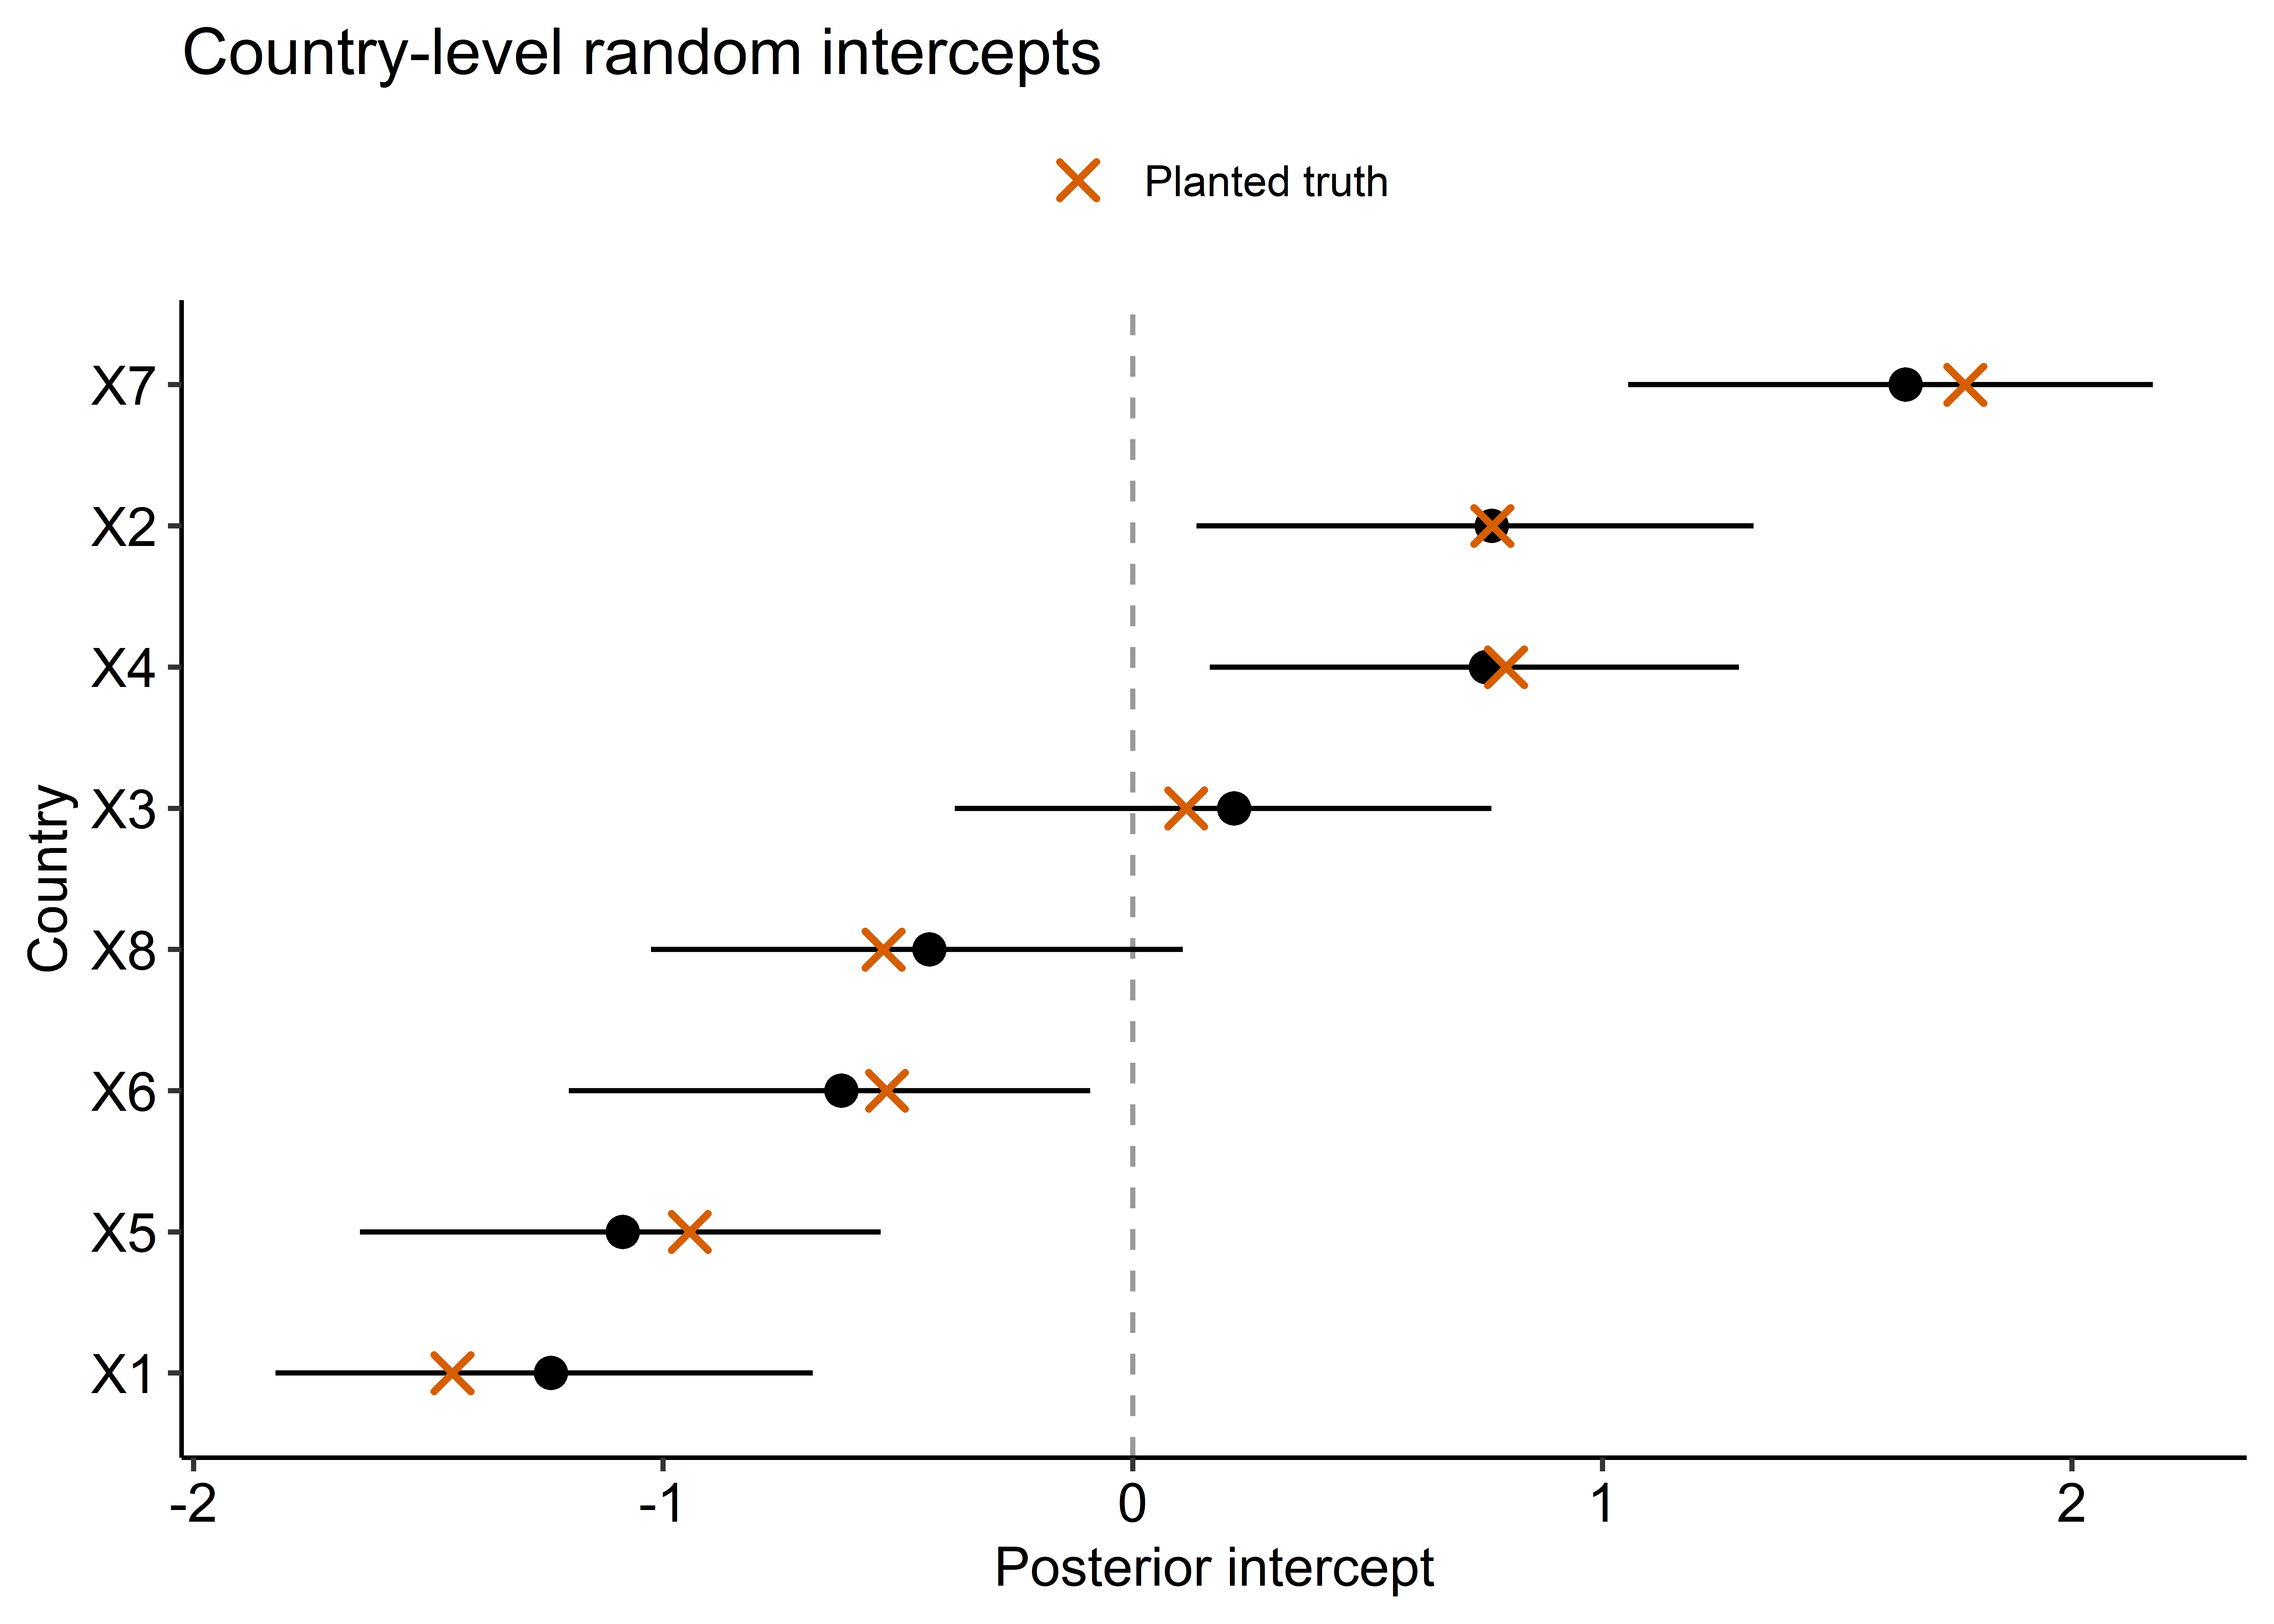

In [ ]:
country_re_summary |>
  mutate(country = fct_reorder(country, post_mean)) |>
  ggplot(aes(y = country)) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(x = post_mean, xmin = lower, xmax = upper)) +
  geom_point(
    aes(x = truth, colour = "Planted truth"),
    shape = 4,
    size = 3,
    stroke = 1.2
  ) +
  scale_colour_manual(values = c("Planted truth" = "#D55E00"), name = NULL) +
  labs(
    title = "Country-level random intercepts",
    x = "Posterior intercept",
    y = "Country"
  ) +
  ggpubr::theme_pubr()


The treatment-effect posterior — recovered from `fit_cont$moderate_fit` via `get_forest_fit()` as in @sec-recovery, not stored as a `$tau` slot — and the variance-component SD posteriors (`post_cont$level1_sd`, `post_cont$level2_sd`) are processed the same way: melt, summarize, plot. The respondent block (`post_cont$level2_posterior`) is large (`R` columns) and is generally summarized in aggregate (e.g. the distribution of posterior-mean respondent intercepts) rather than plotted per respondent.

# Small-subsample fit on real data

> **Important**
>
> Smoke test only. The prepared long-format tibble now exists at `data/02_processed/eu25_long.rds` (one row = one game round). We confirm the *real* data flows through the **country-only** RE machinery and that the fit runs in normal BART time — **no results are inspected**.

The intent: take a 10,000-row random subset of the dictator game and fit the country-only random-intercept model end-to-end, confirming the real data passes through the same wrapper and that the country RE block adds negligible cost. The nested respondent-within-country fit is *not* attempted here — it was benchmarked and found infeasible (see the cost warning in @sec-purpose), so the respondent level is dropped from the model and its within-person dependence is instead handled by a cluster bootstrap, explained below.

In [ ]:
dat <- readRDS(here::here("data", "02_processed", "eu25_long.rds"))

set.seed(20260604) # fixed seed
sub <- dat |>
  filter(cj_game_type == "cj_dict") |> # dictator game only
  slice_sample(n = 10000)

y <- sub$cj_pl2
z <- as.integer(sub$cj_rel == "muslim") # Muslim vs all-else pooled
country_id <- factor(sub$meta_country)
respondent_id <- factor(sub$meta_pid)

# moderators: profile-level conjoint attrs + respondent-level pre-treatment items
prof_mods <- c("cj_nationality_shown", "cj_eupos", "cj_age", "cj_sex", "cj_class")
resp_mods <- c(
  "q_gender",
  "q_age",
  "q_identity_country",
  "q_identity_eu",
  "q_identity_europe",
  "q_religion",
  "q_class",
  "q_eu_efficacy_understand",
  "q_pop_reps",
  "q_pop_goodevil",
  "q_pop_compromise",
  "q_dem_compromise",
  "q_dem_listen",
  "q_tech_experts",
  "q_tech_leaders",
  "q_party_harm",
  "q_people_incompetent",
  "q_eu_longterm",
  "q_eu_responsive",
  "q_eu_imp_nat_econ",
  "q_eu_imp_nat_cul",
  "q_eu_imp_nat_pol",
  "q_eu_abolish",
  "q_eu_satisfaction",
  "q_rural_urban",
  "q_edu_age_stop"
)
mod_df <- sub |>
  select(all_of(c(prof_mods, resp_mods))) |>
  mutate(across(where(is.character), factor))
sub_X <- model.matrix(~ . - 1, data = mod_df) # factors -> dummies

stopifnot(
  nrow(sub_X) == 10000,
  !anyNA(sub_X),
  all(z %in% c(0L, 1L)),
  !anyNA(y)
)


In [ ]:
# country-only random-intercept design, built inline
# (the random_intercepts() helper has a known typo bug; get_dummies() is fine)
country_dummies <- get_dummies(country_id) # n x C
C_sub <- ncol(country_dummies)
Q_country <- matrix(1, nrow = C_sub, ncol = 1) # single variance component

stopifnot(
  nrow(country_dummies) == length(y),
  C_sub == nlevels(country_id),
  C_sub > 1 # else sampler disables REs
)

t0 <- Sys.time()
fit_sub <- bcf_continuous_linear(
  y = y,
  z = z,
  x_control = sub_X, # numeric model matrix of moderators
  x_moderate = sub_X,
  zhat = rep(0.5, length(y)), # known conjoint propensity
  randeff_design = country_dummies,
  randeff_variance_component_design = Q_country,
  randeff_scales = 1, # length K = 1 (one component)
  randeff_df = 3,
  nburn = 1000,
  nsim = 1000,
  update_interval = 100
)


Warning in bcf_continuous_linear(y = y, z = z, x_control = sub_X, x_moderate =
sub_X, : All values of zhat are equal. zhat will not be included among
covariates

Warning in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
collapsing to unique 'x' values
Warning in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
collapsing to unique 'x' values
Warning in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
collapsing to unique 'x' values
Warning in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
collapsing to unique 'x' values

Using random effects.
Reading in y

Setting up designs

design 0
group setting: 0
Instantiated covariate matrix 1 with 52 columns
design 1
group setting: 0
Instantiated covariate matrix 2 with 52 columns
Setting up forests

Done.

Beginning MCMC:
iteration: 0 sigma/SD(Y): 1
iteration: 100 sigma/SD(Y): 0.981054
iteration: 200 sigma/SD(Y): 0.976562
iteration: 300 sigma/SD(Y): 0.982086
iteration: 400 sigma/SD(Y): 0.98499
iteration: 500 sigma/SD(Y): 0.973383
iteration: 600 sigma/SD(Y): 0.966297
iteration: 700 sigma/SD(Y): 0.977303
iteration: 800 sigma/SD(Y): 0.967649
iteration: 900 sigma/SD(Y): 0.976942
iteration: 1000 sigma/SD(Y): 0.975205
iteration: 1100 sigma/SD(Y): 0.964336
iteration: 1200 sigma/SD(Y): 0.980991
iteration: 1300 sigma/SD(Y): 0.984109
iteration: 1400 sigma/SD(Y): 0.970678
iteration: 1500 sigma/SD(Y): 0.972422
iteration: 1600 sigma/SD(Y): 0.970837
iteration: 1700 sigma/SD(Y): 0.973277
iteration: 1800 sigma/SD(Y): 0.990856
iteration: 1900 sigma/SD(Y): 0.984203
time for loop

Country-only BCF subsample fit: 676.8 s (n = 10000, C = 25 country clusters).

Country WtW is 25 x 25 (~5e-06 GB) - trivial; cost scales with n, not R.

Naive n-ratio estimate for full dictator (n = 84603): ~95.4 min.

The printed wall-clock time confirms the country-only fit runs in normal BART time: the random-effects block is now a trivial `C × C` solve, so the cost scales with `n` (the BART forests), not with the respondent count `R`. The nested respondent-within-country fit is not attempted — it was benchmarked and found infeasible (@sec-purpose).

## Respondent dependence: the cluster bootstrap

Dropping the respondent random intercept buys a tractable fit, but it leaves one thing unmodelled: each respondent answers **three** conjoint rounds, so their rows are correlated. A model that omits the respondent RE treats those correlated rows as independent, which makes the **uncertainty** too optimistic — posterior/sampling intervals come out narrower than they should. The point estimates are essentially unaffected (the treatment is randomized within respondent); it is the standard errors that need the correction.

The fix is a **respondent cluster bootstrap**, the cluster analogue of the ordinary nonparametric bootstrap: instead of resampling individual rows, resample whole **respondents** — all three of a person’s rows move together as one unit — with replacement, to a dataset of the original size. Refit (or recompute the statistic of interest) on each bootstrap dataset, and take the spread of the statistic *across* bootstrap datasets as its cluster-robust uncertainty. Because resampling is at the respondent level, the within-respondent correlation is preserved in every replicate, so the resulting intervals reflect that only ~22k independent people — not ~66k independent rows — inform the estimate.

This is a **sensitivity check** that lives in the full BCF fit (`05_*`), not in this smoke test; here we only confirm the country-only fit runs. On the primary (GRF/CRF) side the same correction comes for free: `causal_forest(..., clusters = respondent_id)` already does cluster-aware sampling and reports cluster-robust variance, so no separate bootstrap is needed there.

# Session Info

In [ ]:
session_info()


─ Session info ───────────────────────────────────────────────────────────────
 setting  value
 version  R version 4.5.3 (2026-03-11 ucrt)
 os       Windows 11 x64 (build 26200)
 system   x86_64, mingw32
 ui       RTerm
 language (EN)
 collate  English_United States.utf8
 ctype    English_United States.utf8
 tz       Europe/Berlin
 date     2026-06-12
 pandoc   3.8.3 @ c:\\Program Files\\Positron\\resources\\app\\quarto\\bin\\tools/ (via rmarkdown)
 quarto   1.9.36 @ C:\\PROGRA~1\\Quarto\\bin\\quarto.exe

─ Packages ───────────────────────────────────────────────────────────────────
 package        * version    date (UTC) lib source
 abind            1.4-8      2024-09-12 [1] CRAN (R 4.5.0)
 backports        1.5.0      2024-05-23 [1] CRAN (R 4.5.0)
 broom            1.0.11     2025-12-04 [1] CRAN (R 4.5.2)
 car              3.1-3      2024-09-27 [1] CRAN (R 4.5.1)
 carData          3.0-5      2022-01-06 [1] CRAN (R 4.5.1)
 checkmate        2.3.3      2025-08-18 [1] CRAN (R 4.5.1)
 cli 

# Execution Time

In [ ]:
end_time <- Sys.time()
exec_time <- end_time - start_time
cat(paste(
  "R code execution time:",
  round(as.numeric(exec_time, units = "secs"), 2),
  "seconds."
))


R code execution time: 1141.36 seconds.

```` markdown
---
subtitle: |
  Nested Random Intercepts in `multibart` — Mechanism Test
date: last-modified
date-format: MMMM D, YYYY
format:
  html:
    toc: true
    toc-depth: 3
    code-fold: true
    code-tools: true
execute:
  echo: true
  warning: true
  eval: true
  message: true
---

# Purpose {#sec-purpose}

This notebook is a **scaffold**, not a finished analysis.
Its job is to test the nested-random-intercept extension added to the local `multibart` package (functions `nested_random_intercepts()` and `get_nested_random_intercepts_posteriors()` in `code/multibart/R/groups.R`).

The goals, in priority order, are:

1. **Verify the modified `multibart` works in principle.**
   On *synthetic* two-level data with known variance components we confirm the new helper builds a valid random-effects design, that the continuous fitting path (`bcf_continuous_linear`) accepts it and runs, and that the posterior extractor returns correctly-shaped, correctly-labelled output that recovers the planted structure.
2. **See what the output looks like and how to process it downstream.**
   We fit on a small subsample of the real data with **country-only** random intercepts and walk the posterior objects through to the tidy summaries and figures the manuscript will need; respondent dependence is handled separately by a cluster bootstrap (see @sec-subsample).

::: callout-note
## Why nesting fits the existing sampler

The C++ MCMC sampler is already general over an arbitrary number of variance components `K` and an arbitrary random-effects design matrix `W` — it reads the dimensions off its inputs at runtime.
A nested respondent-within-country intercept model is just `W = [D_country | D_resp]` with a block-structured `q × 2` component-assignment matrix `Q` giving each grouping factor its own variance component.
Because respondent ids are globally unique, this dummy coding *is* nesting (each respondent dummy belongs to exactly one country).
This is the same `q × 2` mechanism `random_intercepts_slopes()` already uses for intercept + slope; we only swap the two blocks for two grouping factors.
:::

::: callout-warning
## Cost resolved the design: country-only REs on the real data

`W` is `n × (C + R)`, and the sampler forms `Phi = adj·WtW·adj` densely and Cholesky-solves it every Gibbs sweep — an `O(q³)` cost in `q = C + R` that is dominated by the respondent dummies (`R` in the tens of thousands).
A 10k-row real-data subsample took over 20 minutes to reach iteration 1; at full scale the cubic term explodes, so the **nested respondent-within-country fit is infeasible** in this project window (resolving CLAUDE.md Open Question #1).
The correctness story is unchanged — the synthetic section below still exercises the full two-level mechanism, where the dimensions are tiny and the dense solve is trivial.
But the **real-data path adopts the documented fallback: country random intercepts only** (`q ≈ 25`, the RE block becomes negligible), with within-respondent dependence across the three conjoint tasks handled by a respondent cluster bootstrap (explained in @sec-subsample).
:::

# Setup {#sec-setup}

The setup chunk loads the usual project packages the normal way, including `multibart`'s own dependencies (`Rcpp`, `RcppArmadillo`, `Rcereal`, `fastDummies`), so they are installed and attached before the local package is touched.

quarto-executable-code-5450563D

```r
#| label: setup
#| include: false
# execution time
start_time <- Sys.time()
# console width
options(width = 80)
# packages
p_required <- c(
  "tidyverse", # dplyr, ggplot2, tidyr
  "here", # relative paths
  "ggpubr", # theme_pubr
  "patchwork", # multi-panel figure
  "sessioninfo", # session docs
  "future", # future/furrr: run MCMC chains in parallel across cores
  "furrr", # future/furrr: run MCMC chains in parallel across cores
  "posterior", # posterior: R-hat / ESS diagnostics

  # multibart dependencies -----------------------------------------------------
  "Rcpp", # multibart Depends + LinkingTo
  "RcppArmadillo", # multibart Depends + LinkingTo
  "Rcereal", # multibart Depends + LinkingTo
  "fastDummies" # multibart helper dependency
)
packages <- rownames(installed.packages())
p_to_install <- p_required[!(p_required %in% packages)]
if (length(p_to_install) > 0) {
  install.packages(p_to_install)
}
sapply(p_required, require, character.only = TRUE)
rm(p_required, p_to_install, packages)
```

## Local multibart package {#sec-multibart}

`multibart` lives only as source under `code/multibart`; it is not on CRAN.
Loading it with `pkgload::load_all()` puts it in memory but not on `.libPaths()` — fine interactively, but it breaks under `quarto render`, where instantiating its Rcpp module (`tree_samples`) calls `library("multibart")` and fails because no *installed* copy exists.
So we install the local source once (compiling its C++), then attach it with `library()` like any other package — robust for both interactive use and rendering.

quarto-executable-code-5450563D

```r
#| label: setup-multibart
#| include: false
# install local source on first use
if (!requireNamespace("multibart", quietly = TRUE)) {
  install.packages(
    here::here("code", "multibart"),
    repos = NULL,
    type = "source"
  )
}
# attach installed package
library(multibart)
```

::: callout-note
The chunk above only auto-installs when the package is *missing*, not when its source changes.
After editing `multibart`'s C++ or R code, reinstall to pick it up:
`install.packages(here::here("code", "multibart"), repos = NULL, type = "source")`.
:::

# Synthetic mechanism check {#sec-synthetic}

This is the primary test.
We generate data from a known additive two-level model so that we control the truth and can check the machinery end-to-end.

## Simulate two-level data {#sec-simulate}

The design mirrors the real structure: respondents nested in countries, several conjoint tasks each, with treatment randomized at a known propensity of 0.5 (the conjoint design) so no propensity model is needed.
The two random-intercept variances are deliberately distinct (`sigma_country` well above `sigma_resp`) — recovering that separation is the key check — and the dimensions are small so the dense `WtW` solve is trivial.
Per-quantity detail is in the chunk comments below.

A correct fit should recover a heterogeneous `tau(x)`: a clean `0.75` contrast between the two levels of the binary `x3`, a mean-zero nonlinear (sine) wiggle in the continuous `x4`, flatness in the two null moderators `x1`/`x2`, the linear `mu(x)` shape in `x1`/`x2`, and two clearly separated variance components with `sigma_country` (1.5) above `sigma_resp` (0.5).

quarto-executable-code-5450563D

```r
#| label: simulate
set.seed(20260602)

# dimensions: 8 countries x 25 respondents x 3 tasks = 600 rows
n_country <- 8
n_resp_per_country <- 25
n_task <- 3

# nested ids; respondent ids are globally unique, so each sits in one country
# (dummy coding that is nesting, not crossing)
country_id <- factor(rep(
  seq_len(n_country),
  each = n_resp_per_country * n_task
))
resp_id <- factor(rep(seq_len(n_country * n_resp_per_country), each = n_task))
n <- length(resp_id)

# planted variance components, country spread deliberately >> respondent spread
sigma_country <- 1.5
sigma_resp <- 0.5
# group offsets: per-country and per-respondent baseline shifts (nuisance)
b_country <- rnorm(n_country, 0, sigma_country)
b_resp <- rnorm(nlevels(resp_id), 0, sigma_resp)

# covariates: candidate moderators a real analysis would split on
p <- 4
X <- matrix(rnorm(n * p), nrow = n)
colnames(X) <- paste0("x", seq_len(p))
# x3: binary dummy, a randomized binary conjoint-attribute stand-in
X[, 3] <- rbinom(n, 1, 0.5)
# prognostic (control) surface: linear in x1/x2, flat in x3/x4
mu_x <- 1.0 * X[, 1] - 0.5 * X[, 2]
# x4: mean-zero nonlinear (sine) moderator
g_x4 <- 0.4 * sin(1.5 * X[, 4])
# heterogeneous effect: x3 binary contrast (0.75) + x4 sine (average ~0.875)
tau_x <- 0.5 + 0.75 * X[, 3] + g_x4

# randomized treatment, known propensity 0.5
z <- rbinom(n, 1, 0.5)

# linear predictor: prognostic + effect-on-treated + nested intercepts (mu only)
lin_pred <- mu_x +
  tau_x * z +
  b_country[as.integer(country_id)] +
  b_resp[as.integer(resp_id)]

# continuous outcome: linear predictor + residual noise (SD 1)
y_cont <- lin_pred + rnorm(n, 0, 1)
```

A `stopifnot()` guards the nesting invariant — every respondent must sit in exactly one country — and the basic dimensions.

quarto-executable-code-5450563D

```r
#| label: check-sim
# each respondent maps to exactly one country
resp_country_map <- tapply(as.integer(country_id), resp_id, function(v) {
  length(unique(v))
})
stopifnot(
  all(resp_country_map == 1),
  length(y_cont) == n,
  nrow(X) == n,
  all(sort(unique(z)) == c(0, 1)),
  all(X[, 3] %in% c(0, 1)), # x3 is a binary dummy
  is.numeric(X[, 4]), # x4 stays continuous
  !anyNA(tau_x),
  abs(mean(g_x4)) < 0.05 # x4 sine is mean-zero: ATE preserved
)
```

## Planted truth by moderator {#sec-planted-truth}

Before any model sees the data, this figure shows the planted truth directly: the true per-observation treatment effect against each candidate moderator.
The two null moderators `x1` and `x2` should read flat; the binary `x3` should show a clean two-level jump of about `0.75`; the continuous `x4` should trace a mean-zero sine.
Continuous panels show alpha-blended individual truths with a ten-bin mean curve and a covariate rug; the binary `x3` panel shows its two level means.
The common y-axis lets the flat nulls be read against the active moderators at a glance.

quarto-executable-code-5450563D

```r
#| label: fig-truth-cont
#| fig-cap: "Planted truth (synthetic data): true per-observation treatment effect tau(x) against each candidate moderator. Continuous panels (x1, x2, x4) show alpha-blended individual truths, a 10-quantile-bin mean curve, and a covariate rug; the binary x3 panel shows its two level means. Nulls (x1, x2) flat; x3 a clean ~0.75 contrast; x4 a mean-zero sine."
#| dpi: 500
# long form: each moderator's value against the true tau_i
truth_long <- tibble(
  x1 = X[, 1],
  x2 = X[, 2],
  x3 = X[, 3],
  x4 = X[, 4],
  tau = tau_x
) |>
  pivot_longer(c(x1, x2, x3, x4), names_to = "covariate", values_to = "value")

# continuous covariates: raw points + 10-quantile binned-mean curve
truth_cont <- truth_long |> filter(covariate != "x3")
truth_cont_bin <- truth_cont |>
  mutate(bin = ntile(value, 10), .by = covariate) |>
  summarise(value = mean(value), tau = mean(tau), .by = c(covariate, bin))

# binary x3: the two level means at 0 and 1
truth_x3 <- truth_long |>
  filter(covariate == "x3") |>
  summarise(tau = mean(tau), .by = c(covariate, value))

ggplot(mapping = aes(x = value, y = tau)) +
  geom_point(data = truth_cont, alpha = 0.15, colour = "#0072B2") +
  geom_rug(data = truth_cont, sides = "b", alpha = 0.3, colour = "#0072B2") +
  geom_line(data = truth_cont_bin, colour = "#0072B2", linewidth = 0.8) +
  geom_point(data = truth_x3, size = 3, colour = "#0072B2") +
  facet_wrap(~covariate, scales = "free_x") +
  labs(
    title = "Planted truth: true treatment effect by moderator",
    x = "Moderator value",
    y = "True treatment effect"
  ) +
  ggpubr::theme_pubr()
```

## Build the nested random-effects design {#sec-build-re}

`nested_random_intercepts()` takes the two grouping factors (outer first, inner second) and returns the design `W`, the component-assignment matrix `Q`, the per-level dummies, and the block sizes used later by the extractor.
We assert the shape we expect: `W` is `n × (C + R)`, and `Q`'s columns sum to the two block sizes (so component 1 owns the country dummies and component 2 the respondent dummies).

quarto-executable-code-5450563D

```r
#| label: build-re
re <- nested_random_intercepts(country_id, resp_id)

C <- re$n_level1
R <- re$n_level2

stopifnot(
  nrow(re$randeff_design) == n,
  ncol(re$randeff_design) == C + R,
  ncol(re$randeff_variance_component_design) == 2,
  all(colSums(re$randeff_variance_component_design) == c(C, R)),
  all(rowSums(re$randeff_variance_component_design) == 1)
)
```

## Fit — continuous path {#sec-fit-cont}

`bcf_continuous_linear()` is the continuous-outcome path; the nested design passes straight through the unchanged wrapper to the sampler.

Arguments, in call order:

- **`y`** — outcome vector (length `n`); the wrapper standardizes internally and back-transforms, so the raw scale is fine.
- **`z`** — binary treatment (0/1) whose effect `tau(x)` we want.
- **`x_control`** — numeric design for the prognostic function `mu(x)` (covariates explaining the outcome absent treatment).
- **`x_moderate`** — design for `tau(x)`: the candidate *moderators* the forest may split on. We pass the same `X` for both, searching the full set for heterogeneity.
- **`zhat`** — propensity `E(Z | X)`. Randomized at known 0.5, so we pass the truth and skip first-stage estimation.
- **`randeff_design`** — `W`, the `n x (C + R)` group-dummy matrix (country block then respondent block) from `nested_random_intercepts()`.
- **`randeff_variance_component_design`** — `Q`, the `(C + R) x K` map from each `W` column to its variance component; with `K = 2`, country and respondent levels shrink independently.
- **`randeff_scales`** — prior scale per variance component (must be length `K`; see below).
- **`randeff_df`** — half-t degrees of freedom for each random-intercept SD (`3`, the package default; smaller = heavier-tailed).
- **`nburn`, `nsim`** — burn-in (discarded) and saved draws; `nsim` is the row dimension of every posterior matrix.
- **`update_interval`** — iterations between progress lines (see console note).

Two call-site details matter:

- **`randeff_scales` must be length `K = 2`** — the sampler indexes one scale per component, so a scalar would be out of bounds. (A pre-existing quirk cancels the value in the prior, so only the length matters today; we pass sensible values anyway.)
- **Short MCMC** — this is a smoke test; real fits use far longer chains.

::: callout-note
## What healthy console output looks like

The wrapper first warns `All values of zhat are equal. zhat will not be included among covariates` — expected: a constant known propensity carries no information to split on, so the sampler drops it.

With `text_trace = TRUE`, the sampler then narrates setup.
The diagnostic line to look for is `Using random effects.`; without it, the nested design never reached the sampler.
The two BART designs (`design 0` = `mu(x)`, `design 1` = `tau(x)`) should each report four covariate columns.

Every `update_interval` iterations it prints a progress line, e.g. `iteration: 500 sigma/SD(Y): 0.542733`.
`sigma/SD(Y)` is the residual SD on the standardized-`y` scale; here it drops to ~`0.5` within 50 iterations and then holds in a stable `0.47–0.57` band — the model captures most of the variance and the chain has converged.
A value still drifting downward at the end would mean `nburn` was too short.
:::

`multibart` runs one chain per call, so we obtain multiple chains by looping over RNG seeds.
The C++ sampler draws exclusively from R's RNG (`R::rnorm` / `R::runif` / `R::rgamma`), so a distinct `set.seed()` per call gives a genuinely distinct chain; `furrr_options(seed = TRUE)` supplies parallel-safe independent RNG streams across workers.
A live forest pointer (`tree_samples`) does not survive return from a worker process, so each worker extracts plain numerics only and never returns a fit object.
The two traced country contrasts use a *fixed* country index across all chains (the planted extreme-high and extreme-low countries), so R-hat compares the same quantity in every chain.
The canonical `fit_cont` consumed by every downstream chunk is fitted separately in the **main** process, where its forest pointer stays live.

quarto-executable-code-5450563D

```r
#| label: fit-cont
n_chains <- 4L # chains for convergence; reduce to 2 if the runtime is too slow
chain_seeds <- 20260601 + seq_len(n_chains)
hi_idx <- which.max(b_country) # fixed extreme-+ country, same across chains
lo_idx <- which.min(b_country)

# fit one chain, return ONLY numerics (live forest pointers die on worker return)
chain_summary <- function(seed) {
  set.seed(seed)
  f <- bcf_continuous_linear(
    y = y_cont,
    z = z,
    x_control = X,
    x_moderate = X,
    zhat = rep(0.5, n), # known propensity
    randeff_design = re$randeff_design,
    randeff_variance_component_design = re$randeff_variance_component_design,
    randeff_scales = c(1, 1), # length K = 2
    randeff_df = 3,
    nburn = 2000,
    nsim = 2000,
    update_interval = 50
  )
  tau <- get_forest_fit(f$moderate_fit, X) # pointer live INSIDE the worker
  ccol <- f$random_effects[, 1:C, drop = FALSE]
  cc <- ccol - rowMeans(ccol) # centred, location-invariant
  tibble::tibble(
    .iteration = seq_along(f$sigma),
    sigma = f$sigma,
    sd_country = f$random_effects_sd[, 1],
    sd_resp = f$random_effects_sd[, 2],
    ate = rowMeans(tau),
    country_hi = cc[, hi_idx],
    country_lo = cc[, lo_idx]
  )
}

# multisession: required on Windows; one worker per chain
plan(multisession, workers = min(n_chains, future::availableCores()))
chain_draws <- chain_seeds |>
  set_names(seq_len(n_chains)) |> # names carry the chain id through list_rbind
  future_map(
    chain_summary,
    .options = furrr_options(seed = TRUE, packages = "multibart")
  ) |>
  list_rbind(names_to = ".chain") |>
  mutate(.chain = as.integer(.chain))
plan(sequential) # always reset the backend

# chains must genuinely differ (distinct seeds + R's RNG)
stopifnot(
  !isTRUE(all.equal(
    chain_draws |> filter(.chain == 1) |> pull(sigma),
    chain_draws |> filter(.chain == 2) |> pull(sigma)
  ))
)

# canonical single-chain fit in the MAIN process: live forest for downstream chunks
set.seed(chain_seeds[1])
fit_cont <- bcf_continuous_linear(
  y = y_cont,
  z = z,
  x_control = X,
  x_moderate = X,
  zhat = rep(0.5, n), # known propensity
  randeff_design = re$randeff_design,
  randeff_variance_component_design = re$randeff_variance_component_design,
  randeff_scales = c(1, 1), # length K = 2
  randeff_df = 3,
  nburn = 2000,
  nsim = 2000,
  update_interval = 50
)
```

## Convergence and mixing {#sec-convergence}

`multibart` is a Gibbs/Metropolis sampler, not Stan's HMC, so we trace scalar *functionals* of the draws (the residual SD, the two variance-component SDs, the ATE, and two country contrasts) rather than the trees themselves.
R-hat and bulk-ESS carry over unchanged from the HMC world, but R-hat is only defined across chains, which is why the `n_chains` separate chains fitted above are needed.
The HMC-specific diagnostics — divergences, E-BFMI / energy, treedepth — do not exist for this sampler, and their absence is expected rather than a problem.
Variance components mix more slowly under Gibbs, and `sd_country` especially has only `C = 8` groups to inform it, so a lower ESS there than for `sigma` or the ATE is normal.
The live `iteration: N sigma/SD(Y):` line printed by the canonical fit is a crude running trace; its flattening by roughly iteration 50 is the evidence that `nburn` is long enough.
Raw intercept *levels* can drift harmlessly in overall location (the identifiability point from @sec-downstream), so the two country contrasts are traced in centred form to keep R-hat meaningful.
`n_chains` is set in the fit chunk above and can be dropped to 2 if needed; the chains run in parallel through `future`/`furrr` (`multisession`, one worker per chain), so the parallel block costs about one chain of wall time, with the worker count following `n_chains`.
These are deliberately short smoke-test chains (`nburn` = `nsim` = 2000): each fit runs in a few seconds, so the parallel block plus the separate canonical main-process fit finish in well under a minute.
Posterior memory scales with `nsim` (the `nsim × n` fitted-value and `nsim × (C + R)` random-effect matrices), so four parallel workers at `nsim` = 20000 exhaust RAM on a typical machine — which is why the smoke test keeps the chains short and why a production-scale fit would run chains sequentially or on more memory.

quarto-executable-code-5450563D

```r
#| label: trace-helper
# one functional, coloured by chain
trace_plot <- function(var, ttl) {
  chain_draws |>
    ggplot(aes(x = .iteration, y = .data[[var]], colour = factor(.chain))) +
    geom_line(alpha = 0.7) +
    labs(title = ttl, x = "Draw index", y = ttl, colour = "Chain") +
    ggpubr::theme_pubr()
}
```

quarto-executable-code-5450563D

```r
#| label: fig-trace-sigma
#| fig-cap: "Trace of the residual SD (sigma) across draws, coloured by chain. Well-mixed chains overlap in a stable band."
#| dpi: 500
trace_plot("sigma", "Residual SD (sigma)")
```

quarto-executable-code-5450563D

```r
#| label: fig-trace-sd-country
#| fig-cap: "Trace of the country-level random-intercept SD across draws, coloured by chain. Slower mixing here is expected with only eight groups."
#| dpi: 500
trace_plot("sd_country", "Country-level SD")
```

quarto-executable-code-5450563D

```r
#| label: fig-trace-sd-resp
#| fig-cap: "Trace of the respondent-level random-intercept SD across draws, coloured by chain."
#| dpi: 500
trace_plot("sd_resp", "Respondent-level SD")
```

quarto-executable-code-5450563D

```r
#| label: fig-trace-ate
#| fig-cap: "Trace of the average treatment effect (mean of tau over observations) across draws, coloured by chain."
#| dpi: 500
trace_plot("ate", "Average treatment effect")
```

quarto-executable-code-5450563D

```r
#| label: fig-trace-country-hi
#| fig-cap: "Trace of the centred random intercept for the planted extreme-high country (fixed index across chains), coloured by chain."
#| dpi: 500
trace_plot("country_hi", "Centred intercept: extreme-high country")
```

quarto-executable-code-5450563D

```r
#| label: fig-trace-country-lo
#| fig-cap: "Trace of the centred random intercept for the planted extreme-low country (fixed index across chains), coloured by chain."
#| dpi: 500
trace_plot("country_lo", "Centred intercept: extreme-low country")
```

R-hat and bulk-ESS are computed per traced functional from the four chains.
R-hat near 1 indicates the chains agree; bulk-ESS reports the effective number of independent draws, expected to be lower for the slowly-mixing variance components.

quarto-executable-code-5450563D

```r
#| label: convergence-summary
chain_draws |>
  as_draws_df() |>
  summarise_draws(rhat, ess_bulk)
```

## What the fitted object contains {#sec-fit-object}

The fit returns a list of class `bcf_fit`; its slots drive the extraction and downstream steps below.
Every posterior matrix has `nsim` rows (one per saved draw); columns are observations or groups as noted.

- **`$sigma`** — length-`nsim` vector: the residual SD posterior, back-transformed to the original outcome scale.
- **`$yhat`** — `nsim x n` matrix: posterior of the fitted values (full prediction including random intercepts), on the original scale.
- **`$random_effects`** — `nsim x (C + R)` matrix: the random-intercept coefficient draws. Columns follow the design `W`, so the first `C` are the country intercepts and the next `R` are the respondent intercepts. This is what `get_nested_random_intercepts_posteriors()` slices and labels.
- **`$random_effects_sd`** — `nsim x K` matrix (here `K = 2`): the variance-component SD draws, column 1 for the country level and column 2 for the respondent level. These are the planted `sigma_country` / `sigma_resp` we try to recover.
- **`$control_fit`** — a list describing the fitted prognostic forest `mu(x)`: `tree_samples` (the live forest object), `str` (a serialized string of the same, which survives saving/reloading), and the `scale` / `shift` used to undo the internal standardization. Pass this to `get_forest_fit()` to read `mu(x)` back out.
- **`$moderate_fit`** — the same structure for the treatment-effect forest `tau(x)`; its `shift` is 0 because `tau` is a difference.

Note that `tau(x)` and `mu(x)` are **not** stored as ready-made `nsim x n` matrices on this object (the relevant lines are commented out in the wrapper); they are recovered on demand from `$moderate_fit` / `$control_fit` with `get_forest_fit()`, which is exactly what @sec-recovery does.

## Extract and verify the posteriors {#sec-extract}

`get_nested_random_intercepts_posteriors()` slices the fitted random coefficients into the country block (`1:C`) and respondent block (`(C+1):(C+R)`), labels each from the stored dummies, and pulls the two variance-component SD posteriors.
We run it on the fit and assert the output shapes; we also check that the recovered posterior-mean SDs **separate** in the right direction (country SD clearly larger than respondent SD), matching the planted truth.
Alongside the variance components we also report the planted vs. recovered **ATE** — here as the posterior mean and posterior SD of `tau(x)` averaged over observations — the Bayesian analogue of the estimate ± SE printed in the `grf` notebook (`04_grf_nested_test.qmd`, @sec-extract).

quarto-executable-code-5450563D

```r
#| label: extract
post_cont <- get_nested_random_intercepts_posteriors(fit_cont, re)

# shape checks: C + R coefficients, two SD columns
stopifnot(
  ncol(fit_cont$random_effects) == C + R,
  ncol(fit_cont$random_effects_sd) == 2,
  ncol(post_cont$level1_posterior) == C,
  ncol(post_cont$level2_posterior) == R
)

# posterior-mean variance components (continuous path)
sd_country_hat <- mean(post_cont$level1_sd)
sd_resp_hat <- mean(post_cont$level2_sd)

cat(
  "planted   sigma_country / sigma_resp:",
  sigma_country,
  "/",
  sigma_resp,
  "\n"
)
cat(
  "recovered sigma_country / sigma_resp:",
  round(sd_country_hat, 3),
  "/",
  round(sd_resp_hat, 3),
  "\n"
)

# the two components should separate in the right direction
stopifnot(sd_country_hat > sd_resp_hat)

# posterior of the ATE: average tau(x) over observations within each draw
ate_draws <- rowMeans(get_forest_fit(fit_cont$moderate_fit, X))
ate_mean <- mean(ate_draws)
ate_sd <- sd(ate_draws)

cat("planted   ATE:", round(mean(tau_x), 3), "\n")
cat(
  "recovered ATE:",
  round(ate_mean, 3),
  "(posterior mean; posterior SD",
  round(ate_sd, 3),
  ")\n"
)
```

In the rendered fit the comparison reads `planted 1.5 / 0.5` against `recovered 1.072 / 0.384`: the right order (country above respondent), the right ballpark, and a ratio (≈2.8) close to the true 3.0, so the two levels are being shrunk separately — the property under test.
Both are biased *downward*, most visibly the country SD: with only `C = 8` level-1 groups there is little information to pin the between-country variance down, and the half-t prior pulls it toward zero.
That is expected partial pooling at this scale, not a defect — exact recovery is not the goal of a smoke test, and no formal coverage is claimed.
Scales in the same ballpark and correctly ordered mean the nested extension works.

## True vs. recovered covariate effects {#sec-recovery}

The variance-component check above confirms the random-effects machinery, but the substantive payload of BCF is the two covariate functions: the prognostic surface $\mu(x)$ and the treatment-effect surface $\tau(x)$.
We pull per-observation posterior means of both straight from the fitted forests with `get_forest_fit()` — passing `Z = NULL` returns the leaf coefficients (here $\mu$ and $\tau$) rather than fitted values.
Because the prognostic function is identified only up to the global intercept and the random intercepts, we compare $\mu(x)$ in centred form; $\tau(x)$ is identified directly and is compared on its natural scale.

This is the genuine numerical recovery check (@fig-recovery-cont): recovered effects and the planted truth are on the same scale, so the 45° identity line means "perfect recovery" and the points should hug it.

::: callout-note
## The planted truth we are checking against

From @sec-simulate, the data-generating values the figures below should reproduce:

- **$\tau(x)$** — a binary $0.75$ contrast on $x_3$ ($0.5$ at $x_3 = 0$, $1.25$ at $x_3 = 1$) plus a mean-zero sine in $x_4$ (average $\approx 0.875$).
- **$\mu(x)$** — linear, $1.0\,x_1 - 0.5\,x_2$, compared in centred form.
- **Variance components** — $\sigma_{\text{country}} = 1.5$, $\sigma_{\text{resp}} = 0.5$ (recovered and checked in @sec-extract).
:::

quarto-executable-code-5450563D

```r
#| label: recover-effects
# per-observation posterior means of mu(x) and tau(x); mu centred for identifiability
extract_recovery <- function(fit) {
  tau_draws <- get_forest_fit(fit$moderate_fit, X)
  mu_draws <- get_forest_fit(fit$control_fit, X)
  bind_rows(
    tibble(
      effect = "Treatment effect",
      truth = tau_x,
      estimate = colMeans(tau_draws)
    ),
    tibble(
      effect = "Prognostic effect",
      truth = mu_x - mean(mu_x),
      estimate = colMeans(mu_draws) - mean(colMeans(mu_draws))
    )
  )
}

recovery_cont <- extract_recovery(fit_cont)
```

The figure plots recovered against true effect, with the dashed 45° identity as the perfect-recovery reference.
$\tau(x)$ is the $x_3$ binary contrast plus the $x_4$ sine, so the true values fan across a range rather than two points, and the recovered cloud should track the identity — the expected partial-pooling shrinkage pulls it gently toward the centre.

quarto-executable-code-5450563D

```r
#| label: recovery-panel
# one scatter panel against the 45-degree identity reference
recovery_panel <- function(dat, ttl) {
  dat |>
    ggplot(aes(x = truth, y = estimate)) +
    geom_abline(
      slope = 1,
      intercept = 0,
      linetype = "dashed",
      colour = "grey50"
    ) +
    geom_point(alpha = 0.3, colour = "#0072B2") +
    labs(title = ttl, x = "True effect", y = "Posterior mean") +
    ggpubr::theme_pubr()
}
```

quarto-executable-code-5450563D

```r
#| label: fig-recovery-cont
#| fig-cap: "Continuous-outcome model. True (data-generating) covariate effects vs. recovered posterior means: prognostic mu(x) (centred) and treatment effect tau(x). Dashed line is the 45° identity (perfect recovery); points are individual observations. Smoke-test fit, small sample."
#| dpi: 500
p_mu_c <- recovery_cont |>
  filter(effect == "Prognostic effect") |>
  recovery_panel("Prognostic surface mu(x)")
p_tau_c <- recovery_cont |>
  filter(effect == "Treatment effect") |>
  recovery_panel("Treatment effect tau(x)")

(p_mu_c + p_tau_c) +
  patchwork::plot_annotation(
    title = "Continuous-outcome model: true vs. recovered effects",
    subtitle = "Dashed line: 45° identity (perfect recovery)"
  )
```

## Posterior projection onto moderators {#sec-projection}

The recovery scatter shows that $\tau(x)$ is recovered observation by observation, but the manuscript needs a *legible linear summary* of how the treatment effect moves with each moderator — the quantity that sits next to `grf`'s `best_linear_projection` in the comparison table.
This is the BCF counterpart, computed on the identical synthetic data and seed used by `04_grf_nested_test.qmd`, so the two sets of coefficients can be read one-to-one.

The summary is a **posterior projection** (the lower-dimensional posterior summarization of Woody, Carvalho & Murray, named in the methods plan).
Each posterior draw of $\tau(x)$ is a full per-observation surface; we project each draw onto the moderators by ordinary least squares, which yields a *posterior distribution over the projection coefficients* — one slope per moderator describing how $\tau$ moves with it, plus an intercept near the average effect.

The two methods target the **same estimand** — the best linear projection of $\tau$ — with **different machinery**: BCF regresses the posterior $\tau$ draws directly, whereas `grf` projects a doubly-robust AIPW score.
Agreement across that difference is the robustness story; disagreement is what the manuscript flags.

::: callout-note
## The planted truth we are checking against

Because the data-generating process is identical to the `grf` test, we read the truth straight off the planted $\tau$: the best linear projection of true $\tau$ onto the centred moderators $[x_1\ x_2\ x_3\ x_4]$.
That OLS fit recovers $\approx 0.75$ on the binary $x_3$ (its main-effect contrast), a small positive slope on $x_4$ (the linear part of the sine), and $\approx 0$ on the null moderators $x_1$, $x_2$.
The projection should isolate $x_3$ near $0.75$ and pick up a faint positive $x_4$.
We summarize with a **95% credible interval** — wider than the 90% interval used for the random-intercept caterpillar — to match `grf`'s $1.96\,\text{SE}$ band in `fig-blp`, so the two coefficient figures are read on the same footing.
:::

quarto-executable-code-5450563D

```r
#| label: project-tau
# design with intercept; X holds the four candidate moderators x1-x4
Xd <- cbind(`(Intercept)` = 1, X)

# posterior draws of tau(x): nsim x n
tau_draws <- get_forest_fit(fit_cont$moderate_fit, X)

# posterior projection: OLS of each tau draw onto the moderators,
# vectorized over draws -> (p+1) x nsim coefficient matrix
proj_draws <- solve(crossprod(Xd), crossprod(Xd, t(tau_draws)))

# per-term posterior summary, 95% credible interval to match the grf BLP
proj_summary <- proj_draws |>
  t() |>
  as_tibble() |>
  pivot_longer(everything(), names_to = "term", values_to = "coef") |>
  summarise(
    estimate = mean(coef),
    lower = quantile(coef, 0.025),
    upper = quantile(coef, 0.975),
    .by = term
  )

# numeric truth: OLS of true tau on the centred moderators (identical DGP to grf)
proj_truth <- tibble(
  term = paste0("x", 1:4),
  truth = unname(coef(lm(tau_x ~ scale(X, center = TRUE, scale = FALSE)))[-1])
)

proj_summary
```

The coefficient figure uses the same grammar as the `grf` BLP plot, which is what makes the two methods legible side by side in the manuscript.
Orange crosses mark the numerically computed true projection coefficients: the posterior should isolate `x3` near its true `≈ 0.75` and pick up a small positive `x4`, with the two null moderators near zero.

quarto-executable-code-5450563D

```r
#| label: fig-projection-bcf
#| fig-cap: "BCF posterior projection of the treatment-effect surface tau(x) onto the pre-specified moderators (synthetic data), with 95% credible intervals. Orange crosses mark the numerically computed true projection coefficients (x3 ≈ 0.75, small positive x4, x1/x2 ≈ 0). Counterpart to the grf best linear projection; template for the BCF/CRF comparison figure."
#| dpi: 500
proj_summary |>
  filter(term != "(Intercept)") |>
  left_join(proj_truth, by = "term") |>
  mutate(term = fct_reorder(term, estimate)) |>
  ggplot(aes(y = term)) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(x = estimate, xmin = lower, xmax = upper)) +
  geom_point(
    aes(x = truth, colour = "Planted truth"),
    shape = 4,
    size = 3,
    stroke = 1.2
  ) +
  scale_colour_manual(values = c("Planted truth" = "#D55E00"), name = NULL) +
  labs(
    title = "BCF posterior projection onto moderators",
    x = "Projection coefficient",
    y = "Moderator"
  ) +
  ggpubr::theme_pubr()
```

## CATE recovery by covariate {#sec-cate-by-cov}

The projection above is a single linear slope per moderator; this figure instead shows the *shape* of the recovered treatment effect along each moderator, overlaid on the planted truth.
Within each posterior draw we average $\hat\tau(x)$ over the observations in a covariate bin, giving a posterior for that bin's CATE, summarized as the median and a 95% credible interval.
Continuous moderators use ten shared quantile bins; the binary `x3` uses its two levels.
The null moderators `x1` and `x2` should sit flat near the ATE, `x3` should show a clean two-level jump of about `0.75` with tight intervals, and `x4` should trace the sine, shrunk toward the mean.
The planted binned truth (orange, dashed) is overlaid; tracking it closely is the recovery check.
This reuses the per-observation posterior `tau_draws` already extracted for the projection — the forest is not re-predicted.

quarto-executable-code-5450563D

```r
#| label: fig-cate-by-cov-bcf
#| fig-cap: "BCF recovery of the treatment-effect surface by moderator (synthetic data). Within each posterior draw, tau(x) is averaged over the observations in a covariate bin (10 quantile bins for continuous x1/x2/x4; the two levels for binary x3); blue shows the posterior median with a 95% credible interval, orange-dashed the planted binned truth. Nulls flat near the ATE; x3 a clean ~0.75 jump; x4 a shrunk sine."
#| dpi: 500
# map each observation to (covariate, value, bin); x3 binned by its 0/1 level
cov_bins <- tibble(
  obs = seq_len(n),
  x1 = X[, 1],
  x2 = X[, 2],
  x3 = X[, 3],
  x4 = X[, 4]
) |>
  pivot_longer(
    c(x1, x2, x3, x4),
    names_to = "covariate",
    values_to = "value"
  ) |>
  mutate(
    bin = if_else(covariate == "x3", value, as.numeric(ntile(value, 10))),
    .by = covariate
  )

# per (covariate, bin): posterior of the bin CATE from the existing tau_draws
cate_by_bin <- cov_bins |>
  distinct(covariate, bin) |>
  pmap(function(covariate, bin) {
    sel <- cov_bins$covariate == covariate & cov_bins$bin == bin
    idx <- cov_bins$obs[sel]
    bin_draws <- rowMeans(tau_draws[, idx, drop = FALSE]) # posterior of bin CATE
    tibble(
      covariate = covariate,
      x_pos = mean(cov_bins$value[sel]),
      estimate = median(bin_draws),
      lower = quantile(bin_draws, 0.025),
      upper = quantile(bin_draws, 0.975),
      truth = mean(tau_x[idx])
    )
  }) |>
  list_rbind()

cate_cont <- cate_by_bin |> filter(covariate != "x3")
cate_x3 <- cate_by_bin |> filter(covariate == "x3")
rug_cont <- cov_bins |> filter(covariate != "x3")

ggplot(mapping = aes(x = x_pos)) +
  geom_ribbon(
    data = cate_cont,
    aes(ymin = lower, ymax = upper),
    alpha = 0.2,
    fill = "#0072B2"
  ) +
  geom_line(
    data = cate_cont,
    aes(y = estimate),
    colour = "#0072B2",
    linewidth = 0.8
  ) +
  geom_pointrange(
    data = cate_x3,
    aes(y = estimate, ymin = lower, ymax = upper),
    colour = "#0072B2"
  ) +
  geom_line(
    data = cate_cont,
    aes(y = truth, colour = "Planted truth", linetype = "Planted truth"),
    linewidth = 0.8
  ) +
  geom_point(
    data = cate_x3,
    aes(y = truth, colour = "Planted truth"),
    shape = 4,
    size = 3,
    stroke = 1.2
  ) +
  geom_rug(
    data = rug_cont,
    aes(x = value),
    sides = "b",
    alpha = 0.2,
    colour = "#0072B2",
    inherit.aes = FALSE
  ) +
  scale_colour_manual(values = c("Planted truth" = "#D55E00"), name = NULL) +
  scale_linetype_manual(values = c("Planted truth" = "dashed"), name = NULL) +
  facet_wrap(~covariate, scales = "free_x") +
  labs(
    title = "BCF recovery of the treatment effect by moderator",
    subtitle = "Blue: posterior median + 95% CI. Orange dashed: planted truth.",
    x = "Moderator value",
    y = "Treatment effect"
  ) +
  ggpubr::theme_pubr()
```

# Processing the output downstream {#sec-downstream}

The random-effects posteriors are `draws × group` matrices; we melt them to long form and summarize per group — the tidy shape the manuscript figures consume.

quarto-executable-code-5450563D

```r
#| label: tidy-re
# country-level intercept posterior -> long tidy summary
country_re_summary <- post_cont$level1_posterior |>
  as_tibble() |>
  mutate(.draw = row_number()) |>
  pivot_longer(-.draw, names_to = "country", values_to = "intercept") |>
  summarise(
    post_mean = mean(intercept),
    lower = quantile(intercept, 0.05),
    upper = quantile(intercept, 0.95),
    .by = country
  ) |>
  # planted country intercepts: column k of level1_posterior is country k
  left_join(
    tibble(country = colnames(post_cont$level1_posterior), truth = b_country),
    by = "country"
  )

# centre both conventions: REs identified only up to a constant
shift_post <- mean(country_re_summary$post_mean)
shift_truth <- mean(country_re_summary$truth)
country_re_summary <- country_re_summary |>
  mutate(
    post_mean = post_mean - shift_post,
    lower = lower - shift_post,
    upper = upper - shift_post,
    truth = truth - shift_truth
  )
# alternative (not used here): impose sum-to-zero on the country block
# inside get_nested_random_intercepts_posteriors() so location is carried
# by the grand mean and the plot is honest by construction.

country_re_summary
```

The global intercept, the BART grand mean inside $\mu(x)$, and the country random intercepts are jointly identified only up to a shared additive constant, so the sampler returns the country intercepts centred near zero.
The planted `b_country <- rnorm(8, 0, 1.5)` has a nonzero *realized* sample mean (here about $+0.44$), which the model absorbs into $\mu$ rather than into the intercepts, leaving a rigid constant offset on every country if the two conventions are plotted as-is.
Centring each side on its own mean (shifting the interval bounds with the posterior mean so the intervals stay consistent) removes that offset; after centring the rank order and spacing match the planted truth almost exactly, with a raw correlation of about $0.995$.
This is a centring *convention*, not a fitting defect: every reported quantity — $\tau(x)$, the posterior projection, the ATE — is invariant to this shared shift and so was never affected.
The caterpillar is an appendix-only clustering diagnostic whose job is to show between-country *spread*, which is recovered correctly; country structure is a nuisance, shown only to justify the RE specification.

quarto-executable-code-5450563D

```r
#| label: fig-country-re
#| fig-cap: "Posterior country-level random intercepts (synthetic smoke-test data), with 90% credible intervals. Orange crosses mark the planted true country intercepts. Diagnostic only."
#| dpi: 500
country_re_summary |>
  mutate(country = fct_reorder(country, post_mean)) |>
  ggplot(aes(y = country)) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(x = post_mean, xmin = lower, xmax = upper)) +
  geom_point(
    aes(x = truth, colour = "Planted truth"),
    shape = 4,
    size = 3,
    stroke = 1.2
  ) +
  scale_colour_manual(values = c("Planted truth" = "#D55E00"), name = NULL) +
  labs(
    title = "Country-level random intercepts",
    x = "Posterior intercept",
    y = "Country"
  ) +
  ggpubr::theme_pubr()
```

The treatment-effect posterior — recovered from `fit_cont$moderate_fit` via `get_forest_fit()` as in @sec-recovery, not stored as a `$tau` slot — and the variance-component SD posteriors (`post_cont$level1_sd`, `post_cont$level2_sd`) are processed the same way: melt, summarize, plot.
The respondent block (`post_cont$level2_posterior`) is large (`R` columns) and is generally summarized in aggregate (e.g. the distribution of posterior-mean respondent intercepts) rather than plotted per respondent.

# Small-subsample fit on real data {#sec-subsample}

::: callout-important
Smoke test only.
The prepared long-format tibble now exists at `data/02_processed/eu25_long.rds` (one row = one game round).
We confirm the *real* data flows through the **country-only** RE machinery and that the fit runs in normal BART time — **no results are inspected**.
:::

The intent: take a 10,000-row random subset of the dictator game and fit the country-only random-intercept model end-to-end, confirming the real data passes through the same wrapper and that the country RE block adds negligible cost.
The nested respondent-within-country fit is *not* attempted here — it was benchmarked and found infeasible (see the cost warning in @sec-purpose), so the respondent level is dropped from the model and its within-person dependence is instead handled by a cluster bootstrap, explained below.

quarto-executable-code-5450563D

```r
#| label: load-subsample
dat <- readRDS(here::here("data", "02_processed", "eu25_long.rds"))

set.seed(20260604) # fixed seed
sub <- dat |>
  filter(cj_game_type == "cj_dict") |> # dictator game only
  slice_sample(n = 10000)

y <- sub$cj_pl2
z <- as.integer(sub$cj_rel == "muslim") # Muslim vs all-else pooled
country_id <- factor(sub$meta_country)
respondent_id <- factor(sub$meta_pid)

# moderators: profile-level conjoint attrs + respondent-level pre-treatment items
prof_mods <- c("cj_nationality_shown", "cj_eupos", "cj_age", "cj_sex", "cj_class")
resp_mods <- c(
  "q_gender",
  "q_age",
  "q_identity_country",
  "q_identity_eu",
  "q_identity_europe",
  "q_religion",
  "q_class",
  "q_eu_efficacy_understand",
  "q_pop_reps",
  "q_pop_goodevil",
  "q_pop_compromise",
  "q_dem_compromise",
  "q_dem_listen",
  "q_tech_experts",
  "q_tech_leaders",
  "q_party_harm",
  "q_people_incompetent",
  "q_eu_longterm",
  "q_eu_responsive",
  "q_eu_imp_nat_econ",
  "q_eu_imp_nat_cul",
  "q_eu_imp_nat_pol",
  "q_eu_abolish",
  "q_eu_satisfaction",
  "q_rural_urban",
  "q_edu_age_stop"
)
mod_df <- sub |>
  select(all_of(c(prof_mods, resp_mods))) |>
  mutate(across(where(is.character), factor))
sub_X <- model.matrix(~ . - 1, data = mod_df) # factors -> dummies

stopifnot(
  nrow(sub_X) == 10000,
  !anyNA(sub_X),
  all(z %in% c(0L, 1L)),
  !anyNA(y)
)
```

quarto-executable-code-5450563D

```r
#| label: fit-subsample
# country-only random-intercept design, built inline
# (the random_intercepts() helper has a known typo bug; get_dummies() is fine)
country_dummies <- get_dummies(country_id) # n x C
C_sub <- ncol(country_dummies)
Q_country <- matrix(1, nrow = C_sub, ncol = 1) # single variance component

stopifnot(
  nrow(country_dummies) == length(y),
  C_sub == nlevels(country_id),
  C_sub > 1 # else sampler disables REs
)

t0 <- Sys.time()
fit_sub <- bcf_continuous_linear(
  y = y,
  z = z,
  x_control = sub_X, # numeric model matrix of moderators
  x_moderate = sub_X,
  zhat = rep(0.5, length(y)), # known conjoint propensity
  randeff_design = country_dummies,
  randeff_variance_component_design = Q_country,
  randeff_scales = 1, # length K = 1 (one component)
  randeff_df = 3,
  nburn = 1000,
  nsim = 1000,
  update_interval = 100
)
fit_secs <- as.numeric(Sys.time() - t0, units = "secs")

# country-block posteriors: with one component the whole design IS the country block
country_re <- fit_sub$random_effects # nsim x C
country_sd <- fit_sub$random_effects_sd[, 1] # nsim
stopifnot(ncol(country_re) == C_sub)

# cost note: country-only WtW is C x C, negligible; BART over n is the driver
n_full <- sum(dat$cj_game_type == "cj_dict")
cat(sprintf(
  "Country-only BCF subsample fit: %.1f s (n = %d, C = %d country clusters).\n",
  fit_secs,
  length(y),
  C_sub
))
cat(sprintf(
  "Country WtW is %d x %d (~%.2g GB) - trivial; cost scales with n, not R.\n",
  C_sub,
  C_sub,
  C_sub^2 * 8 / 1e9
))
cat(sprintf(
  "Naive n-ratio estimate for full dictator (n = %d): ~%.1f min.\n",
  n_full,
  fit_secs * n_full / length(y) / 60
))
```

The printed wall-clock time confirms the country-only fit runs in normal BART time: the random-effects block is now a trivial `C × C` solve, so the cost scales with `n` (the BART forests), not with the respondent count `R`.
The nested respondent-within-country fit is not attempted — it was benchmarked and found infeasible (@sec-purpose).

## Respondent dependence: the cluster bootstrap {#sec-cluster-bootstrap}

Dropping the respondent random intercept buys a tractable fit, but it leaves one thing unmodelled: each respondent answers **three** conjoint rounds, so their rows are correlated.
A model that omits the respondent RE treats those correlated rows as independent, which makes the **uncertainty** too optimistic — posterior/sampling intervals come out narrower than they should.
The point estimates are essentially unaffected (the treatment is randomized within respondent); it is the standard errors that need the correction.

The fix is a **respondent cluster bootstrap**, the cluster analogue of the ordinary nonparametric bootstrap: instead of resampling individual rows, resample whole **respondents** — all three of a person's rows move together as one unit — with replacement, to a dataset of the original size.
Refit (or recompute the statistic of interest) on each bootstrap dataset, and take the spread of the statistic *across* bootstrap datasets as its cluster-robust uncertainty.
Because resampling is at the respondent level, the within-respondent correlation is preserved in every replicate, so the resulting intervals reflect that only ~22k independent people — not ~66k independent rows — inform the estimate.

This is a **sensitivity check** that lives in the full BCF fit (`05_*`), not in this smoke test; here we only confirm the country-only fit runs.
On the primary (GRF/CRF) side the same correction comes for free: `causal_forest(..., clusters = respondent_id)` already does cluster-aware sampling and reports cluster-robust variance, so no separate bootstrap is needed there.

# Session Info {#sec-session-info .appendix .unnumbered}

quarto-executable-code-5450563D

```r
#| label: session-info
#| echo: true
session_info()
```

# Execution Time {#sec-exec-time .appendix .unnumbered}

quarto-executable-code-5450563D

```r
#| label: exec-time
#| echo: true
#| include: true
end_time <- Sys.time()
exec_time <- end_time - start_time
cat(paste(
  "R code execution time:",
  round(as.numeric(exec_time, units = "secs"), 2),
  "seconds."
))
```
````